In [21]:
import scanpy as sc
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.stats.multitest import multipletests
from adjustText import adjust_text



In [22]:
ct_to_investigate = ["Matrix", "Patch", "Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2"]
method = "PCA_nebula"  # baseline_nebula

GENE_COL = "gene"
COL_P_ADJ = "p-adj"
PVAL_COL = "p-value"
METHOD_MULTIPLE_TEST = "fdr_bh" # fdr_bh, bonferroni, holm, etc. see statsmodels.stats.multitest.multipletests

# Load

## Gene matching between HD and XDP

The two datasets use different gene annotations: HD uses old Ensembl (~93) symbols, XDP uses the 10x GRCh38-2024-A genes, part of them renamed (NCBI `LOC…` names, new symbols). Matching on names misses ~20% of the shared genes and even pairs a few different genes that share a name.

Genes are therefore matched on their **exact Ensembl gene_id**:
- **HD**: the gene_id is stored in the HD AnnData (`var["Ensembl_ID"]`).
- **XDP**: the genes are in the order of the 10x reference gene list.

After matching, everything works with **gene names** again:
- The XDP name is used, or the HD symbol when XDP has only an ENSG id.
- Repeated names are made unique.
- BH-FDR is recomputed on the shared genes.

All decisions are listed at the top of the next cell. Every HD-vs-XDP comparison below uses `match_hd_xdp`.

In [ ]:
# ── Gene matching between HD and XDP: the ONE place where all gene-matching decisions are taken ──
#
# Problem: the two datasets use different gene annotations, so the same gene can have different names.
#   HD  = Ensembl ~93 symbols (old names, e.g. MKL1, MARCH3, clone ids like AC097103.2)
#   XDP = 10x GRCh38-2024-A genes (Ensembl 110), partly renamed (e.g. MRTFA, MARCHF3, COPB2-DT, NCBI "LOC..." names)
# Matching on names loses ~20% of the shared genes (mostly lncRNAs and renamed protein-coding genes).
#
# Every Ensembl gene_id is known EXACTLY for both datasets:
#   HD  -> the HD AnnData stores it: var["gene_symbol"] -> var["Ensembl_ID"]
#   XDP -> the XDP AnnData genes are the 10x GRCh38-2024-A genes in the SAME ORDER (38,606 genes; 93.5% even keep
#          the 10x name), so the i-th XDP gene = the i-th gene_id of the 10x features list. Checked by an assert below.
#
# Decisions (every HD-vs-XDP comparison in this notebook goes through match_hd_xdp below):
#   1. MATCH ON ENSEMBL gene_id. Names without a gene_id (2 HD names) keep their name as matching key.
#   2. ONE ROW PER gene_id PER DATASET (safeguard: no duplicates occur with the exact ids above).
#   3. KEEP ONLY GENES TESTED IN BOTH datasets (the shared genes).
#   4. FROM HERE ON, WORK WITH GENE NAMES. The name used downstream (column "gene") is the XDP name.
#      Exception: if the XDP name is only an ENSG id and HD has a symbol, the HD symbol is used (more readable).
#      Repeated names are made unique: NAME, NAME-1, NAME-2, ... (same convention as anndata).
#      The original names stay available in the columns gene_HD / gene_XDP.
#   5. FDR (BH) IS RECOMPUTED ON THE SHARED GENES, separately for HD and XDP, so both diseases are judged on the
#      same set of genes (which is also the background of every overlap / enrichment test).
#      -> DE counts here differ slightly from the per-dataset DEG notebooks (BH there is on all genes of a table).
import h5py
from anndata.io import read_elem

HD_DE_DIR  = "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG"
XDP_DE_DIR = "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum"

HD_ADATA        = "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_VILLAGE_curated.h5ad"
XDP_ADATA       = "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/original_data/Striatum/Striatum_Neuron.h5ad"
TENX_2024A_FEAT = "/home/gdallagl/myworkdir/data/BioMart/features.tsv.gz"   # 10x GRCh38-2024-A features (gene_id, name), reference order


# ---------- 1) name -> Ensembl gene_id, one lookup per dataset ----------
def read_var(path):
    # Only the gene table (var) of an .h5ad, without loading the (large) matrix.
    with h5py.File(path, "r") as f:
        return read_elem(f["var"])

hd_var = read_var(HD_ADATA)
NAME_TO_ID = {"HD": hd_var.set_index("gene_symbol")["Ensembl_ID"]}

xdp_genes = read_var(XDP_ADATA).index
tenx = pd.read_csv(TENX_2024A_FEAT, sep="\t", header=None, names=["gene_id", "name", "type"])
assert len(xdp_genes) == len(tenx) and (xdp_genes == tenx["name"]).mean() > 0.9, "XDP genes are not in 10x 2024-A order"
NAME_TO_ID["XDP"] = pd.Series(tenx["gene_id"].values, index=xdp_genes)


# ---------- 2) Read one DE table ----------
def read_de(dataset, method_name, ct):
    # One formatted nebula table -> gene, logFC (already log2), p, baseline_expr (nebula intercept).
    if dataset == "HD":
        path = f"{HD_DE_DIR}/{method_name}/{ct}/deg_results_formatted.csv"
        cols = {"logFC_StatusCase": "logFC", "p_StatusCase": "p"}
    else:
        path = f"{XDP_DE_DIR}/{method_name}/{ct}/deg_results_formatted.csv"
        cols = {"logFC_conditionXDP": "logFC", "p_conditionXDP": "p"}
    df = pd.read_csv(path).rename(columns={**cols, "logFC_(Intercept)": "baseline_expr"})
    return df.dropna(subset=["logFC", "p"])[["gene", "logFC", "p", "baseline_expr"]]


def make_unique(names):
    # NAME, NAME-1, NAME-2, ... for repeated names (first occurrence unchanged).
    n = names.groupby(names).cumcount()
    return names.where(n == 0, names + "-" + n.astype(str))


# ---------- 3) Match HD and XDP (decisions 1-5 above) ----------
def match_hd_xdp(hd, xdp, label=""):
    # hd, xdp: output of read_de. Returns one row per shared gene:
    # gene (name used downstream), gene_HD, gene_XDP, gene_id, logFC_*, p_*, padj_*, baseline_expr_*.
    tables = {}
    for ds, df in [("HD", hd), ("XDP", xdp)]:
        df = df.copy()
        df["gene_id"] = df["gene"].map(NAME_TO_ID[ds]).fillna(df["gene"])                  # decision 1
        df = df.sort_values("baseline_expr", ascending=False).drop_duplicates("gene_id")  # decision 2
        tables[ds] = df.set_index("gene_id")

    m = tables["HD"].join(tables["XDP"], how="inner", lsuffix="_HD", rsuffix="_XDP")       # decision 3

    is_ensg = lambda s: s.str.match(r"^ENSG\d+")
    use_hd_name = is_ensg(m["gene_XDP"]) & ~is_ensg(m["gene_HD"])                          # decision 4
    m["gene"] = make_unique(m["gene_XDP"].where(~use_hd_name, m["gene_HD"]))

    for ds in ["HD", "XDP"]:                                                                # decision 5
        m[f"padj_{ds}"] = multipletests(m[f"p_{ds}"], method=METHOD_MULTIPLE_TEST)[1]

    if label:
        n_by_name = len(set(hd["gene"]) & set(xdp["gene"]))
        print(f"{label:28s} genes HD {len(hd):6d} | XDP {len(xdp):6d} | shared: by name {n_by_name:6d} -> "
              f"by gene_id {len(m):6d} ({(m['gene_HD'] != m['gene_XDP']).sum()} with a different name in HD and XDP)")

    cols = ["gene", "gene_HD", "gene_XDP", "gene_id"] + [f"{c}_{ds}" for ds in ["HD", "XDP"]
                                                         for c in ["logFC", "p", "padj", "baseline_expr"]]
    return m.reset_index()[cols]

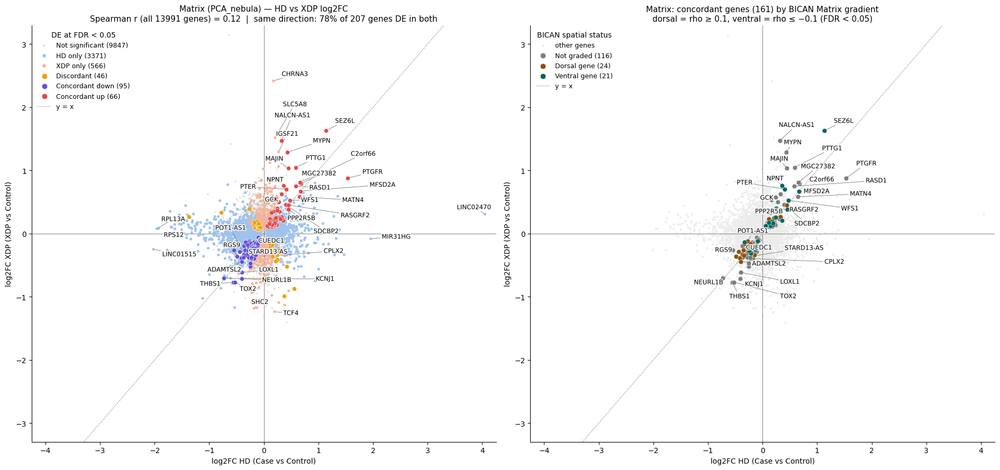

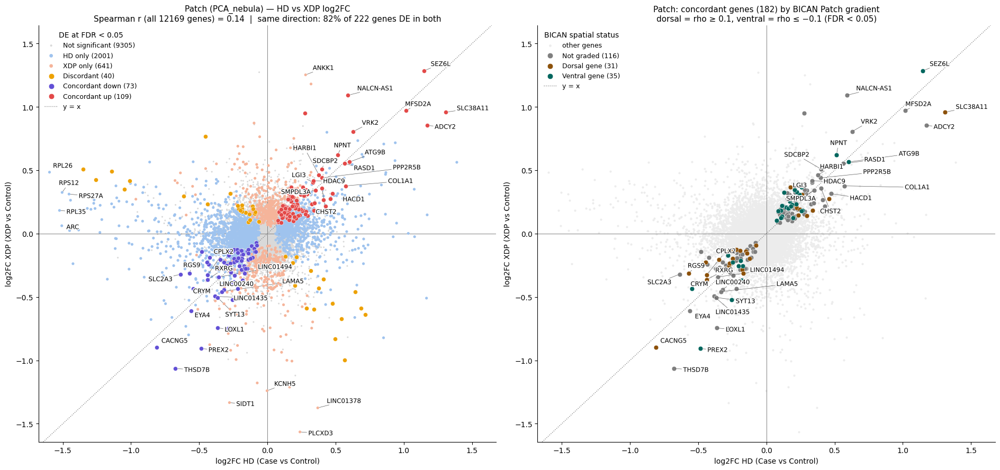

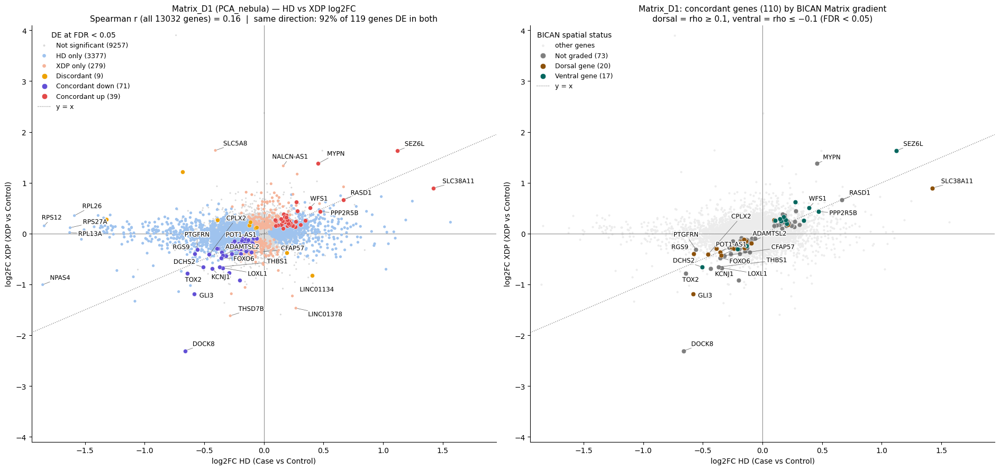

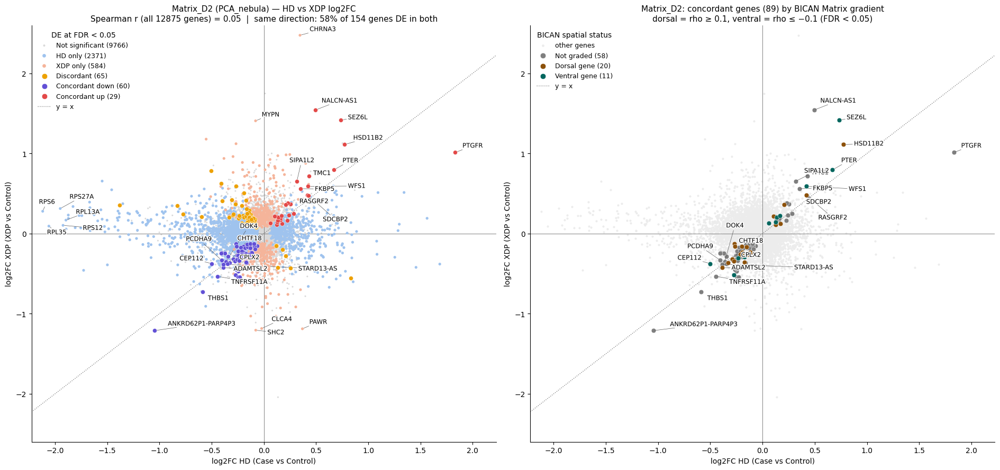

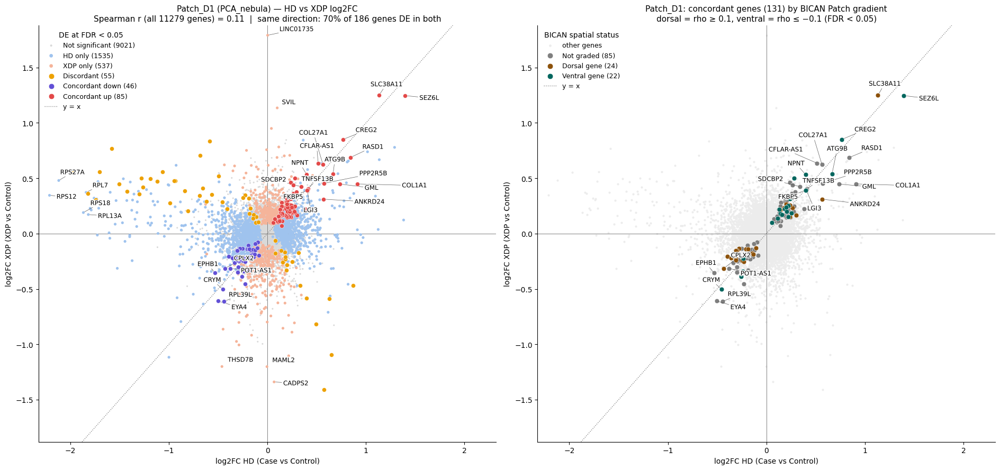

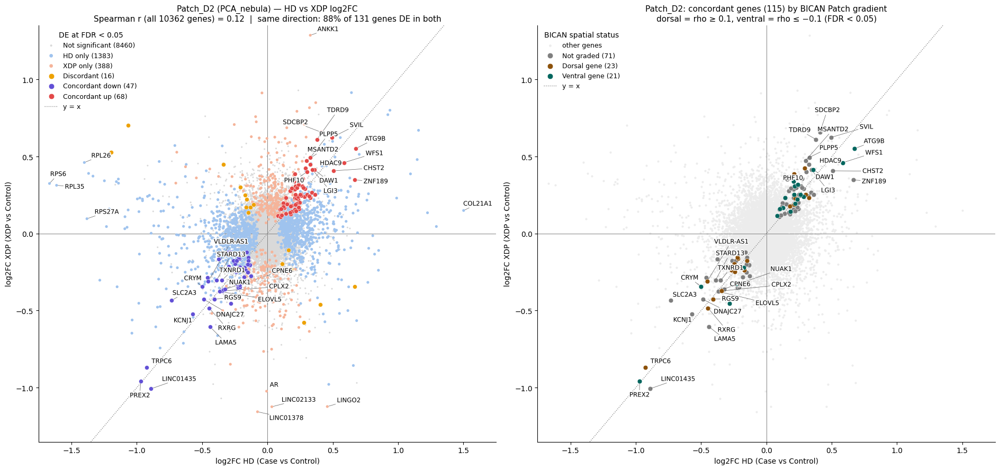

In [24]:
# ── HD vs XDP log2FC scatter + spatial status of the concordant genes ──
import matplotlib.patheffects as pe
from scipy.stats import spearmanr

PADJ            = 0.05   # FDR threshold to call a gene DE in one dataset
LOGFC_LABEL_THR = 0.3    # concordant genes are labelled only if |log2FC| >= this in BOTH datasets
N_LABEL_MAX     = 40     # max number of concordant genes labelled (most robust first)
N_LABEL_ONLY    = 5      # also label the N most extreme HD-only and XDP-only genes (by |log2FC|)

# BICAN spatial gradient: rho > 0 = higher DORSALLY, rho < 0 = higher VENTRALLY
GRAD_PADJ_THR, GRAD_RHO_THR = 0.05, 0.10
bican = pd.read_csv("/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/genes_correlation/df_corr.csv", index_col=0)

# category -> (color, dot size). Listed in DRAWING order: background first, shared DEGs on top.
STYLE = {
    "Not significant": ("#d9d9d9", 5),
    "HD only":         ("#9fc3ee", 14),
    "XDP only":        ("#f5b49a", 14),
    "Discordant":      ("#eda100", 34),
    "Concordant down": ("#6250d6", 34),
    "Concordant up":   ("#e34948", 34),
}
SPATIAL_STYLE = {"Not graded": "#7f7f7f", "Dorsal gene": "#8c510a", "Ventral gene": "#01665e"}


def add_labels(ax, genes_df):
    # Gene names with a white outline (readable over dots), moved apart by adjust_text.
    texts = [ax.text(r.logFC_HD, r.logFC_XDP, r.gene, fontsize=8.5, zorder=10,
                     path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
             for r in genes_df.itertuples()]
    adjust_text(texts, ax=ax, expand=(1.3, 1.6), arrowprops=dict(arrowstyle="-", color="#555555", lw=0.5))


def add_reference_lines(ax, xlim, ylim):
    # Axes at 0 and the identity line (same log2FC in both diseases).
    ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)
    ax.axhline(0, color="grey", lw=0.7, zorder=0); ax.axvline(0, color="grey", lw=0.7, zorder=0)
    lim = min(xlim, ylim)
    ax.plot([-lim, lim], [-lim, lim], ls=":", color="grey", lw=1, zorder=0, label="y = x")
    ax.set_xlabel("log2FC HD (Case vs Control)")
    ax.set_ylabel("log2FC XDP (XDP vs Control)")
    sns.despine(ax=ax)


for ct in ct_to_investigate:

    # 1) Load both DE tables and match genes on Ensembl gene_id ("Gene matching" cell above):
    #    shared genes only, XDP gene names, BH-FDR recomputed on the shared genes
    df = match_hd_xdp(read_de("HD", method, ct), read_de("XDP", method, ct), label=ct)

    # 2) Category of each gene
    sig_hd, sig_xdp = df["padj_HD"] < PADJ, df["padj_XDP"] < PADJ
    same_sign = np.sign(df["logFC_HD"]) == np.sign(df["logFC_XDP"])
    df["category"] = np.select(
        [sig_hd & sig_xdp & same_sign & (df["logFC_HD"] > 0),
         sig_hd & sig_xdp & same_sign & (df["logFC_HD"] < 0),
         sig_hd & sig_xdp & ~same_sign,
         sig_hd,
         sig_xdp],
        ["Concordant up", "Concordant down", "Discordant", "HD only", "XDP only"],
        default="Not significant")

    # 3) Spatial status from BICAN (Matrix* -> Matrix rho, Patch* -> Patch rho)
    comp = "Matrix" if ct.startswith("Matrix") else "Patch"
    df = df.merge(bican[[f"rho_{comp}", f"padj_{comp}"]].rename(columns={f"rho_{comp}": "rho", f"padj_{comp}": "padj_grad"}),
                  left_on="gene", right_index=True, how="left")
    is_grad = (df["padj_grad"] < GRAD_PADJ_THR) & (df["rho"].abs() >= GRAD_RHO_THR)
    df["spatial"] = np.select([is_grad & (df["rho"] > 0), is_grad & (df["rho"] < 0)],
                              ["Dorsal gene", "Ventral gene"], default="Not graded")

    # 4) Genes to label
    concordant = df[df["category"].isin(["Concordant up", "Concordant down"])]
    big_enough = (concordant["logFC_HD"].abs() >= LOGFC_LABEL_THR) & (concordant["logFC_XDP"].abs() >= LOGFC_LABEL_THR)
    lab_conc = (concordant[big_enough]
                .assign(score=lambda x: x[["padj_HD", "padj_XDP"]].max(axis=1))   # weaker FDR of the two = robust in BOTH
                .nsmallest(N_LABEL_MAX, "score"))
    lab_hd  = df[df["category"] == "HD only"].assign(score=lambda x: x["logFC_HD"].abs()).nlargest(N_LABEL_ONLY, "score")
    lab_xdp = df[df["category"] == "XDP only"].assign(score=lambda x: x["logFC_XDP"].abs()).nlargest(N_LABEL_ONLY, "score")

    xlim = df["logFC_HD"].abs().max() * 1.05
    ylim = df["logFC_XDP"].abs().max() * 1.05
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(19, 9))

    # ── LEFT: all genes, colored by DE category ──
    for z, (cat, (color, size)) in enumerate(STYLE.items()):
        s = df[df["category"] == cat]
        ax1.scatter(s["logFC_HD"], s["logFC_XDP"], s=size, color=color,
                    edgecolor="white" if size > 20 else "none", linewidth=0.4,   # white ring separates overlapping big dots
                    label=f"{cat} ({len(s)})", zorder=z, rasterized=(cat == "Not significant"))
    add_reference_lines(ax1, xlim, ylim)
    add_labels(ax1, pd.concat([lab_conc, lab_hd, lab_xdp]))

    r_all = spearmanr(df["logFC_HD"], df["logFC_XDP"])[0]
    n_both = df["category"].isin(["Concordant up", "Concordant down", "Discordant"]).sum()
    pct_same = 100 * len(concordant) / n_both if n_both else np.nan
    ax1.set_title(f"{ct} ({method}) — HD vs XDP log2FC\n"
                  f"Spearman r (all {len(df)} genes) = {r_all:.2f}  |  same direction: {pct_same:.0f}% of {n_both} genes DE in both",
                  fontsize=11)
    ax1.legend(title=f"DE at FDR < {PADJ}", loc="upper left", frameon=False, fontsize=9, markerscale=1.3)

    # ── RIGHT: only concordant genes, colored by BICAN spatial status ──
    ax2.scatter(df["logFC_HD"], df["logFC_XDP"], s=4, color="#ececec", zorder=0, rasterized=True, label="other genes")
    for z, (sp, color) in enumerate(SPATIAL_STYLE.items(), start=1):
        s = concordant[concordant["spatial"] == sp]
        ax2.scatter(s["logFC_HD"], s["logFC_XDP"], s=40, color=color, edgecolor="white", linewidth=0.4,
                    zorder=z, label=f"{sp} ({len(s)})")
    add_reference_lines(ax2, xlim, ylim)
    add_labels(ax2, lab_conc)

    ax2.set_title(f"{ct}: concordant genes ({len(concordant)}) by BICAN {comp} gradient\n"
                  f"dorsal = rho ≥ {GRAD_RHO_THR}, ventral = rho ≤ −{GRAD_RHO_THR} (FDR < {GRAD_PADJ_THR})",
                  fontsize=11)
    ax2.legend(title="BICAN spatial status", loc="upper left", frameon=False, fontsize=9, markerscale=1.2)

    plt.tight_layout()
    plt.show()


---
# Part 2 — Deeper comparison of the DEGs: HD (Handsaker village) vs XDP (NucSeq)

Part 1 (above) shows one logFC–logFC scatter per cell type. Here the same DE tables are investigated further:

1. **Overview**: how similar are the HD and XDP DEGs, for each cell type and DE method?
2. **Methods**: how much do the results change between `baseline_nebula` and `PCA_nebula`?
3. **Gene categories**: which genes are *concordant up*, *concordant down*, *discordant*, or specific to one disease? (bar plots with readable gene names)
4. **Spatial genes**: are the DEGs dorsal–ventral gradient genes in healthy BICAN tissue? What happens when each DE list is plotted against the BICAN gradient score (rho)?
5. **GSEA** on both DE lists separately, then a comparison of the pathways. Also ORA on the concordant genes.
6. **Summary**: key numbers and interpretation.

**Conventions used throughout**
- `logFC` = log2 fold change, disease vs control (HD Case vs Control; XDP vs Control). The formatted tables are already in log2.
- `padj` = BH-FDR recomputed on all genes in each table (as in Part 1). A gene is **DE in a dataset** if `padj < PADJ_THR`.
- Only genes tested in **both** datasets are compared (inner join).
- **BICAN rho** = Spearman correlation (meta-analysed across healthy BICAN donors) between a gene's expression and the spline position `r` along the striatum, computed separately in Matrix and Patch MSNs (`genes_correlation/df_corr.csv`).
  **rho > 0 → gene is higher DORSALLY, rho < 0 → gene is higher VENTRALLY.** This sign is consistent with known markers (CNR1, dorsolateral: rho = +0.42; CRYM, ventromedial: rho = −0.49) and with the gradient notebook ("HIGH in DORSAL Matrix+Patch (rho>0)").
  A gene is a **gradient gene** if `padj_grad < 0.05` and `|rho| ≥ 0.1`.
- Matrix / Matrix_D1 / Matrix_D2 DEGs are matched with the BICAN **Matrix** rho, and Patch* DEGs with the BICAN **Patch** rho.

In [ ]:
# ── Extra imports for Part 2 ──
import os
import re
import textwrap
import gseapy as gp
from scipy.stats import spearmanr, binomtest, fisher_exact

# ── Parameters ──
METHODS      = ["PCA_nebula", "baseline_nebula"]  # DE methods to compare (HD baseline exists only for the D1/D2 subtypes)
CT_ALL       = ct_to_investigate                  # all MSN cell types defined at the top
CT_FOCUS     = ["Matrix", "Patch"]                # cell types used for the gene-level plots
METHOD_FOCUS = method                             # method used for the gene-level plots (set at the top of the notebook)

PADJ_THR  = 0.05   # FDR threshold to call a gene DE in one dataset
LOGFC_MIN = 0.0    # optional extra |log2FC| threshold (0 = FDR only)

GRAD_PADJ_THR = 0.05  # BICAN: FDR threshold to call a gene spatially graded
GRAD_RHO_THR  = 0.10  # BICAN: |rho| threshold to call a gene spatially graded (same GRAD_THR used in the DEG notebooks)

N_TOP = 20  # number of genes shown per category in the bar plots

HD_DIR     = "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG"
XDP_DIR    = "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum"
BICAN_CORR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/genes_correlation/df_corr.csv"
OUT_DIR    = f"{HD_DIR}/compare_HD_vs_XDP/{METHOD_FOCUS}"   # gene lists and GSEA tables are saved here
os.makedirs(OUT_DIR, exist_ok=True)

# ── Colors (same meaning in every plot) ──
COL_DATASET = {"HD": "#2a78d6", "XDP": "#eb6834"}            # blue = HD, orange = XDP
CATEGORIES  = ["Concordant up", "Concordant down", "Discordant", "HD only", "XDP only", "Not significant"]
COL_CAT     = {"Concordant up": "#e34948", "Concordant down": "#6250d6", "Discordant": "#eda100",
               "HD only": "#9fc3ee", "XDP only": "#f5b49a", "Not significant": "#dddddd"}
COL_DORSAL, COL_VENTRAL = "#8c510a", "#01665e"                # brown = dorsal gene, teal = ventral gene

## 1. Load the DE tables and the BICAN spatial gradient

For every (method, cell type) pair we build one table with, per gene:
`logFC_HD, padj_HD, logFC_XDP, padj_XDP`, the **category**, and the BICAN `rho` of the matching compartment.

HD and XDP genes are matched with `match_hd_xdp` (exact Ensembl gene_id; see *Gene matching* at the top). `padj` = BH-FDR on the genes shared by the two datasets. BICAN rho is joined by gene name; genes absent from BICAN count as "Not graded".

**Categories**, using DE = `padj < PADJ_THR` in that dataset:

| category | definition |
|---|---|
| Concordant up | DE in both, logFC > 0 in both |
| Concordant down | DE in both, logFC < 0 in both |
| Discordant | DE in both, opposite sign |
| HD only / XDP only | DE in only one dataset |
| Not significant | DE in neither |

In [ ]:
def compartment(ct):
    # Which BICAN rho to use for a cell type: Matrix* -> Matrix, Patch* -> Patch.
    return "Matrix" if ct.startswith("Matrix") else "Patch"


# BICAN healthy spatial gradient (one row per gene)
bican = pd.read_csv(BICAN_CORR, index_col=0)


def load_pair(method, ct):
    # Merge HD and XDP results for one cell type, add category + BICAN gradient info.
    # Genes matched on Ensembl gene_id, XDP names, BH-FDR on the shared genes ("Gene matching" cell at the top).
    df = match_hd_xdp(read_de("HD", method, ct), read_de("XDP", method, ct), label=f"{method} {ct}")

    # 1) DE calls and category
    df["sig_HD"]  = (df["padj_HD"]  < PADJ_THR) & (df["logFC_HD"].abs()  >= LOGFC_MIN)
    df["sig_XDP"] = (df["padj_XDP"] < PADJ_THR) & (df["logFC_XDP"].abs() >= LOGFC_MIN)
    both      = df["sig_HD"] & df["sig_XDP"]
    same_sign = np.sign(df["logFC_HD"]) == np.sign(df["logFC_XDP"])
    df["category"] = np.select(
        [both & same_sign & (df["logFC_HD"] > 0),
         both & same_sign & (df["logFC_HD"] < 0),
         both & ~same_sign,
         df["sig_HD"],
         df["sig_XDP"]],
        ["Concordant up", "Concordant down", "Discordant", "HD only", "XDP only"],
        default="Not significant")

    # 2) BICAN gradient of the matching compartment
    comp = compartment(ct)
    grad = bican[[f"rho_{comp}", f"padj_{comp}"]].rename(columns={f"rho_{comp}": "rho", f"padj_{comp}": "padj_grad"})
    df = df.merge(grad, left_on="gene", right_index=True, how="left")
    is_grad = (df["padj_grad"] < GRAD_PADJ_THR) & (df["rho"].abs() >= GRAD_RHO_THR)
    df["spatial"] = np.select([is_grad & (df["rho"] > 0), is_grad & (df["rho"] < 0)],
                              ["Dorsal gene", "Ventral gene"], default="Not graded")
    return df


# Load every available (method, cell type) pair
pairs = {}
for m in METHODS:
    for ct in CT_ALL:
        try:
            pairs[(m, ct)] = load_pair(m, ct)
        except FileNotFoundError:
            print(f"skip {m:16s} {ct:10s} -> DE table missing in one of the datasets")

print(f"\nLoaded {len(pairs)} (method, cell type) pairs")
pairs[(METHOD_FOCUS, CT_FOCUS[0])].sort_values("padj_HD").head()

skip baseline_nebula  Matrix     -> DE table missing in one of the datasets
skip baseline_nebula  Patch      -> DE table missing in one of the datasets

Loaded 10 (method, cell type) pairs


,gene,logFC_HD,p_HD,padj_HD,logFC_XDP,p_XDP,padj_XDP,sig_HD,sig_XDP,category,rho,padj_grad,spatial
0,CREM,-0.274066,1.735981e-20,3.695036e-16,0.031483,0.542956,0.805112,True,False,HD only,0.100556,2.400668e-15,Dorsal gene
1,CRYM,-0.683682,2.251796e-17,2.396474e-13,-0.293876,0.011448,0.119488,True,False,HD only,-0.486930,5.822740e-78,Ventral gene
2,NAV2,-0.310249,1.227111e-14,6.529762e-11,-0.073069,0.120610,0.414060,True,False,HD only,0.058778,3.450141e-02,Not graded
3,LINC01250,-0.440018,2.242791e-14,7.956301e-11,-0.106436,0.229089,0.561027,True,False,HD only,0.119070,2.430306e-11,Dorsal gene
4,WWC1,-0.566443,2.185526e-14,7.956301e-11,0.048996,0.560501,0.814282,True,False,HD only,0.241893,3.309881e-30,Dorsal gene


## 2. Overview: how similar are the HD and XDP DEGs?

One row per (method, cell type):
- `n_sig_HD`, `n_sig_XDP`: number of DE genes in each dataset. HD has many more donors, so it has more power and more DE genes.
- `n_both`: DE in both. `pct_concordant`: % of those with the same direction.
- `binom_p`: binomial test of `pct_concordant` against 50% (the expectation if the directions were unrelated).
- `r_all`: Spearman correlation of logFC_HD vs logFC_XDP over **all** shared genes. `r_DE`: the same, restricted to genes DE in at least one dataset.

In [ ]:
rows = []
for (m, ct), df in pairs.items():
    n_cat  = df["category"].value_counts()
    n_conc = n_cat.get("Concordant up", 0) + n_cat.get("Concordant down", 0)
    n_both = n_conc + n_cat.get("Discordant", 0)
    de_any = df["category"] != "Not significant"
    rows.append({
        "method": m, "cell_type": ct, "n_genes": len(df),
        "n_sig_HD": df["sig_HD"].sum(), "n_sig_XDP": df["sig_XDP"].sum(),
        "n_both": n_both,
        "conc_up": n_cat.get("Concordant up", 0), "conc_down": n_cat.get("Concordant down", 0),
        "discordant": n_cat.get("Discordant", 0),
        "pct_concordant": 100 * n_conc / n_both if n_both else np.nan,
        "binom_p": binomtest(n_conc, n_both, 0.5, alternative="greater").pvalue if n_both else np.nan,
        "r_all": spearmanr(df["logFC_HD"], df["logFC_XDP"])[0],
        "r_DE":  spearmanr(df.loc[de_any, "logFC_HD"], df.loc[de_any, "logFC_XDP"])[0],
    })
overview = pd.DataFrame(rows)
overview.to_csv(f"{OUT_DIR}/overview_concordance.csv", index=False)
overview.style.format({"pct_concordant": "{:.0f}", "binom_p": "{:.1e}", "r_all": "{:.2f}", "r_DE": "{:.2f}"})

,method,cell_type,n_genes,n_sig_HD,n_sig_XDP,n_both,conc_up,conc_down,discordant,pct_concordant,binom_p,r_all,r_DE
0,PCA_nebula,Matrix,13991,3578,773,207,66,95,46,78,1.9e-16,0.12,0.18
1,PCA_nebula,Patch,12169,2223,863,222,109,73,40,82,3.9e-23,0.14,0.27
2,PCA_nebula,Matrix_D1,13032,3496,398,119,39,71,9,92,1.6e-23,0.16,0.23
3,PCA_nebula,Matrix_D2,12875,2525,738,154,29,60,65,58,3.2e-02,0.05,0.06
4,PCA_nebula,Patch_D1,11279,1721,723,186,85,46,55,70,1.2e-08,0.11,0.16
5,PCA_nebula,Patch_D2,10362,1514,519,131,68,47,16,88,5.9e-20,0.12,0.27
6,baseline_nebula,Matrix_D1,13032,5038,2404,1024,545,313,166,84,2.8e-113,0.26,0.35
7,baseline_nebula,Matrix_D2,12875,4095,2354,790,313,292,185,77,4.0e-53,0.25,0.36
8,baseline_nebula,Patch_D1,11279,3790,645,276,165,74,37,87,1.2e-37,0.25,0.31
9,baseline_nebula,Patch_D2,10362,2301,515,163,91,61,11,93,3.5e-33,0.29,0.46


**Plot — overview of HD/XDP agreement.**
- *Left*: Spearman correlation of logFC over all shared genes, per cell type and method. 0 = unrelated, 1 = identical.
- *Middle*: among genes DE in both diseases, the % that move in the same direction. The dashed line at 50% is chance.
- *Right*: number of genes per category for `METHOD_FOCUS` ("Not significant" omitted).

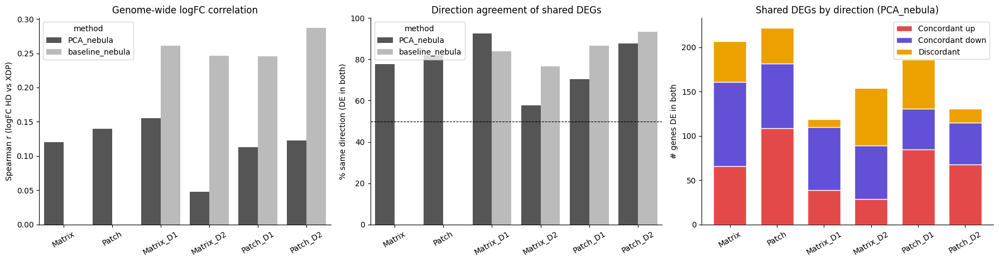

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Left + middle: one bar per method for each cell type
sns.barplot(data=overview, x="cell_type", y="r_all", hue="method", ax=axes[0], palette=["#555555", "#bbbbbb"])
axes[0].set_ylabel("Spearman r (logFC HD vs XDP)"); axes[0].set_title("Genome-wide logFC correlation")

sns.barplot(data=overview, x="cell_type", y="pct_concordant", hue="method", ax=axes[1], palette=["#555555", "#bbbbbb"])
axes[1].axhline(50, color="black", ls="--", lw=0.8)
axes[1].set_ylim(0, 100); axes[1].set_ylabel("% same direction (DE in both)"); axes[1].set_title("Direction agreement of shared DEGs")

# Right: stacked category counts for the focus method
counts = (overview[overview["method"] == METHOD_FOCUS]
          .set_index("cell_type")[["conc_up", "conc_down", "discordant"]]
          .rename(columns={"conc_up": "Concordant up", "conc_down": "Concordant down", "discordant": "Discordant"}))
counts.plot.bar(stacked=True, ax=axes[2], color=[COL_CAT[c] for c in counts.columns], edgecolor="white", width=0.7)
axes[2].set_ylabel("# genes DE in both"); axes[2].set_title(f"Shared DEGs by direction ({METHOD_FOCUS})")

for ax in axes:
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
    sns.despine(ax=ax)
plt.tight_layout(); plt.show()

## 3. Methods: `baseline_nebula` vs `PCA_nebula`

`PCA_nebula` adds the healthy-derived PCs as covariates, so it removes variation that is also present among controls (e.g. sampling position, dissection, cell state). For HD, `baseline_nebula` exists only for the D1/D2 subtypes, so the comparison is limited to those.

**Plot — same disease, two methods.** Each dot is a gene: x = logFC with `baseline_nebula`, y = logFC with `PCA_nebula`. On the diagonal = unchanged by the correction; flatter than the diagonal = the effect shrinks with PCA. Title: Spearman r, # DE genes in each method, and how many PCA DEGs were already DE in baseline.

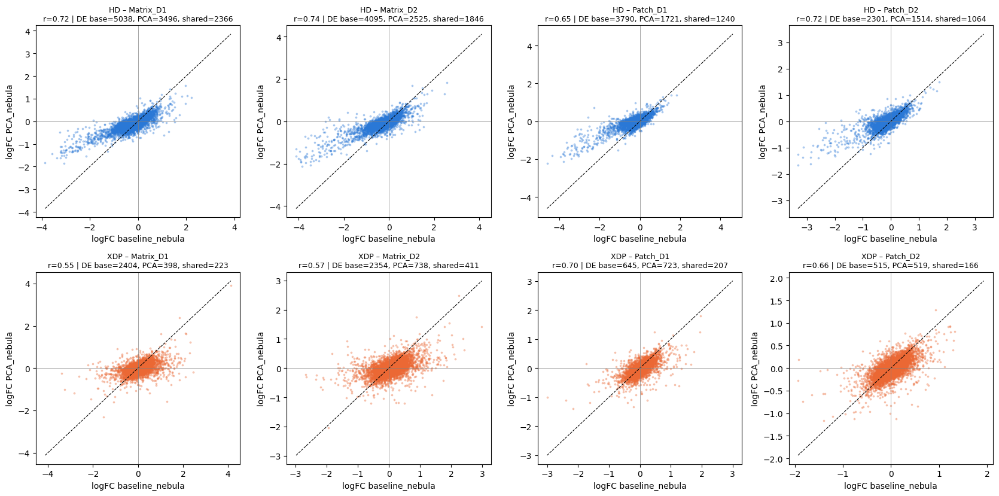

,dataset,cell_type,r_logFC,n_DE_baseline,n_DE_PCA,n_DE_both_methods
0,HD,Matrix_D1,0.722199,5038,3496,2366
1,XDP,Matrix_D1,0.546223,2404,398,223
2,HD,Matrix_D2,0.744667,4095,2525,1846
3,XDP,Matrix_D2,0.572577,2354,738,411
4,HD,Patch_D1,0.645100,3790,1721,1240
5,XDP,Patch_D1,0.702875,645,723,207
6,HD,Patch_D2,0.719442,2301,1514,1064
7,XDP,Patch_D2,0.664827,515,519,166


In [ ]:
cts_both_methods = [ct for ct in CT_ALL if ("baseline_nebula", ct) in pairs and ("PCA_nebula", ct) in pairs]

fig, axes = plt.subplots(2, len(cts_both_methods), figsize=(4.2 * len(cts_both_methods), 8.4), squeeze=False)
rows = []
for j, ct in enumerate(cts_both_methods):
    m = pairs[("baseline_nebula", ct)].merge(pairs[("PCA_nebula", ct)], on="gene", suffixes=("_base", "_pca"))
    for i, ds in enumerate(["HD", "XDP"]):
        ax = axes[i, j]
        x, y = m[f"logFC_{ds}_base"], m[f"logFC_{ds}_pca"]
        sig_base, sig_pca = m[f"sig_{ds}_base"], m[f"sig_{ds}_pca"]
        r = spearmanr(x, y)[0]
        ax.scatter(x, y, s=3, color=COL_DATASET[ds], alpha=0.3)
        lim = np.nanmax(np.abs(np.r_[x, y]))
        ax.plot([-lim, lim], [-lim, lim], color="black", lw=0.8, ls="--")   # identity line
        ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
        ax.set_title(f"{ds} – {ct}\nr={r:.2f} | DE base={sig_base.sum()}, PCA={sig_pca.sum()}, shared={(sig_base & sig_pca).sum()}", fontsize=9)
        ax.set_xlabel("logFC baseline_nebula"); ax.set_ylabel("logFC PCA_nebula")
        rows.append({"dataset": ds, "cell_type": ct, "r_logFC": r,
                     "n_DE_baseline": sig_base.sum(), "n_DE_PCA": sig_pca.sum(), "n_DE_both_methods": (sig_base & sig_pca).sum()})
plt.tight_layout(); plt.show()

method_cmp = pd.DataFrame(rows)
method_cmp

## 4. Gene categories (focus cell types, `METHOD_FOCUS`)

The full category tables are saved to `OUT_DIR/genes_<ct>.csv`.

**Plot — number of genes per category.** Note the asymmetry between HD-only and XDP-only: part of it is power (HD has more donors).

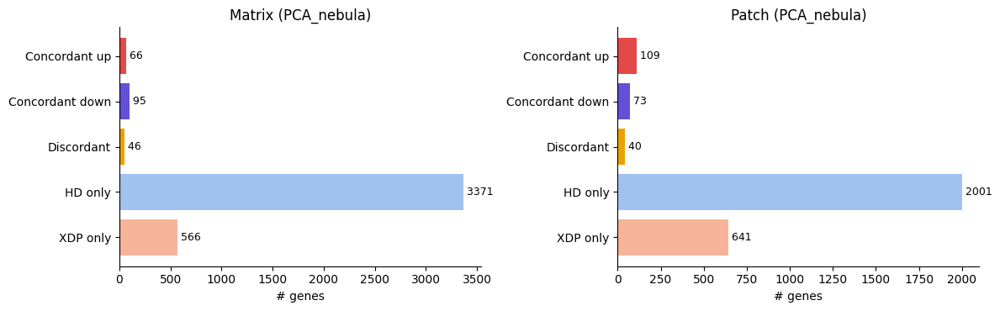

In [ ]:
fig, axes = plt.subplots(1, len(CT_FOCUS), figsize=(6 * len(CT_FOCUS), 3.8), squeeze=False)
for ax, ct in zip(axes[0], CT_FOCUS):
    df = pairs[(METHOD_FOCUS, ct)]
    df.sort_values(["category", "padj_HD"]).to_csv(f"{OUT_DIR}/genes_{ct}.csv", index=False)  # save full table

    n = df["category"].value_counts().reindex(CATEGORIES[:-1]).fillna(0).astype(int)
    ax.barh(n.index[::-1], n.values[::-1], color=[COL_CAT[c] for c in n.index[::-1]])
    for yy, v in enumerate(n.values[::-1]):
        ax.text(v, yy, f" {v}", va="center", fontsize=9)
    ax.set_title(f"{ct} ({METHOD_FOCUS})"); ax.set_xlabel("# genes")
    sns.despine(ax=ax)
plt.tight_layout(); plt.show()

**Plots — top genes per category.** One figure per (cell type, category).
- *Left panel*: log2FC in HD (blue) and XDP (orange) for each gene. For "HD only"/"XDP only" the other bar is not significant and only shows the trend.
- *Right panel*: BICAN rho of the gene in the matching compartment. **Brown = higher dorsally, teal = higher ventrally.** Faded bars are not gradient genes (below the significance/|rho| cut). Dashed lines = ±`GRAD_RHO_THR`.
- Ranking: for the categories DE in both diseases, genes are ranked by the **weaker** of the two FDRs (= most robust in *both*). For the single-disease categories they are ranked by FDR in that disease.

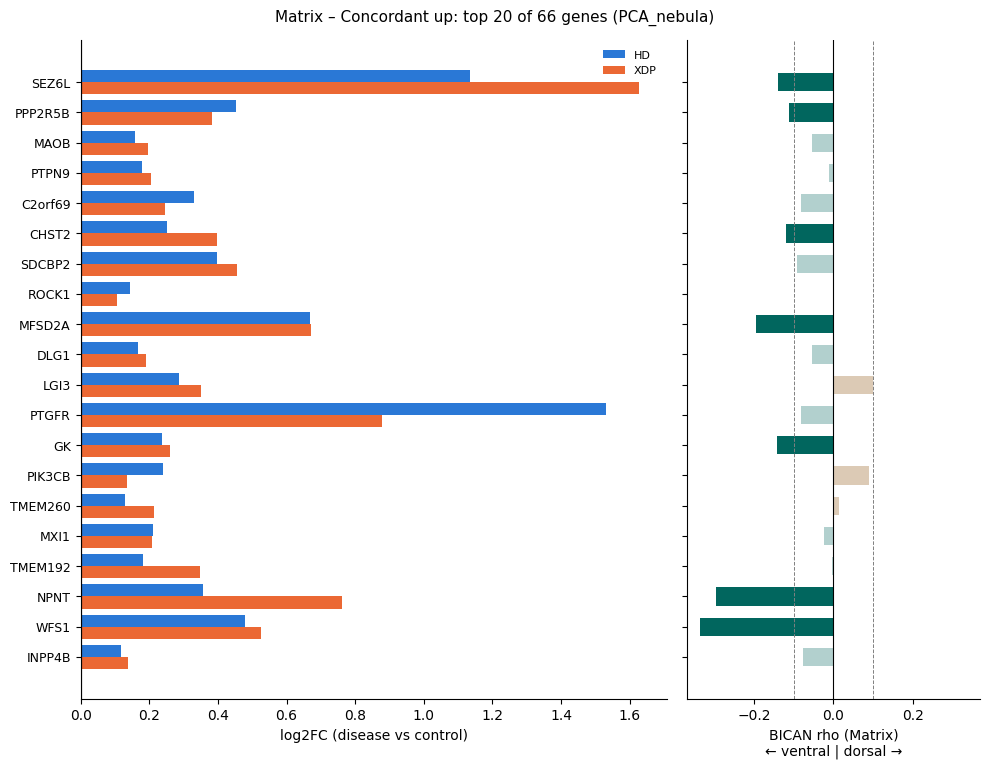

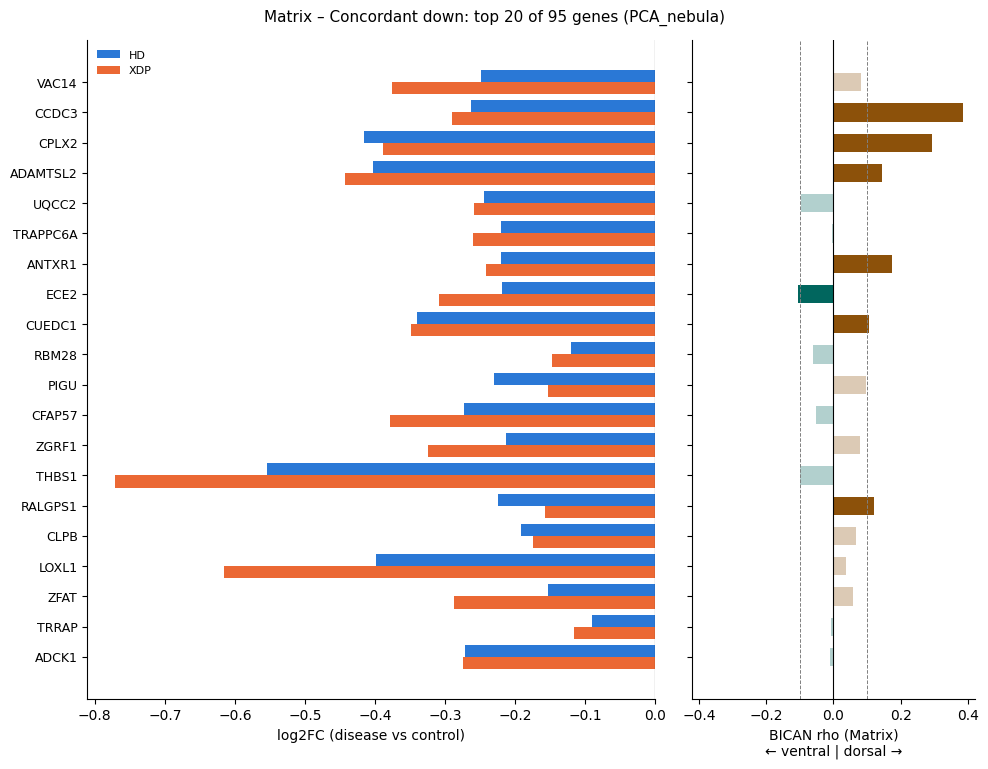

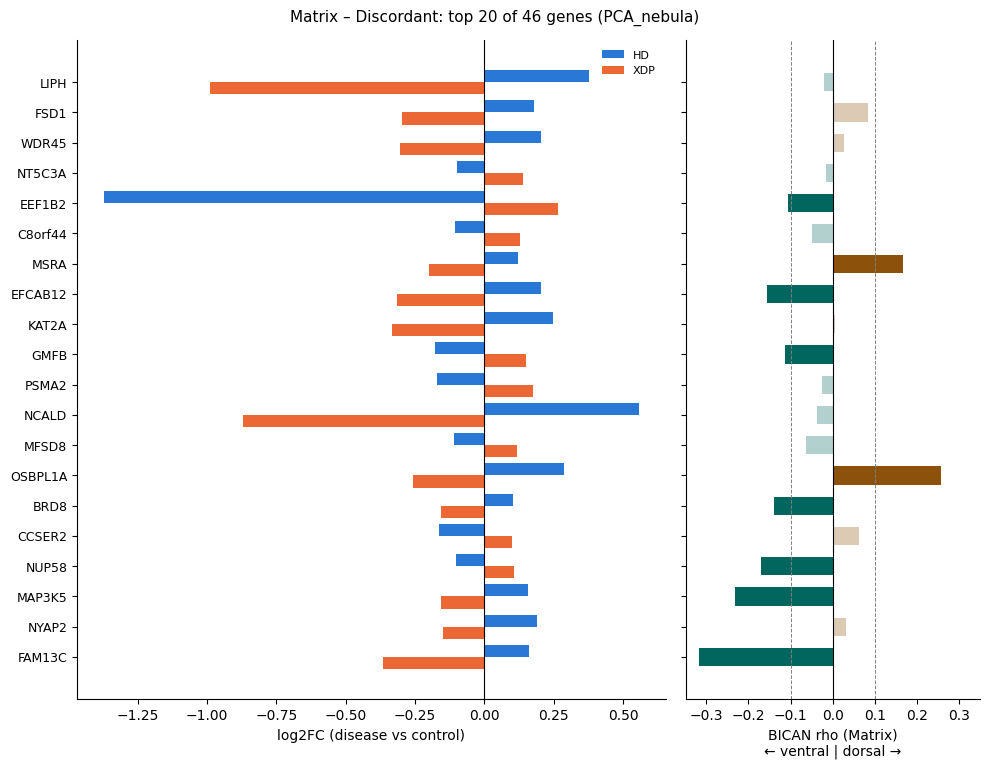

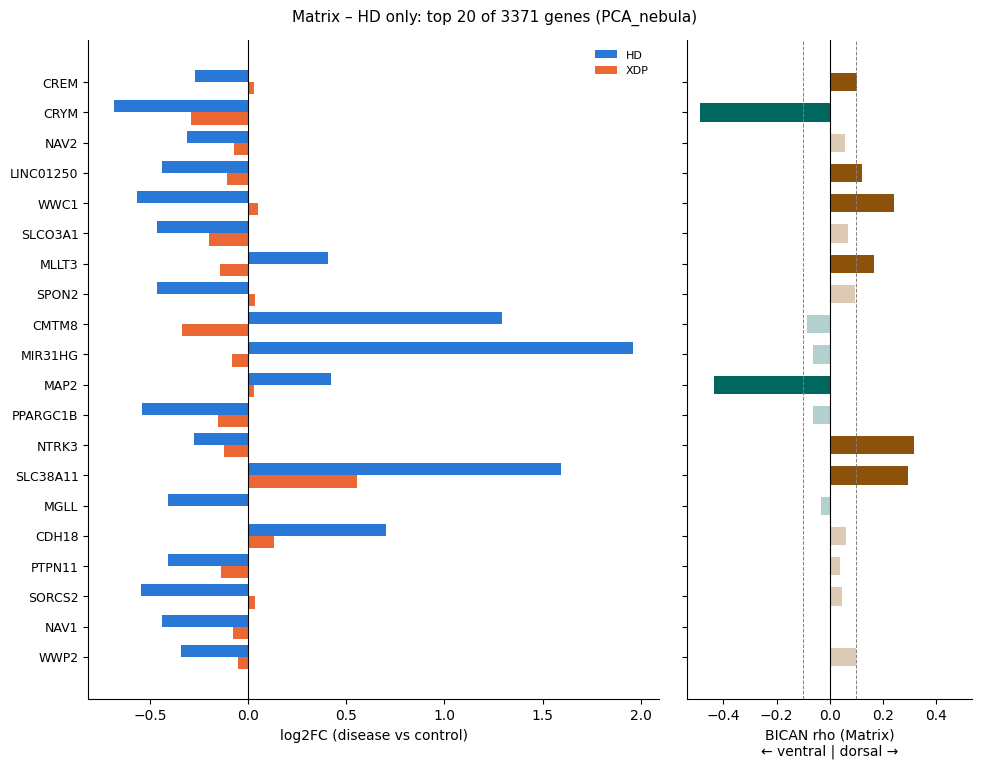

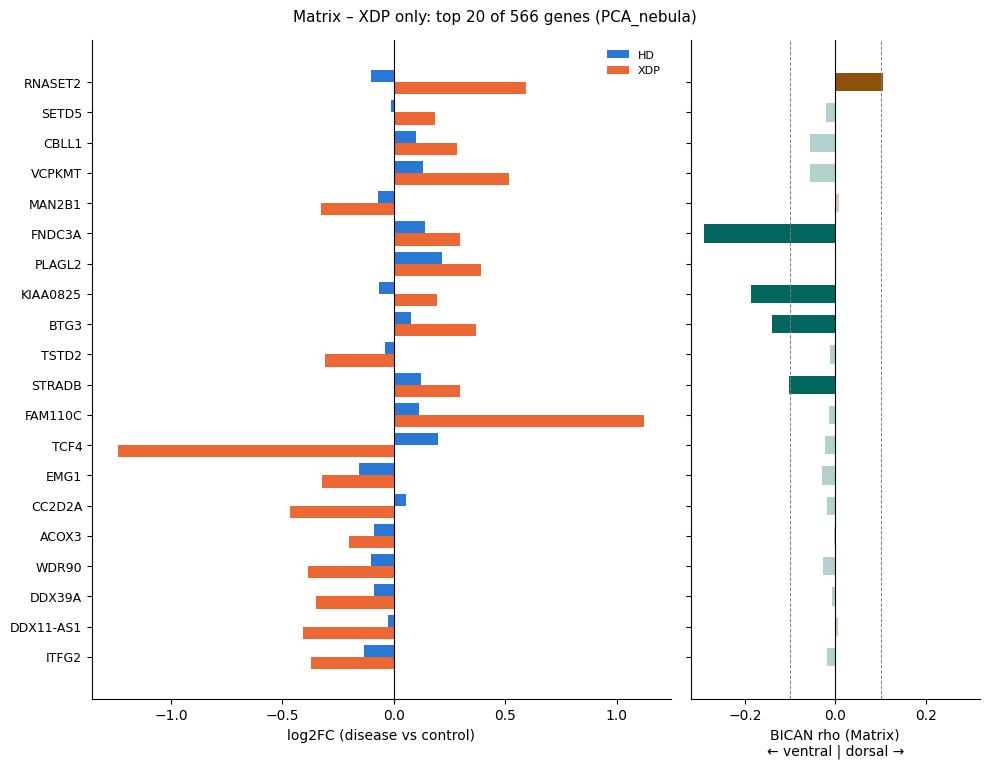

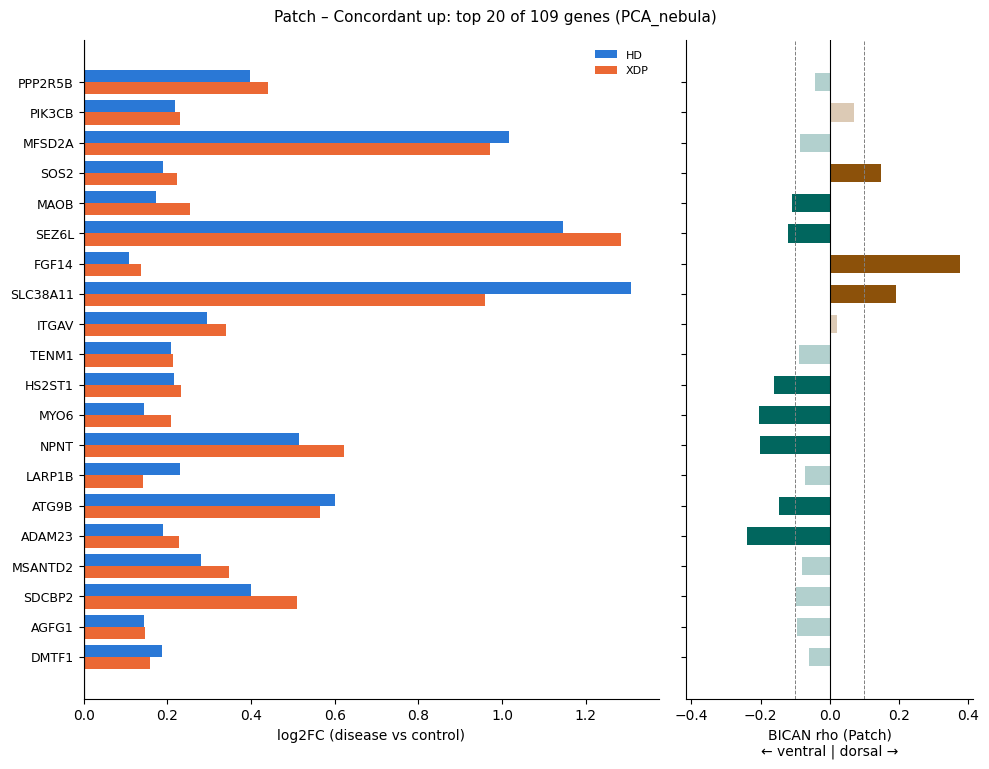

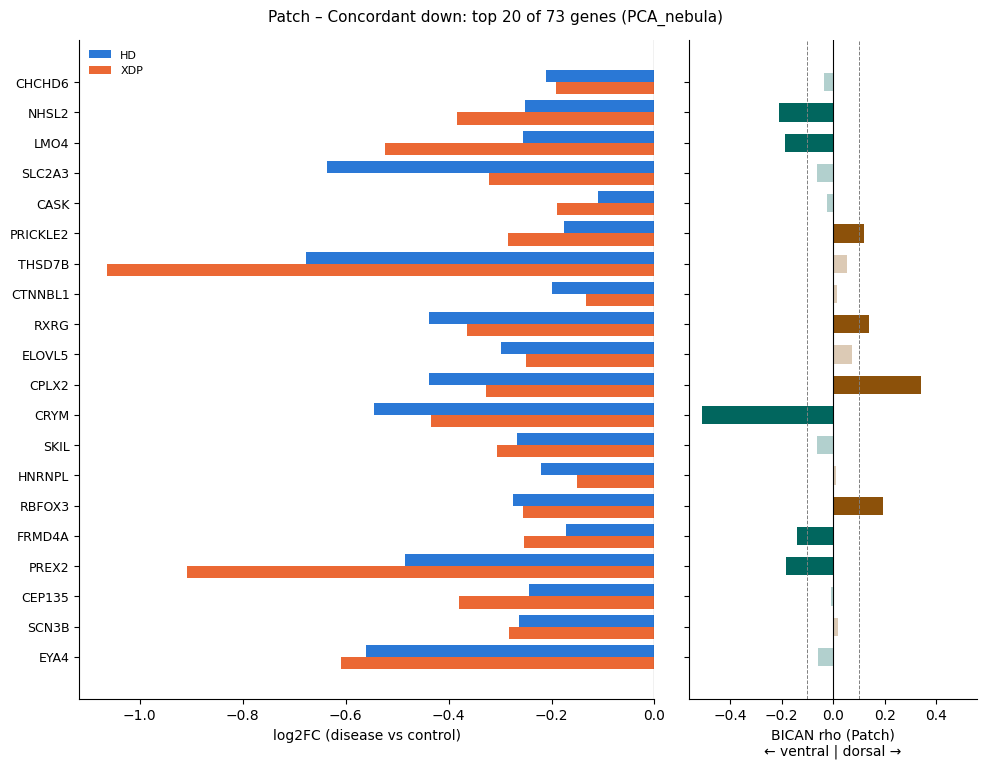

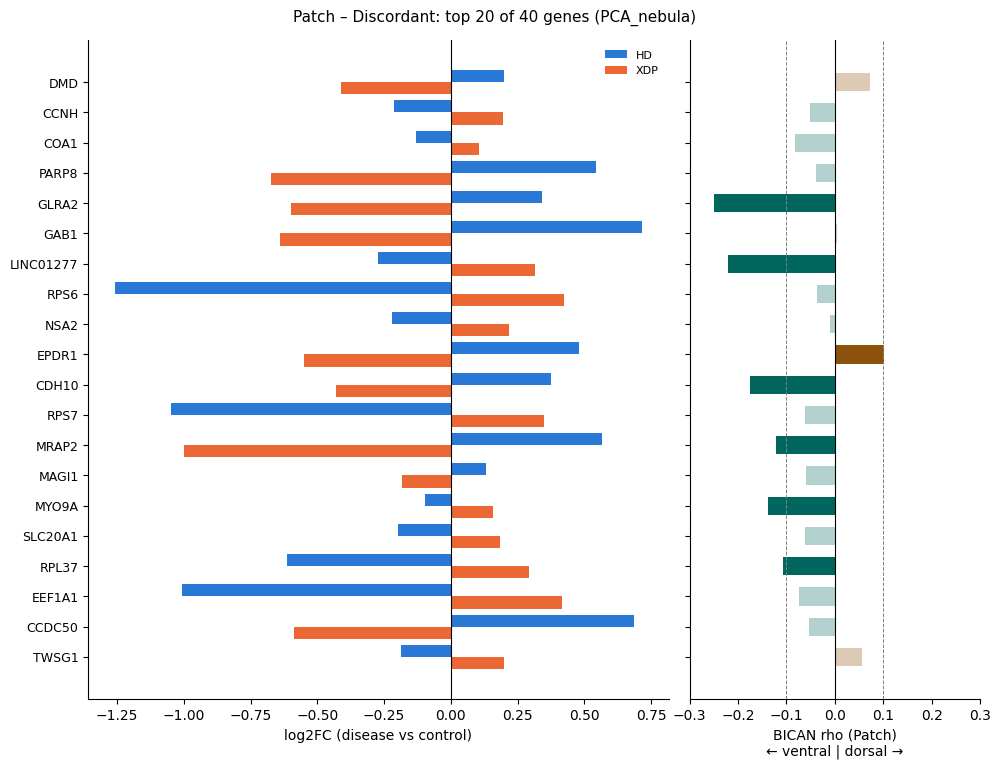

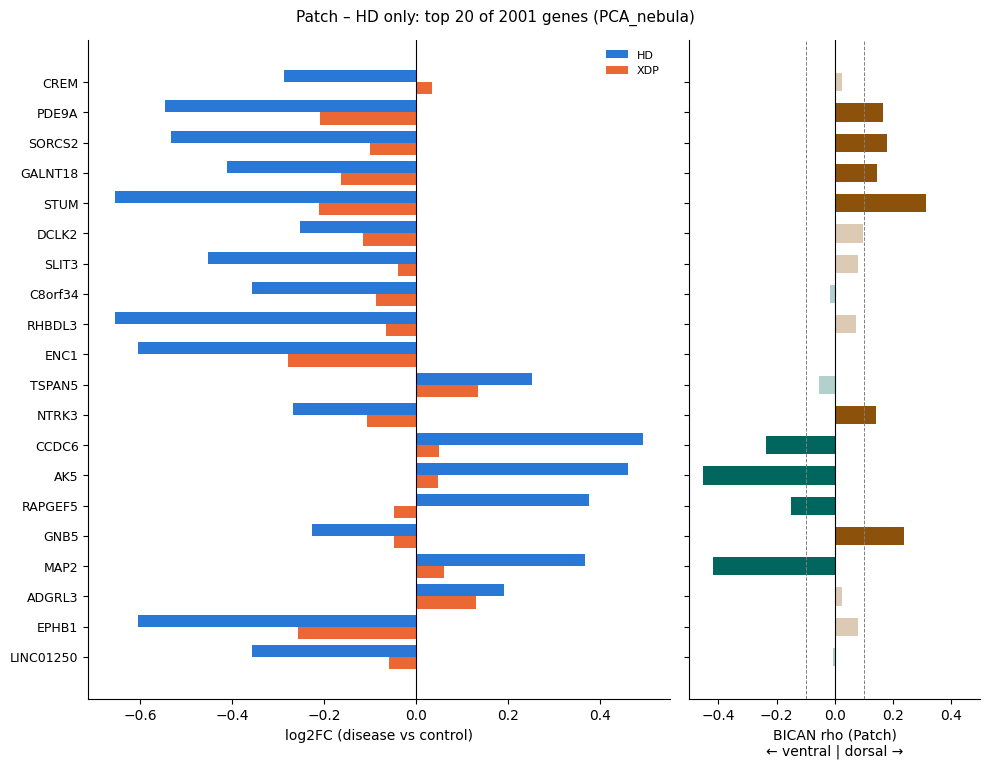

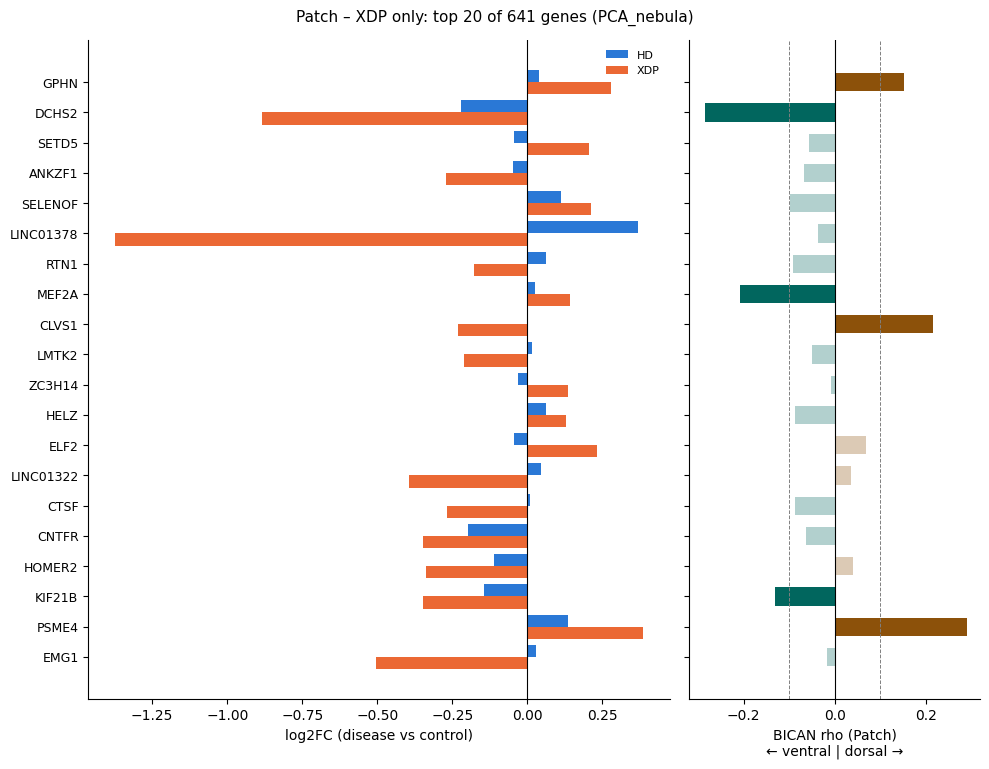

In [ ]:
def plot_category_genes(df, category, ct, n=N_TOP):
    sub = df[df["category"] == category].copy()
    if sub.empty:
        print(f"{ct} – {category}: no genes"); return

    # ranking score (smaller = stronger)
    if category == "HD only":
        sub["rank_p"] = sub["padj_HD"]
    elif category == "XDP only":
        sub["rank_p"] = sub["padj_XDP"]
    else:
        sub["rank_p"] = sub[["padj_HD", "padj_XDP"]].max(axis=1)
    n_total = len(sub)
    sub = sub.nsmallest(n, "rank_p").iloc[::-1]   # reversed so the strongest gene is on top

    y, h = np.arange(len(sub)), 0.4
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 0.3 * len(sub) + 1.8), sharey=True,
                                   gridspec_kw={"width_ratios": [2, 1]})

    # left: logFC in the two diseases
    ax1.barh(y + h / 2, sub["logFC_HD"],  height=h, color=COL_DATASET["HD"],  label="HD")
    ax1.barh(y - h / 2, sub["logFC_XDP"], height=h, color=COL_DATASET["XDP"], label="XDP")
    ax1.axvline(0, color="black", lw=0.8)
    ax1.set_yticks(y); ax1.set_yticklabels(sub["gene"], fontsize=9)
    ax1.set_xlabel("log2FC (disease vs control)"); ax1.legend(loc="best", fontsize=8, frameon=False)

    # right: BICAN gradient (faded if the gene is not a significant gradient gene)
    rho = sub["rho"].fillna(0)
    colors = [COL_DORSAL if r > 0 else COL_VENTRAL for r in rho]
    alphas = np.where(sub["spatial"] == "Not graded", 0.3, 1.0)
    for yy, r, c, a in zip(y, rho, colors, alphas):
        ax2.barh(yy, r, height=0.6, color=c, alpha=a)
    for x in (-GRAD_RHO_THR, GRAD_RHO_THR):
        ax2.axvline(x, color="grey", ls="--", lw=0.7)
    ax2.axvline(0, color="black", lw=0.8)
    lim = max(0.3, rho.abs().max() * 1.1)
    ax2.set_xlim(-lim, lim)
    ax2.set_xlabel(f"BICAN rho ({compartment(ct)})\n← ventral | dorsal →")

    for ax in (ax1, ax2):
        sns.despine(ax=ax)
    fig.suptitle(f"{ct} – {category}: top {len(sub)} of {n_total} genes ({METHOD_FOCUS})", fontsize=11)
    plt.tight_layout(); plt.show()


for ct in CT_FOCUS:
    df = pairs[(METHOD_FOCUS, ct)]
    for category in CATEGORIES[:-1]:
        plot_category_genes(df, category, ct)

## 5. Are the DEGs spatial (dorsal–ventral gradient) genes?

Why this matters: in both diseases the **dorsal** striatum degenerates first. If the surviving or sampled tissue in patients is shifted toward ventral, or dorsal-like cells are lost, the DE can pick up the healthy gradient. In that case genes that are ventral-high in healthy tissue appear "up" and dorsal-high genes appear "down". This would be a composition/position signal, not a cell-intrinsic disease response.

**Plot — gradient genes per category.**
- *Left*: % of genes in each category that are dorsal (brown) or ventral (teal) gradient genes in BICAN. "Not significant" is the background.
- *Right*: distribution of BICAN rho per category (box = IQR, line = median; >0 dorsal, <0 ventral).

The printed table gives a Fisher exact test of "is a gradient gene" for each category vs the "Not significant" background.

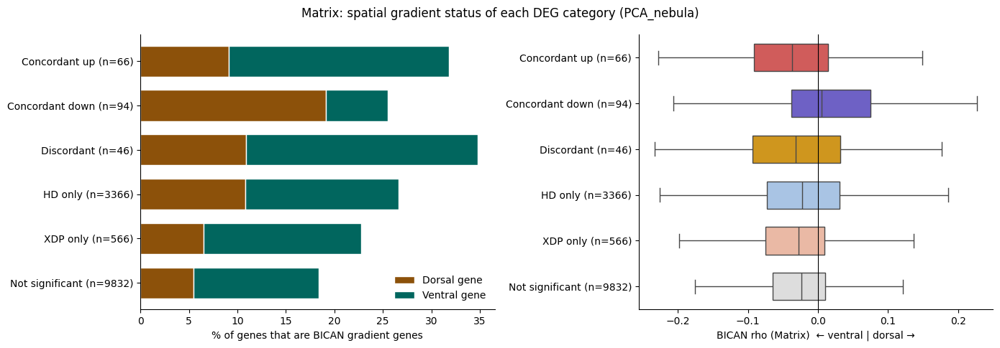

Matrix: background % gradient = 18.4%


,category,n,% gradient,% dorsal,% ventral,median rho,OR vs background,fisher_p
0,Concordant up,66,31.818,9.091,22.727,-0.037,2.068,0.010
1,Concordant down,94,25.532,19.149,6.383,0.005,1.520,0.083
2,Discordant,46,34.783,10.870,23.913,-0.032,2.364,0.007
3,HD only,3366,26.589,10.814,15.775,-0.022,1.605,0.000
4,XDP only,566,22.792,6.537,16.254,-0.028,1.308,0.011


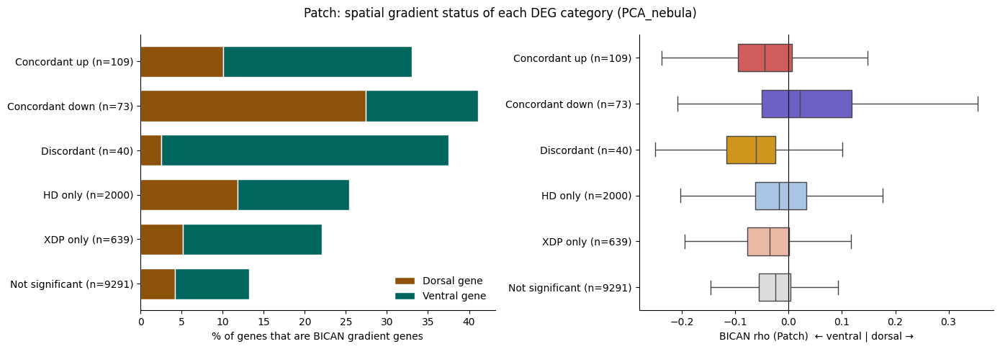

Patch: background % gradient = 13.2%


,category,n,% gradient,% dorsal,% ventral,median rho,OR vs background,fisher_p
0,Concordant up,109,33.028,10.092,22.936,-0.046,3.232,0.0
1,Concordant down,73,41.096,27.397,13.699,0.021,4.572,0.0
2,Discordant,40,37.500,2.500,35.000,-0.062,3.932,0.0
3,HD only,2000,25.400,11.800,13.600,-0.018,2.231,0.0
4,XDP only,639,22.066,5.164,16.901,-0.036,1.856,0.0


In [ ]:
for ct in CT_FOCUS:
    df = pairs[(METHOD_FOCUS, ct)].dropna(subset=["rho"])        # genes present in BICAN
    cats = [c for c in CATEGORIES if (df["category"] == c).any()]
    n_per_cat = df["category"].value_counts()
    labels = [f"{c} (n={n_per_cat[c]})" for c in cats]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 0.45 * len(cats) + 2.2))

    # left: % dorsal / ventral gradient genes per category
    frac = (pd.crosstab(df["category"], df["spatial"], normalize="index") * 100).reindex(cats)
    frac = frac.reindex(columns=["Dorsal gene", "Ventral gene"]).fillna(0)
    frac.index = labels
    frac.iloc[::-1].plot.barh(stacked=True, ax=ax1, color=[COL_DORSAL, COL_VENTRAL], edgecolor="white", width=0.7)
    ax1.set_xlabel("% of genes that are BICAN gradient genes"); ax1.set_ylabel("")
    ax1.legend(frameon=False, loc="lower right")

    # right: rho distribution per category
    sns.boxplot(data=df, y="category", x="rho", hue="category", order=cats, hue_order=cats, ax=ax2,
                palette=COL_CAT, showfliers=False, width=0.6, legend=False)
    ax2.axvline(0, color="black", lw=0.8)
    ax2.set_yticks(range(len(cats))); ax2.set_yticklabels(labels); ax2.set_ylabel("")
    ax2.set_xlabel(f"BICAN rho ({compartment(ct)})  ← ventral | dorsal →")
    for ax in (ax1, ax2):
        sns.despine(ax=ax)
    fig.suptitle(f"{ct}: spatial gradient status of each DEG category ({METHOD_FOCUS})")
    plt.tight_layout(); plt.show()

    # Fisher test: enrichment of gradient genes vs the "Not significant" background
    bg = df[df["category"] == "Not significant"]
    bg_grad, bg_n = (bg["spatial"] != "Not graded").sum(), len(bg)
    res = []
    for c in cats[:-1]:
        s = df[df["category"] == c]
        k = (s["spatial"] != "Not graded").sum()
        odds, p = fisher_exact([[k, len(s) - k], [bg_grad, bg_n - bg_grad]])
        res.append({"category": c, "n": len(s), "% gradient": 100 * k / len(s),
                    "% dorsal": 100 * (s["spatial"] == "Dorsal gene").mean(),
                    "% ventral": 100 * (s["spatial"] == "Ventral gene").mean(),
                    "median rho": s["rho"].median(), "OR vs background": odds, "fisher_p": p})
    print(f"{ct}: background % gradient = {100 * bg_grad / bg_n:.1f}%")
    display(pd.DataFrame(res).round(3))

**Plot — each DE list against the BICAN gradient.**
- *Left / middle*: one panel per disease, x = BICAN rho, y = log2FC. Grey dots = all genes; colored dots = genes DE in that disease. Labels: the DE genes with the largest |rho| × |log2FC|. Title: Spearman correlation over all genes and over DE genes only.
- *Right*: the trend in one simple line. All genes are split into 10 equal-size groups (deciles) by BICAN rho, from 1 = most ventral to 10 = most dorsal. The plot shows the mean log2FC per decile (± SEM) for HD and XDP. Deciles are used because most genes have rho close to 0. A line going *down* from left to right means ventral genes go up and dorsal genes go down in disease, i.e. a "loss-of-dorsal / ventral-shift" signature.

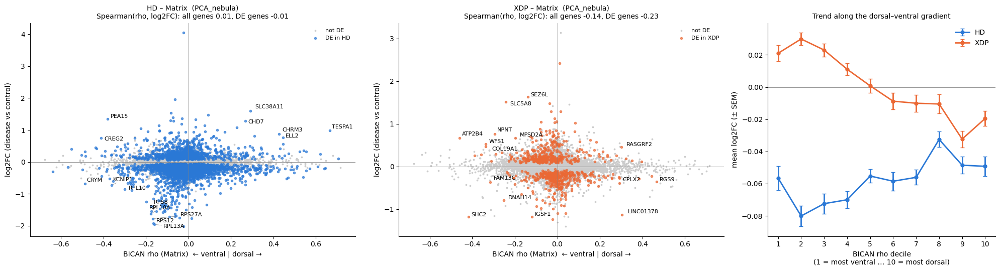

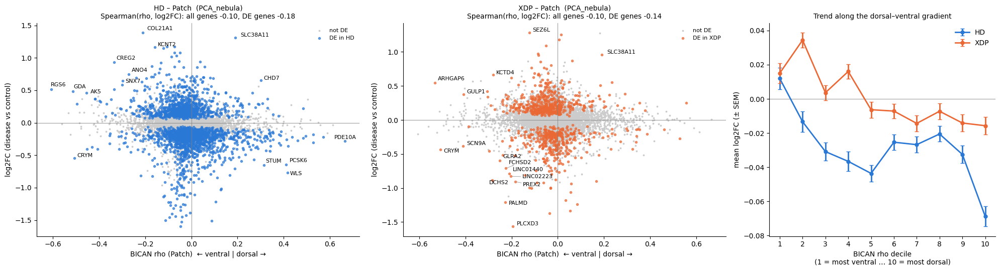

In [ ]:
def plot_logfc_vs_rho(df, ct, method_name, n_labels=15):
    d = df.dropna(subset=["rho"]).copy()
    d["rho_decile"] = pd.qcut(d["rho"], 10, labels=range(1, 11))   # 1 = most ventral ... 10 = most dorsal
    fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1, 1, 0.7]})

    for ax, ds in zip(axes[:2], ["HD", "XDP"]):
        lfc, sig = d[f"logFC_{ds}"], d[f"sig_{ds}"]
        ax.scatter(d.loc[~sig, "rho"], lfc[~sig], s=3, color="#cccccc", label="not DE", rasterized=True)
        ax.scatter(d.loc[sig, "rho"],  lfc[sig],  s=9, color=COL_DATASET[ds], alpha=0.7, label=f"DE in {ds}")

        # labels: DE genes that are both strongly graded and strongly changed
        top = d[sig].assign(score=lambda x: x["rho"].abs() * x[f"logFC_{ds}"].abs()).nlargest(n_labels, "score")
        texts = [ax.text(r.rho, r[f"logFC_{ds}"], r.gene, fontsize=8) for _, r in top.iterrows()]
        adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))

        r_all, r_de = spearmanr(d["rho"], lfc)[0], spearmanr(d.loc[sig, "rho"], lfc[sig])[0]
        ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
        ax.set_title(f"{ds} – {ct}  ({method_name})\nSpearman(rho, log2FC): all genes {r_all:.2f}, DE genes {r_de:.2f}", fontsize=10)
        ax.set_xlabel(f"BICAN rho ({compartment(ct)})  ← ventral | dorsal →"); ax.set_ylabel("log2FC (disease vs control)")
        ax.legend(fontsize=8, frameon=False, loc="upper right")
        sns.despine(ax=ax)

    # right: mean log2FC per rho decile, both diseases on the same axis
    ax = axes[2]
    for ds in ["HD", "XDP"]:
        per_dec = d.groupby("rho_decile", observed=True)[f"logFC_{ds}"].agg(["mean", "sem"])
        ax.errorbar(per_dec.index.astype(int), per_dec["mean"], yerr=per_dec["sem"], color=COL_DATASET[ds],
                    marker="o", ms=5, lw=2, capsize=3, label=ds)
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("BICAN rho decile\n(1 = most ventral … 10 = most dorsal)"); ax.set_ylabel("mean log2FC (± SEM)")
    ax.set_title("Trend along the dorsal–ventral gradient", fontsize=10)
    ax.legend(frameon=False); sns.despine(ax=ax)
    plt.tight_layout(); plt.show()


for ct in CT_FOCUS:
    plot_logfc_vs_rho(pairs[(METHOD_FOCUS, ct)], ct, METHOD_FOCUS)

**Plot — does the DE method change the spatial signal?** Spearman(BICAN rho, log2FC) over all genes, for every cell type, method and disease. Bars near 0 = the DE list is not organised along the dorsal–ventral axis. Strongly negative = disease-up genes are ventral genes and disease-down genes are dorsal genes. Missing bars = DE table not available for that method.

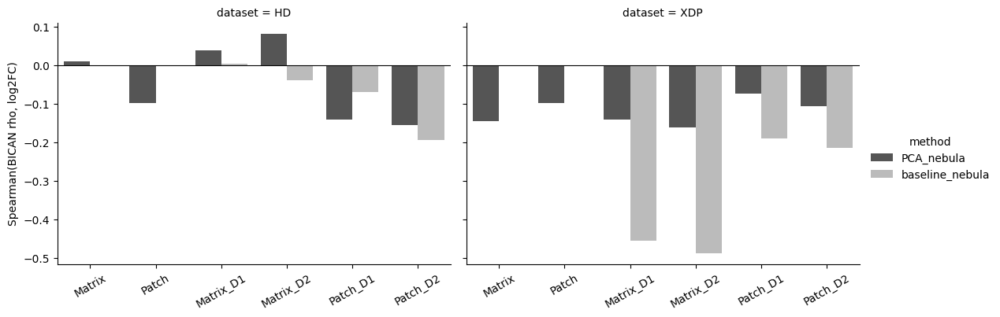

cell_type                Matrix  Matrix_D1  Matrix_D2  Patch  Patch_D1  \
dataset method                                                           
HD      PCA_nebula         0.01       0.04       0.08   -0.1     -0.14   
        baseline_nebula     NaN       0.00      -0.04    NaN     -0.07   
XDP     PCA_nebula        -0.14      -0.14      -0.16   -0.1     -0.07   
        baseline_nebula     NaN      -0.45      -0.49    NaN     -0.19   

cell_type                Patch_D2  
dataset method                     
HD      PCA_nebula          -0.15  
        baseline_nebula     -0.19  
XDP     PCA_nebula          -0.11  
        baseline_nebula     -0.21

In [ ]:
rows = []
for (m, ct), df in pairs.items():
    d = df.dropna(subset=["rho"])
    for ds in ["HD", "XDP"]:
        rows.append({"method": m, "cell_type": ct, "dataset": ds,
                     "spearman_rho_vs_logFC": spearmanr(d["rho"], d[f"logFC_{ds}"])[0],
                     "spearman_DE_only": spearmanr(d.loc[d[f"sig_{ds}"], "rho"], d.loc[d[f"sig_{ds}"], f"logFC_{ds}"])[0]})
spatial_cmp = pd.DataFrame(rows)

g = sns.catplot(data=spatial_cmp, x="cell_type", y="spearman_rho_vs_logFC", hue="method", col="dataset",
                kind="bar", palette=["#555555", "#bbbbbb"], height=4, aspect=1.4, order=CT_ALL)
for ax in g.axes.flat:
    ax.axhline(0, color="black", lw=0.8); ax.tick_params(axis="x", rotation=30); ax.set_xlabel("")
g.set_axis_labels("", "Spearman(BICAN rho, log2FC)")
plt.show()

spatial_cmp.pivot_table(index=["dataset", "method"], columns="cell_type", values="spearman_rho_vs_logFC").round(2)

## 6. GSEA on each DE list, then comparison

For each focus cell type, **pre-ranked GSEA** is run separately on the HD and on the XDP list:
- Rank metric = `sign(logFC) × −log10(p)` (raw p; GSEA does its own permutation FDR), as in the DEG interpretation notebooks.
- Ribosomal / mitochondrial / lncRNA / snoRNA genes are removed from the ranking (same regex as the interpretation notebooks).
- Gene sets: MSigDB Hallmark 2020, GO Biological Process 2025 (15–250 genes), and two **custom BICAN sets**: dorsal gradient genes and ventral gradient genes of the matching compartment.

NES > 0 = the set is enriched among disease-**up** genes, NES < 0 = among disease-**down** genes. Takes a few minutes (GO BP ≈ 40 s per run).

In [ ]:
# ── Gene set libraries (read from the local gseapy cache, download only if missing) ──
def load_library(name):
    path = os.path.expanduser(f"~/.cache/gseapy/Enrichr.{name}.gmt")
    return gp.read_gmt(path) if os.path.exists(path) else gp.get_library(name)

LIBRARIES = {"Hallmark": load_library("MSigDB_Hallmark_2020"),
             "GO_BP":    load_library("GO_Biological_Process_2025"),
             "Reactome": load_library("Reactome_Pathways_2024")
             }

def bican_gene_sets(ct):
    # Dorsal / ventral gradient genes from healthy BICAN (matching compartment).
    comp = compartment(ct)
    is_grad = (bican[f"padj_{comp}"] < GRAD_PADJ_THR) & (bican[f"rho_{comp}"].abs() >= GRAD_RHO_THR)
    return {f"BICAN_dorsal_{comp}":  bican.index[is_grad & (bican[f"rho_{comp}"] > 0)].tolist(),
            f"BICAN_ventral_{comp}": bican.index[is_grad & (bican[f"rho_{comp}"] < 0)].tolist()}

NOISY_GENES = re.compile(r"^(RPL|RPS|MRPL|MRPS|MT-|LINC|SNHG|SNORA|SNORD|MIR[0-9]|RNU|ENSG)", re.IGNORECASE)

def make_ranking(df, ds):
    # sign(logFC) * -log10(p), noisy gene classes removed, sorted from most up to most down.
    rank = np.sign(df[f"logFC_{ds}"]) * -np.log10(df[f"p_{ds}"].clip(lower=1e-300))
    rank.index = df["gene"]
    rank = rank[~rank.index.str.match(NOISY_GENES)]
    return rank.sort_values(ascending=False)

def run_gsea(rank, gene_sets, min_size, max_size):
    res = gp.prerank(rnk=rank, gene_sets=gene_sets, seed=42, permutation_num=1000,
                     min_size=min_size, max_size=max_size, threads=16, verbose=False, outdir=None)
    out = res.res2d[["Term", "NES", "FDR q-val", "Lead_genes"]].rename(columns={"FDR q-val": "FDR"})
    return out.astype({"NES": float, "FDR": float})


# Run: one table per (cell type, library), with HD and XDP side by side
gsea = {}
for ct in CT_FOCUS:
    df = pairs[(METHOD_FOCUS, ct)]
    libs = {**LIBRARIES, "BICAN_gradient": bican_gene_sets(ct)}
    for lib_name, gene_sets in libs.items():
        min_s, max_s = (1, 5000) if lib_name == "BICAN_gradient" else (15, 250)
        per_ds = [run_gsea(make_ranking(df, ds), gene_sets, min_s, max_s).set_index("Term").add_suffix(f"_{ds}")
                  for ds in ["HD", "XDP"]]
        tab = per_ds[0].join(per_ds[1], how="outer").reset_index()
        tab.to_csv(f"{OUT_DIR}/gsea_{ct}_{lib_name}.csv", index=False)
        gsea[(ct, lib_name)] = tab
        print(f"{ct:8s} {lib_name:15s} terms tested: {len(tab)}")

Matrix   Hallmark        terms tested: 50
Matrix   GO_BP           terms tested: 1893
Matrix   Reactome        terms tested: 1098
Matrix   BICAN_gradient  terms tested: 2
Patch    Hallmark        terms tested: 50
Patch    GO_BP           terms tested: 1718
Patch    Reactome        terms tested: 1046
Patch    BICAN_gradient  terms tested: 2


**Table — custom BICAN gradient sets.** This is the GSEA version of Section 5: are dorsal / ventral gradient genes collectively shifted up or down in each disease?

In [ ]:
pd.concat({ct: gsea[(ct, "BICAN_gradient")].set_index("Term")[["NES_HD", "FDR_HD", "NES_XDP", "FDR_XDP"]] for ct in CT_FOCUS}).round(3)

NES_HD  FDR_HD  NES_XDP  FDR_XDP
       Term                                                  
Matrix BICAN_dorsal_Matrix   -1.311   0.000   -1.313      0.0
       BICAN_ventral_Matrix  -0.870   0.972    1.698      0.0
Patch  BICAN_dorsal_Patch    -1.986   0.000   -1.318      0.0
       BICAN_ventral_Patch    1.731   0.000    1.541      0.0

**Plot — pathway NES in HD vs XDP.** Each dot is a gene set. x = NES in HD, y = NES in XDP.
- Top-right = up in both, bottom-left = down in both (**common biology**); off-diagonal quadrants = opposite.
- Colors: significant (FDR < `FDR_GSEA`) in both = red, only HD = blue, only XDP = orange, neither = grey. `FDR_GSEA = 0.25` is the usual exploratory GSEA cut-off. With FDR < 0.05 almost nothing passes after PCA correction.
- Labelled: gene sets significant in at least one disease (largest |NES| first).
- The GO BP cloud has a gap around NES = 0 because NES is normalised separately for positive and negative ES. This is expected.

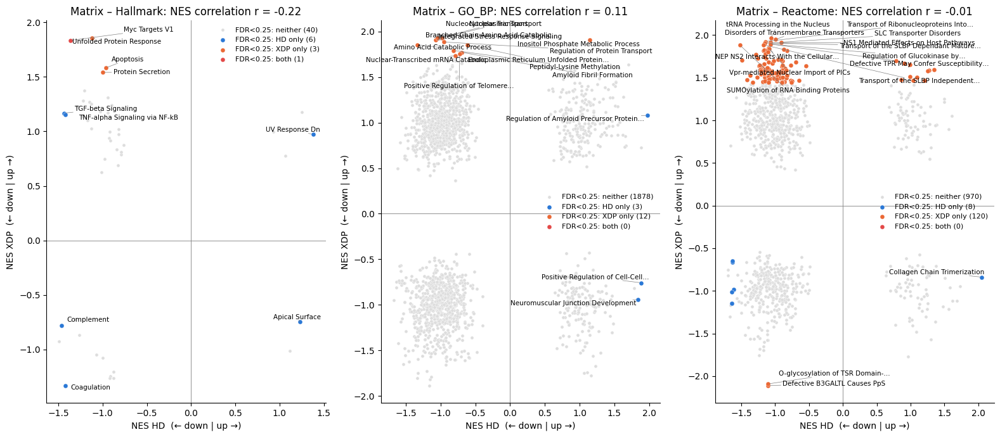

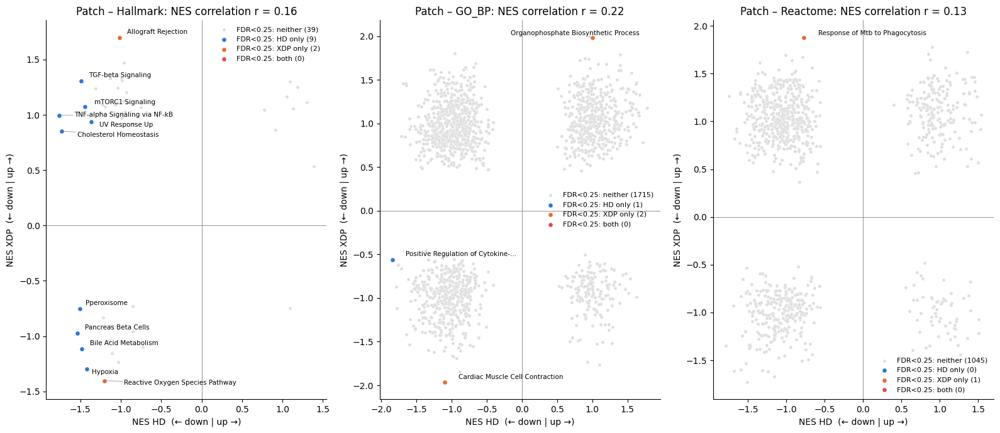

In [ ]:
FDR_GSEA = 0.25   # standard exploratory GSEA threshold

def short_term(t, width=50):
    # Remove GO ids and shorten long names so they stay readable.
    return textwrap.shorten(re.sub(r"\s*\(GO:\d+\)", "", t), width=width, placeholder="…")

def gsea_status(tab):
    sig_hd, sig_xdp = tab["FDR_HD"] < FDR_GSEA, tab["FDR_XDP"] < FDR_GSEA
    return np.select([sig_hd & sig_xdp, sig_hd, sig_xdp], ["both", "HD only", "XDP only"], default="neither")

COL_GSEA = {"both": "#e34948", "HD only": COL_DATASET["HD"], "XDP only": COL_DATASET["XDP"], "neither": "#dddddd"}

for ct in CT_FOCUS:
    fig, axes = plt.subplots(1, 3, figsize=(16, 7))
    for ax, lib_name in zip(axes, ["Hallmark", "GO_BP", "Reactome"]):
        tab = gsea[(ct, lib_name)].dropna(subset=["NES_HD", "NES_XDP"]).copy()
        tab["status"] = gsea_status(tab)
        for st in ["neither", "HD only", "XDP only", "both"]:            # 'both' drawn last = on top
            s = tab[tab["status"] == st]
            ax.scatter(s["NES_HD"], s["NES_XDP"], s=14 if st == "neither" else 26, color=COL_GSEA[st],
                       label=f"FDR<{FDR_GSEA}: {st} ({len(s)})", edgecolor="white", linewidth=0.3)
        sig_any = tab[tab["status"] != "neither"]
        top = sig_any.assign(strength=sig_any[["NES_HD", "NES_XDP"]].abs().max(axis=1)).nlargest(15, "strength")
        texts = [ax.text(r.NES_HD, r.NES_XDP, short_term(r.Term, 40), fontsize=7.5) for _, r in top.iterrows()]
        adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))
        ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
        r = spearmanr(tab["NES_HD"], tab["NES_XDP"])[0]
        ax.set_title(f"{ct} – {lib_name}: NES correlation r = {r:.2f}")
        ax.set_xlabel("NES HD  (← down | up →)"); ax.set_ylabel("NES XDP  (← down | up →)")
        ax.legend(fontsize=8, frameon=False, loc="best")
        sns.despine(ax=ax)
    plt.tight_layout(); plt.show()

**Plot — the most consistent GO BP / Hallmark terms between the two diseases.** Only terms with the **same** NES sign in HD and XDP are kept. They are ranked by the **weaker** of the two |NES|, so a term is high only if it is strong in *both* diseases. Up to 10 up and 10 down terms are shown. Blue bar = HD NES, orange = XDP NES. The text on the right gives the FDR in HD / XDP, and **★ = FDR < `FDR_GSEA` in both**. These are the "most shared" pathways, not necessarily significant ones. Read them together with the FDRs.

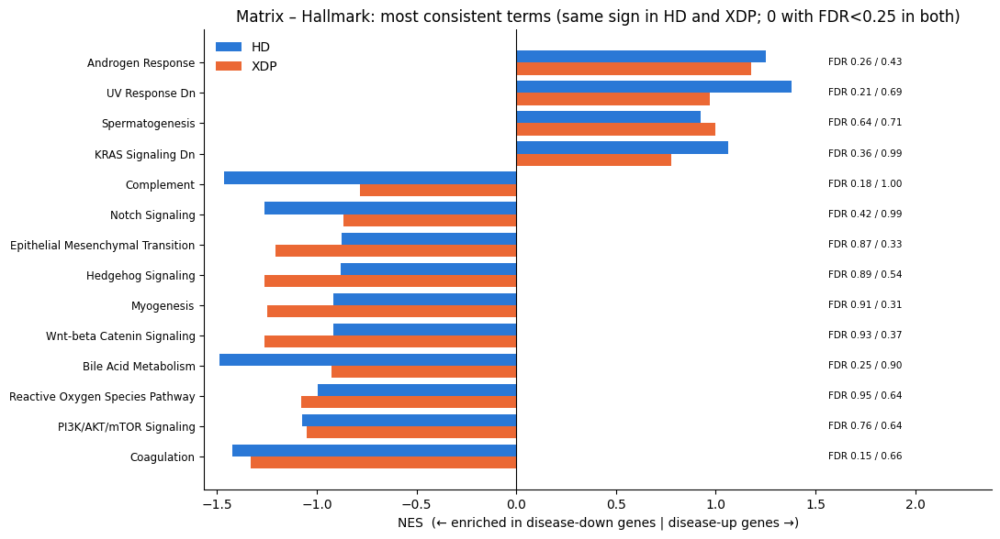

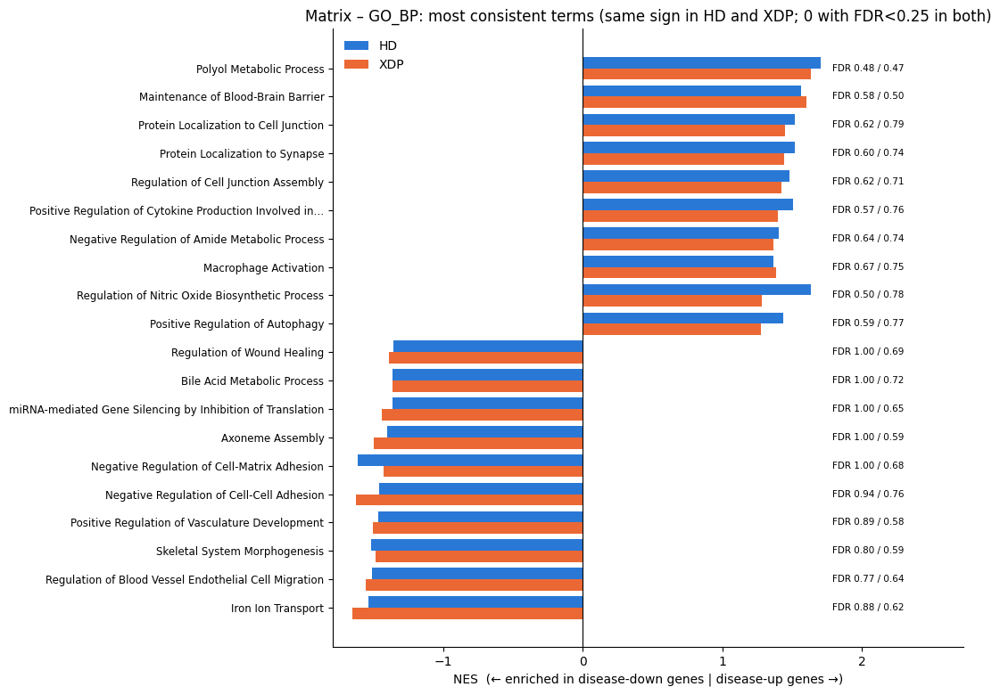

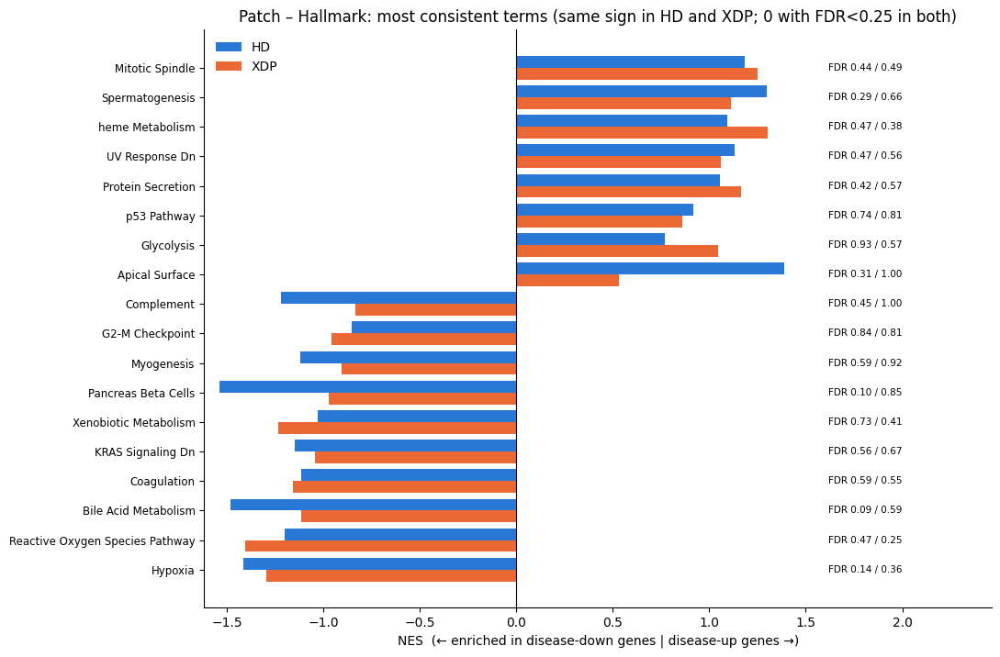

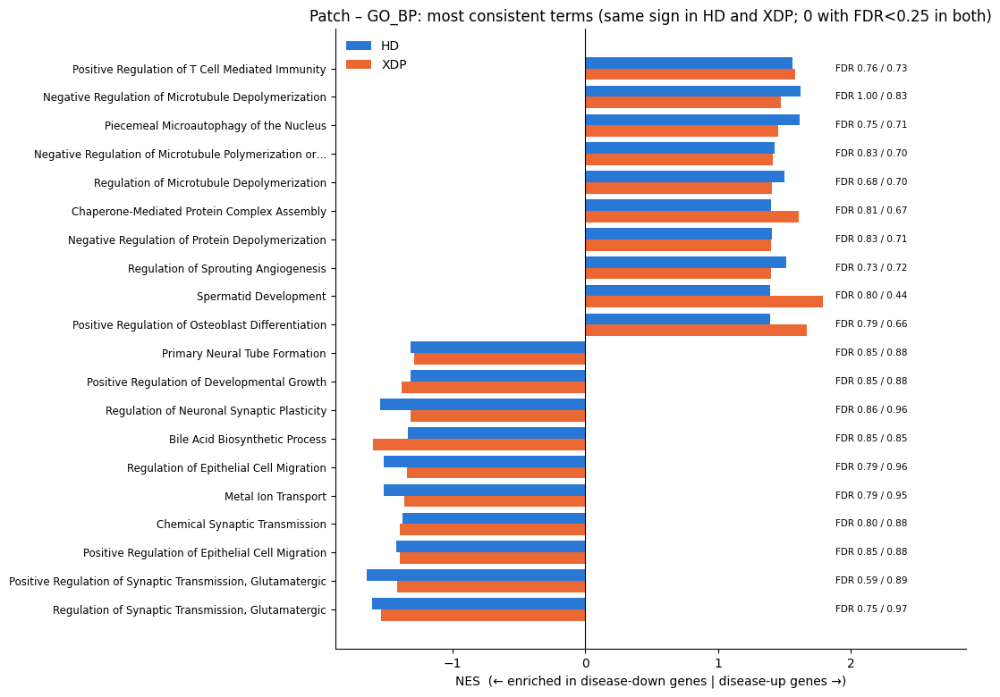

In [ ]:
def plot_consistent_terms(tab, ct, lib_name, n=10):
    t = tab.dropna(subset=["NES_HD", "NES_XDP"])
    t = t[np.sign(t["NES_HD"]) == np.sign(t["NES_XDP"])].copy()          # same direction in both diseases
    t["strength"] = t[["NES_HD", "NES_XDP"]].abs().min(axis=1)            # weaker of the two NES
    t["sig_both"] = (t["FDR_HD"] < FDR_GSEA) & (t["FDR_XDP"] < FDR_GSEA)
    up   = t[t["NES_HD"] > 0].nlargest(n, "strength")
    down = t[t["NES_HD"] < 0].nlargest(n, "strength")
    show = pd.concat([up, down.iloc[::-1]]).iloc[::-1]   # up terms on top, down terms at the bottom

    y, h = np.arange(len(show)), 0.4
    fig, ax = plt.subplots(figsize=(11, 0.32 * len(show) + 1.5))
    ax.barh(y + h / 2, show["NES_HD"],  height=h, color=COL_DATASET["HD"],  label="HD")
    ax.barh(y - h / 2, show["NES_XDP"], height=h, color=COL_DATASET["XDP"], label="XDP")
    ax.set_yticks(y); ax.set_yticklabels([short_term(x, 60) for x in show["Term"]], fontsize=8.5)
    xmax = show[["NES_HD", "NES_XDP"]].abs().max().max()
    for yy, (_, r) in zip(y, show.iterrows()):
        ax.text(xmax * 1.05, yy, f"{'★ ' if r.sig_both else ''}FDR {r.FDR_HD:.2f} / {r.FDR_XDP:.2f}", va="center", fontsize=7.5)
    ax.set_xlim(-xmax * 1.05, xmax * 1.6)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("NES  (← enriched in disease-down genes | disease-up genes →)")
    ax.set_title(f"{ct} – {lib_name}: most consistent terms (same sign in HD and XDP; {t['sig_both'].sum()} with FDR<{FDR_GSEA} in both)")
    ax.legend(frameon=False, loc="upper left"); sns.despine(ax=ax)   # upper-left is empty: up terms are on top and extend right
    plt.tight_layout(); plt.show()
    return t.sort_values("strength", ascending=False)

consistent_terms = {}
for ct in CT_FOCUS:
    for lib_name in ["Hallmark", "GO_BP"]:
        consistent_terms[(ct, lib_name)] = plot_consistent_terms(gsea[(ct, lib_name)], ct, lib_name)

**ORA on the concordant genes.** GSEA uses the whole ranked list. As a complement, we test whether the *concordant up* and *concordant down* gene lists are over-represented in GO BP terms (hypergeometric test; background = all genes tested in both datasets). The plot shows −log10(adj. p) of the top terms. The number at the end of each bar is overlap / term size, followed by the overlapping genes.

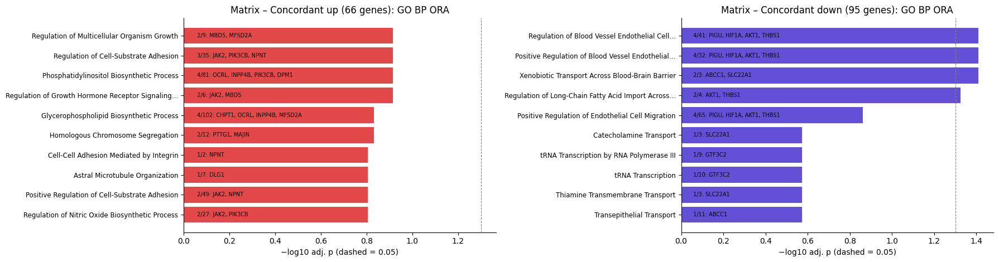

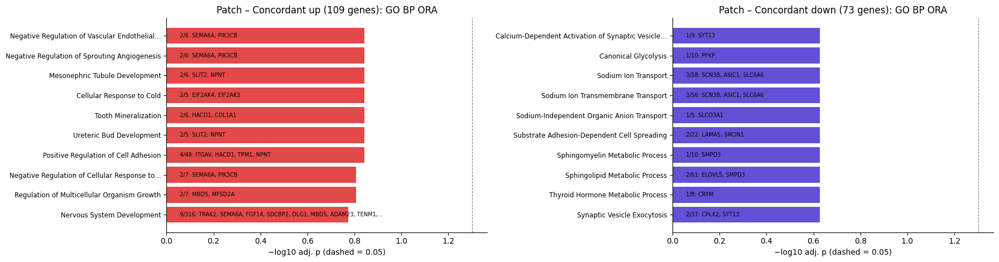

In [ ]:
def run_ora(genes, background, gene_sets):
    res = gp.enrich(gene_list=list(genes), gene_sets=gene_sets, background=list(background), outdir=None, verbose=False)
    return res.res2d.sort_values("Adjusted P-value")

for ct in CT_FOCUS:
    df = pairs[(METHOD_FOCUS, ct)]
    fig, axes = plt.subplots(1, 2, figsize=(18, 4.8))
    for ax, category in zip(axes, ["Concordant up", "Concordant down"]):
        genes = df.loc[df["category"] == category, "gene"]
        ora = run_ora(genes, df["gene"], LIBRARIES["GO_BP"]).head(10).iloc[::-1]
        ora.to_csv(f"{OUT_DIR}/ora_{ct}_{category.replace(' ', '_')}.csv", index=False)
        ax.barh(range(len(ora)), -np.log10(ora["Adjusted P-value"]), color=COL_CAT[category])
        ax.set_yticks(range(len(ora))); ax.set_yticklabels([short_term(t, 50) for t in ora["Term"]], fontsize=8.5)
        for yy, (ov, g) in enumerate(zip(ora["Overlap"], ora["Genes"])):
            ax.text(0.05, yy, f" {ov}: {textwrap.shorten(g.replace(';', ', '), 60, placeholder='…')}", va="center", fontsize=7)
        ax.axvline(-np.log10(0.05), color="grey", ls="--", lw=0.8)
        ax.set_xlabel("−log10 adj. p (dashed = 0.05)")
        ax.set_title(f"{ct} – {category} ({len(genes)} genes): GO BP ORA")
        sns.despine(ax=ax)
    plt.tight_layout(); plt.show()

## 7. Summary

The table below is recomputed each time the notebook runs. The interpretation underneath was written from the run with `METHOD_FOCUS = "PCA_nebula"`, `PADJ_THR = 0.05`.

In [ ]:
summary_rows = []
for ct in CT_FOCUS:
    df = pairs[(METHOD_FOCUS, ct)]
    ov = overview[(overview["method"] == METHOD_FOCUS) & (overview["cell_type"] == ct)].iloc[0]
    sp = spatial_cmp[(spatial_cmp["method"] == METHOD_FOCUS) & (spatial_cmp["cell_type"] == ct)].set_index("dataset")
    top = lambda cat: ", ".join(df[df["category"] == cat].assign(s=lambda x: x[["padj_HD", "padj_XDP"]].max(axis=1)).nsmallest(8, "s")["gene"])
    dorsal_set, ventral_set = bican_gene_sets(ct).keys()
    bg = gsea[(ct, "BICAN_gradient")].set_index("Term")
    summary_rows.append({
        "cell_type": ct,
        "DE HD / XDP": f"{ov.n_sig_HD} / {ov.n_sig_XDP}",
        "DE in both (up / down / discordant)": f"{ov.n_both} ({ov.conc_up} / {ov.conc_down} / {ov.discordant})",
        "% same direction": f"{ov.pct_concordant:.0f}%",
        "r logFC (all genes)": round(ov.r_all, 2),
        "r(rho, logFC) HD / XDP": f"{sp.loc['HD', 'spearman_rho_vs_logFC']:.2f} / {sp.loc['XDP', 'spearman_rho_vs_logFC']:.2f}",
        "BICAN ventral set NES HD / XDP": f"{bg.loc[ventral_set, 'NES_HD']:.2f} / {bg.loc[ventral_set, 'NES_XDP']:.2f}",
        "BICAN dorsal set NES HD / XDP":  f"{bg.loc[dorsal_set, 'NES_HD']:.2f} / {bg.loc[dorsal_set, 'NES_XDP']:.2f}",
        "top concordant up": top("Concordant up"),
        "top concordant down": top("Concordant down"),
        "top discordant": top("Discordant"),
        f"# GO BP terms FDR<{FDR_GSEA} in HD / XDP / both (same dir.)":
            f"{(gsea[(ct, 'GO_BP')]['FDR_HD'] < FDR_GSEA).sum()} / {(gsea[(ct, 'GO_BP')]['FDR_XDP'] < FDR_GSEA).sum()} / {consistent_terms[(ct, 'GO_BP')]['sig_both'].sum()}",
        "most consistent GO BP terms (up)":   "; ".join(short_term(x, 45) for x in consistent_terms[(ct, "GO_BP")].query("NES_HD > 0")["Term"].head(3)),
        "most consistent GO BP terms (down)": "; ".join(short_term(x, 45) for x in consistent_terms[(ct, "GO_BP")].query("NES_HD < 0")["Term"].head(3)),
    })
pd.set_option("display.max_colwidth", None)
pd.DataFrame(summary_rows).set_index("cell_type").T

cell_type,Matrix,Patch
DE HD / XDP,3578 / 773,2223 / 863
DE in both (up / down / discordant),207 (66 / 95 / 46),222 (109 / 73 / 40)
% same direction,78%,82%
r logFC (all genes),0.12,0.14
"r(rho, logFC) HD / XDP",0.01 / -0.14,-0.10 / -0.10
BICAN ventral set NES HD / XDP,-0.87 / 1.70,1.73 / 1.54
BICAN dorsal set NES HD / XDP,-1.31 / -1.31,-1.99 / -1.32
top concordant up,"SEZ6L, PPP2R5B, MAOB, PTPN9, C2orf69, CHST2, SDCBP2, ROCK1","PPP2R5B, PIK3CB, MFSD2A, SOS2, MAOB, SEZ6L, FGF14, SLC38A11"
top concordant down,"VAC14, CCDC3, CPLX2, ADAMTSL2, UQCC2, TRAPPC6A, ANTXR1, ECE2","CHCHD6, NHSL2, LMO4, SLC2A3, CASK, PRICKLE2, THSD7B, CTNNBL1"
top discordant,"LIPH, FSD1, WDR45, NT5C3A, EEF1B2, C8orf44, MSRA, EFCAB12","DMD, CCNH, COA1, PARP8, GLRA2, GAB1, LINC01277, RPS6"


### Interpretation

Numbers are from the run with `PCA_nebula`, `PADJ_THR = 0.05`, BICAN gradient genes = `padj < 0.05 & |rho| ≥ 0.1`.

**1. HD and XDP share a small but real MSN response.**
- Genome-wide the two DE lists are only weakly related: Spearman r of logFC = 0.05–0.16 with `PCA_nebula`.
- Among the genes DE in *both* diseases, the direction mostly agrees:
  - Matrix: 78% same direction (207 genes).
  - Patch: 82% same direction (222 genes).
  - Matrix_D1: 92%. Patch_D2: 88%.
  - All far above 50% chance (binomial test).
- Matrix_D2 is the exception, at 58%.
- The shared set is small compared with each disease alone. In Matrix, HD has 3578 DE genes and XDP has 773, but only 161 are concordant. Part of the asymmetry is power, since the HD village has more donors.

**2. The DE method mainly changes the XDP Matrix result, and what it removes is spatial.**
- PCA correction removes about 80% of the XDP Matrix DEGs:
  - Matrix_D1: 2404 → 398.
  - Matrix_D2: 2354 → 738.
- It barely changes XDP Patch (645 → 723 and 515 → 519). HD loses 30–55% everywhere.
- In XDP Matrix, the baseline DE is dominated by the healthy dorsal–ventral gradient: Spearman(BICAN rho, logFC) = −0.45 / −0.49. With PCA this falls to −0.14 / −0.16. The healthy PCs therefore capture mostly *position along the striatum*, which is what they were designed to absorb.
- Genome-wide HD–XDP agreement is also higher with baseline: r = 0.25–0.29 vs 0.05–0.16 for the same D1/D2 subtypes. So the PCs remove some variation that the two diseases share. It is not possible to tell from these data whether that variation is shared confounding (dissection, cell state) or shared biology.

**3. Even after correction, the shared genes are spatial genes: "dorsal down, ventral up".**
- Every DE category is enriched for BICAN gradient genes compared with non-DE genes (Fisher OR 1.3–4.6; all p < 0.05 except Matrix concordant-down, p = 0.08).
- The direction is consistent:
  - Concordant **up** genes are mostly **ventral-high**: ~23% ventral vs ~10% dorsal, in both Matrix and Patch.
  - Concordant **down** genes are mostly **dorsal-high**: Matrix 19% vs 6%, Patch 27% vs 14%.
- GSEA with the BICAN sets agrees. The **dorsal** gene set is down in both diseases and both compartments (NES −1.3 to −2.0, FDR < 0.001). The **ventral** set is up in XDP (Matrix and Patch) and in HD Patch, but not in HD Matrix.
- The decile plots show the same picture: a monotonic drop from ventral to dorsal genes in XDP Matrix and in Patch of both diseases. HD Matrix has no such trend.
- The classical HD striatal "down" genes are dorsal-high genes in BICAN:
  - CPLX2 and RGS9 are concordant down in HD and XDP.
  - PDE10A, SCN4B and DRD2 are down only in HD.
- **Possible meaning:** in both diseases, patient MSNs look *less dorsal / more ventral*. Two explanations cannot be separated with snRNA-seq alone:
  - (a) **Composition.** The dorsal MSNs, the most vulnerable in both HD and XDP, are lost, and the survivors are a ventral-biased population. Dissection differences could add to this.
  - (b) **Cell-intrinsic loss of dorsal identity** ("ventralization").
- The SlideTags DE with a position covariate (eMSN-ruler design) is the direct test: a gene that stays DE at a fixed position is not explained by (a).

**4. Candidate shared genes that are *not* spatial.** These are the better candidates for a common cell-intrinsic response:
- Matrix up: MAOB, PTPN9, SDCBP2, ROCK1, DLG1, LGI3, PIK3CB.
- Patch up: PPP2R5B, PIK3CB, MFSD2A, ITGAV, SDCBP2.
- Matrix down: VAC14, UQCC2, TRAPPC6A, THBS1.
- Patch down: CHCHD6, SLC2A3, CASK, ELOVL5.
- MAOB is up in both compartments in both diseases. It encodes monoamine oxidase B, which produces H2O2 when it degrades dopamine, so it is a possible shared oxidative-stress link. These are hypotheses, not validated.
- Some prominent concordant genes are themselves strong ventral genes, for example WFS1, NPNT, MFSD2A in Matrix, and SEZ6L. Their "up" may simply belong to the spatial shift above.

**5. Discordant genes (~20% of the shared DEGs) have no spatial direction.**
- They include translation / ribosomal genes (EEF1B2, RPS4X, RPL37, RPS6) that go down in HD and up in XDP.
- In Matrix, Hallmark "Myc Targets V1" is also opposite (HD NES −1.36, XDP +1.84).
- This could be a real disease difference in protein-synthesis machinery. It could also be technical: village design vs NucSeq, and ribosomal transcripts are sensitive to ambient RNA and library preparation. Treat with caution.

**6. Pathway level: little in common.**
- After PCA correction, very few Hallmark / GO BP terms reach FDR < 0.25 in either disease.
- None are significant in both, and the NES correlation between diseases is ≈ 0.1–0.2.
- ORA on the concordant genes gives nothing robust. The best is Matrix concordant-down "regulation of endothelial cell migration" (THBS1, AKT1, HIF1A), adj. p ≈ 0.04, driven by 4 genes.
- **The shared HD/XDP signal is therefore gene-level and spatially organised, rather than a coherent pathway program.**

{'Phase D': 107, 'Phase C+': 274, 'Phase C-': 192, 'Age': 50, 'TAF1 related': 11, 'MMR GWAS': 6, 'XDP related': 107, 'PRC2 related': 217}


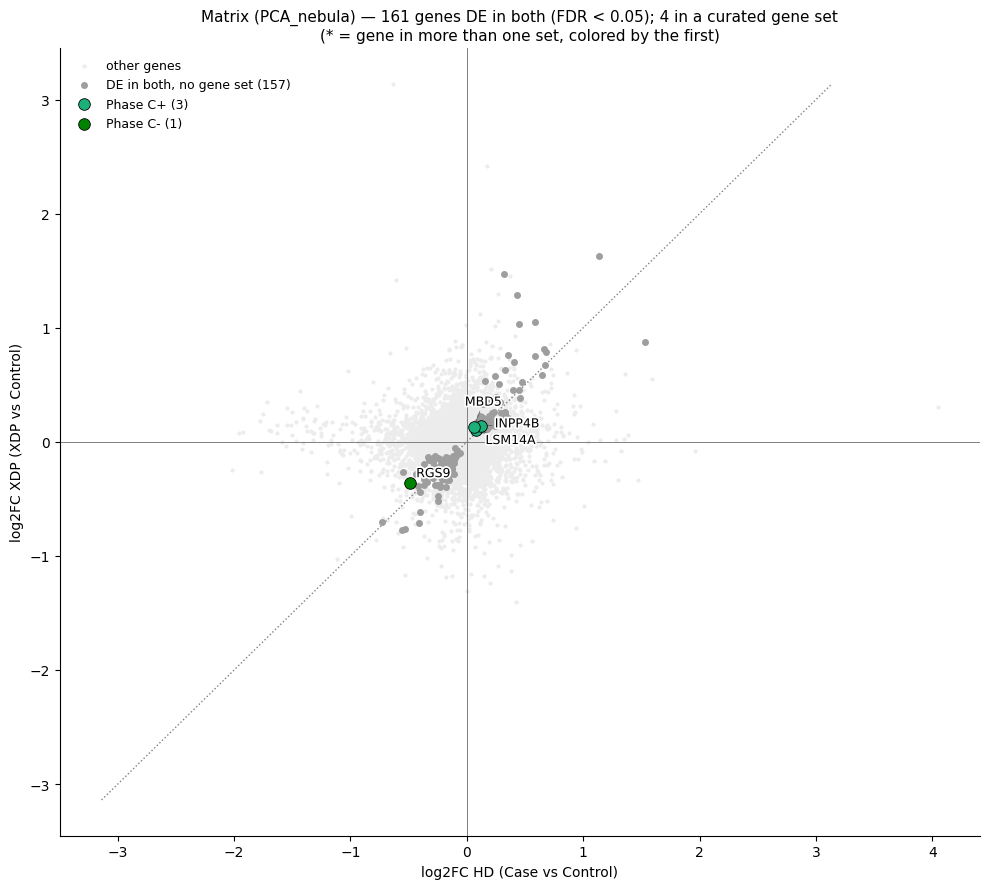

,gene,category,logFC_HD,padj_HD,logFC_XDP,padj_XDP,gene_sets
236,RGS9,Concordant down,-0.4872,0.0000,-0.3598,0.0457,Phase C-
1582,LSM14A,Concordant up,0.0817,0.0044,0.1053,0.0120,Phase C+
2094,INPP4B,Concordant up,0.1189,0.0106,0.1389,0.0098,Phase C+
2965,MBD5,Concordant up,0.0602,0.0301,0.1277,0.0000,Phase C+


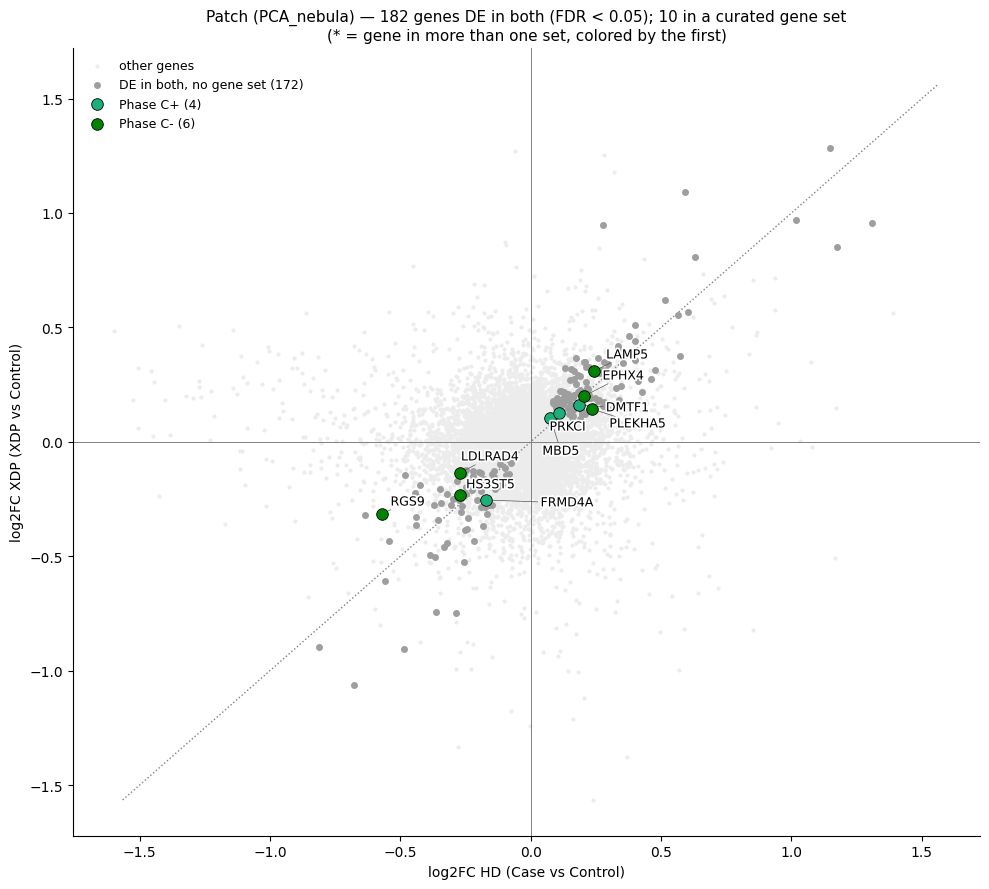

,gene,category,logFC_HD,padj_HD,logFC_XDP,padj_XDP,gene_sets
72,RGS9,Concordant down,-0.5700,0.0000,-0.3140,0.0305,Phase C-
119,LDLRAD4,Concordant down,-0.2706,0.0000,-0.1361,0.0304,Phase C-
341,HS3ST5,Concordant down,-0.2706,0.0001,-0.2324,0.0496,Phase C-
1083,FRMD4A,Concordant down,-0.1721,0.0076,-0.2543,0.0065,Phase C+
325,PLEKHA5,Concordant up,0.2351,0.0001,0.1438,0.0095,Phase C-
428,DMTF1,Concordant up,0.1863,0.0003,0.1598,0.0037,Phase C+
820,LAMP5,Concordant up,0.2425,0.0031,0.3096,0.0060,Phase C-
1298,EPHX4,Concordant up,0.2035,0.0122,0.1993,0.0314,Phase C-
1332,MBD5,Concordant up,0.0754,0.0133,0.1056,0.0006,Phase C+
1957,PRKCI,Concordant up,0.1072,0.0373,0.1256,0.0442,Phase C+


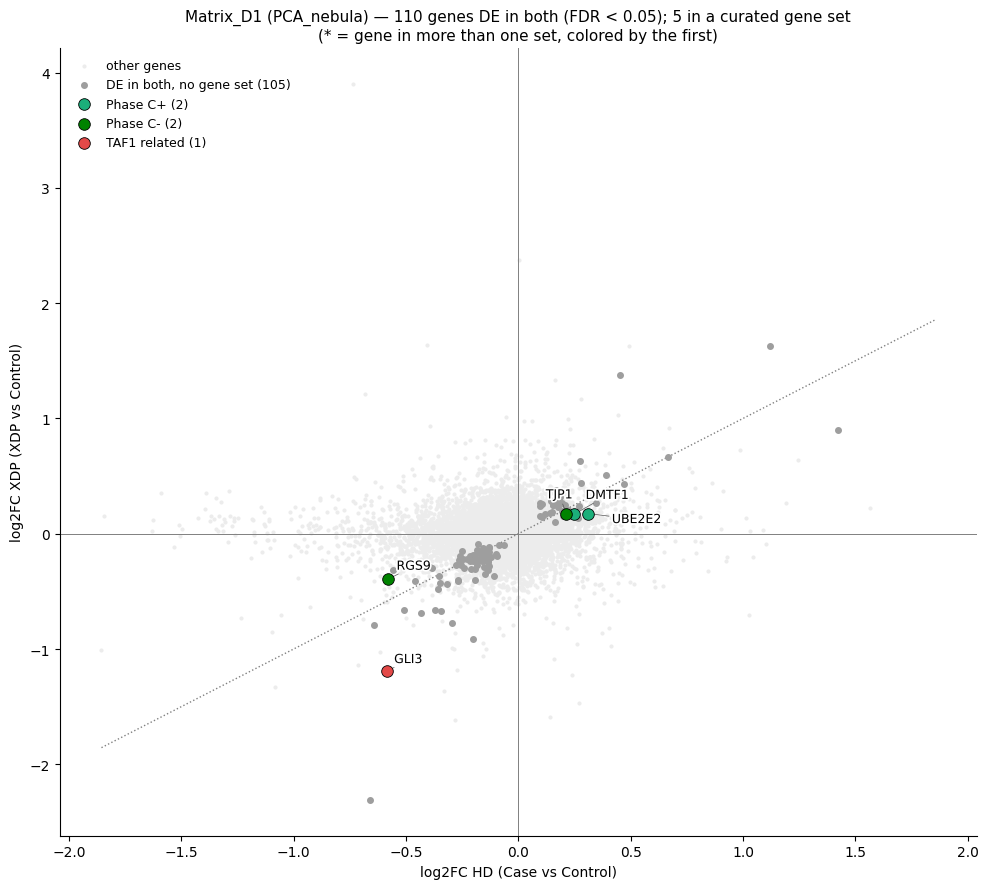

,gene,category,logFC_HD,padj_HD,logFC_XDP,padj_XDP,gene_sets
62,RGS9,Concordant down,-0.5777,0.0000,-0.3923,0.0370,Phase C-
1379,GLI3,Concordant down,-0.5824,0.0032,-1.1917,0.0161,TAF1 related
75,UBE2E2,Concordant up,0.3095,0.0000,0.1756,0.0101,Phase C+
226,DMTF1,Concordant up,0.2473,0.0000,0.1679,0.0239,Phase C+
839,TJP1,Concordant up,0.2143,0.0006,0.1743,0.0495,Phase C-


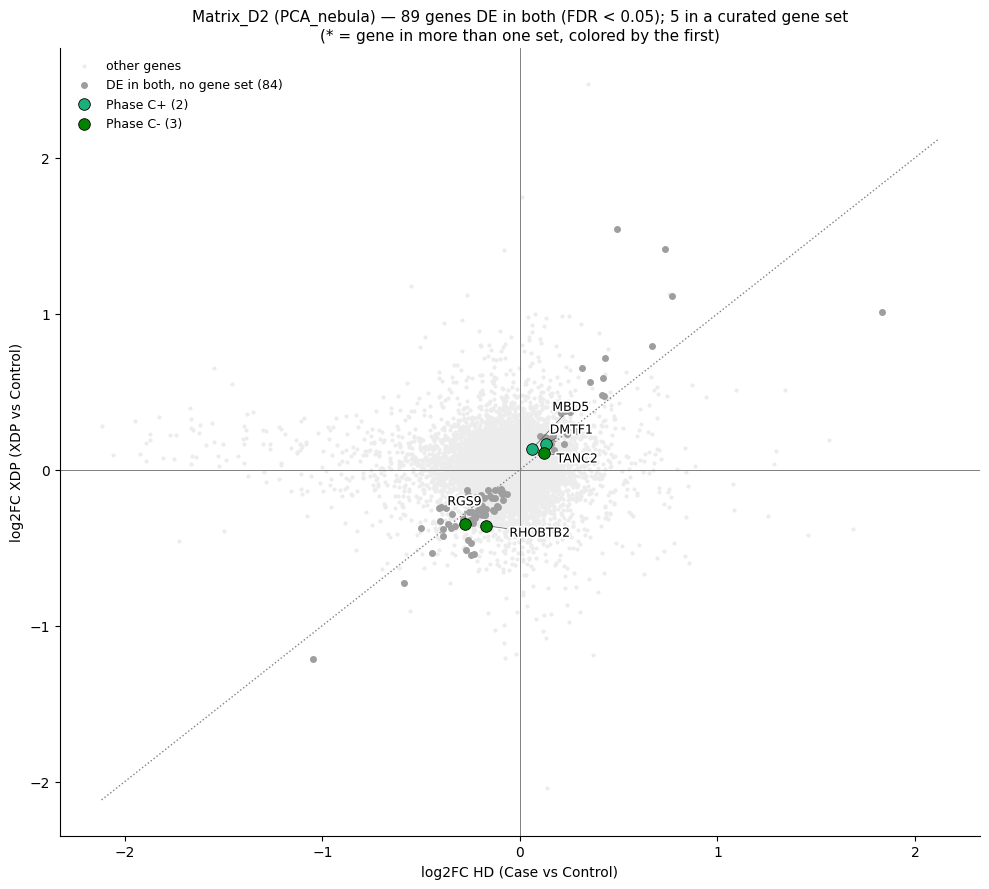

,gene,category,logFC_HD,padj_HD,logFC_XDP,padj_XDP,gene_sets
1408,RGS9,Concordant down,-0.2757,0.0141,-0.3456,0.0416,Phase C-
2213,RHOBTB2,Concordant down,-0.1706,0.0364,-0.3591,0.0376,Phase C-
643,TANC2,Concordant up,0.1239,0.0022,0.1080,0.0477,Phase C-
1678,DMTF1,Concordant up,0.1313,0.0196,0.1665,0.0076,Phase C+
1707,MBD5,Concordant up,0.0611,0.0205,0.1318,0.0000,Phase C+


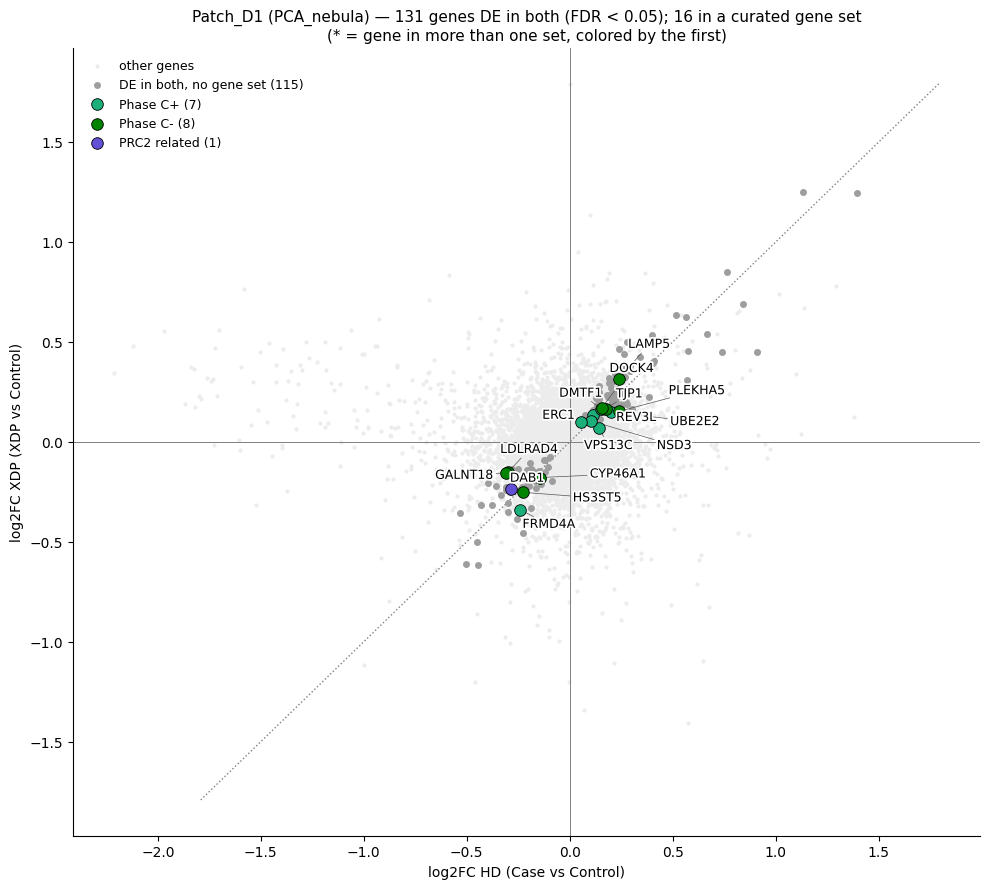

,gene,category,logFC_HD,padj_HD,logFC_XDP,padj_XDP,gene_sets
43,LDLRAD4,Concordant down,-0.2997,0.0000,-0.1524,0.0133,Phase C-
76,GALNT18,Concordant down,-0.3081,0.0000,-0.1549,0.0465,Phase C-
348,CYP46A1,Concordant down,-0.1457,0.0005,-0.1787,0.0422,Phase C-
966,FRMD4A,Concordant down,-0.2417,0.0113,-0.3394,0.0003,Phase C+
1039,HS3ST5,Concordant down,-0.2273,0.0137,-0.2528,0.0159,Phase C-
1247,DAB1,Concordant down,-0.2852,0.0238,-0.2352,0.0384,PRC2 related
275,VPS13C,Concordant up,0.1422,0.0002,0.0701,0.0395,Phase C+
373,PLEKHA5,Concordant up,0.2367,0.0005,0.1519,0.0111,Phase C-
532,UBE2E2,Concordant up,0.1990,0.0018,0.1487,0.0189,Phase C+
688,TJP1,Concordant up,0.1740,0.0039,0.1661,0.0383,Phase C-


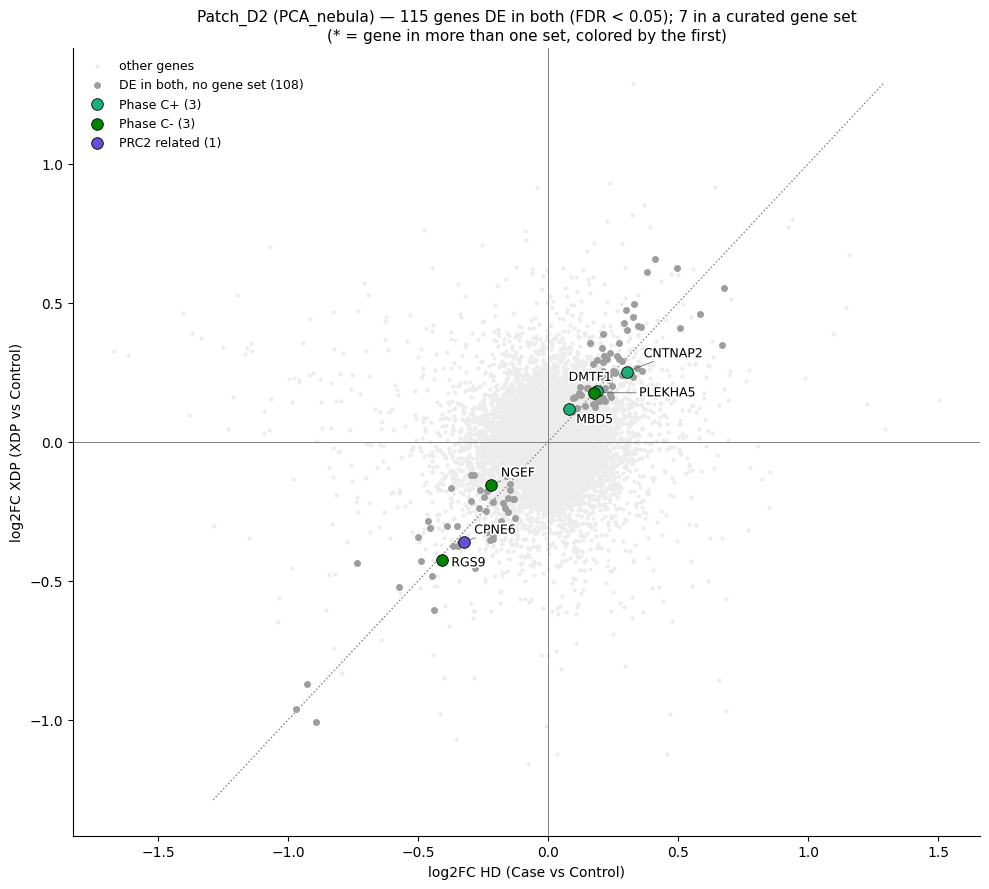

,gene,category,logFC_HD,padj_HD,logFC_XDP,padj_XDP,gene_sets
133,NGEF,Concordant down,-0.2199,0.0000,-0.1561,0.0478,Phase C-
416,RGS9,Concordant down,-0.4078,0.0012,-0.4253,0.0061,Phase C-
1355,CPNE6,Concordant down,-0.3246,0.0375,-0.3612,0.0320,PRC2 related
126,CNTNAP2,Concordant up,0.3029,0.0000,0.2525,0.0006,Phase C+
539,DMTF1,Concordant up,0.1860,0.0029,0.1830,0.0113,Phase C+
543,PLEKHA5,Concordant up,0.1781,0.0029,0.1766,0.0041,Phase C-
650,MBD5,Concordant up,0.0820,0.0053,0.1168,0.0075,Phase C+


In [ ]:
# ── Genes DE in BOTH diseases, highlighted by curated gene-set membership ──
import matplotlib.patheffects as pe

PADJ = 0.05                  # FDR threshold to call a gene DE in one dataset
INCLUDE_DISCORDANT = False   # True = also show genes DE in both with opposite sign


def load_hd_xdp(ct, method=method, padj=PADJ):
    # HD and XDP DE results for one cell type (genes tested in both) + category of each gene.
    # genes matched on Ensembl gene_id, XDP names, BH-FDR on the shared genes ("Gene matching" cell at the top)
    df = match_hd_xdp(read_de("HD", method, ct), read_de("XDP", method, ct))

    sig_hd, sig_xdp = df["padj_HD"] < padj, df["padj_XDP"] < padj
    same_sign = np.sign(df["logFC_HD"]) == np.sign(df["logFC_XDP"])
    df["category"] = np.select(
        [sig_hd & sig_xdp & same_sign & (df["logFC_HD"] > 0),
         sig_hd & sig_xdp & same_sign & (df["logFC_HD"] < 0),
         sig_hd & sig_xdp & ~same_sign,
         sig_hd, sig_xdp],
        ["Concordant up", "Concordant down", "Discordant", "HD only", "XDP only"],
        default="Not significant")
    return df


# ---------- Curated gene sets (same lists as the DEG interpretation notebooks) ----------
HS_DIR = "/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all"
phase_d       = pd.read_csv(f"{HS_DIR}/phase_d_genes.csv")
phase_c_plus  = pd.read_csv(f"{HS_DIR}/phase_c_plus_genes.csv")
phase_c_minus = pd.read_csv(f"{HS_DIR}/phase_c_minus_genes.csv")

age_genes = """HCN1 VWC2 OPRM1 BACH2 PCED1B MME EBF1 SPON1 SEMA3E SERPINE2 LINGO2 GRM8 KCNK2 SINHCAF DDIT4L PTPN7
PRKD1 PEX5L OPCML SHC3 PDE4B SLC24A2 CCDC39 FAT2 CNTN5 FIGN PTPRT MGAT4C IGF2BP2 AR ETV1 CDH10 CORO1C SPRED2
GJD2-DT ST3GAL6 EPHA3 UBASH3B PLEKHA7 PLD5 SH3RF3 DOK5 DOCK10 SEMA3D KITLG SCN11A COL19A1 ZNF732 UNC13C SATB1""".split()

taf1_related = "TAF1 TIA1 ZNF772 SMG7 ZNF93 MOV10L1 EXO1 SSH GLIA1 OGT GLI3".split()
mmr_gwas     = "FAN1 MLH1 MSH3 PMS1 PMS2 LIG1".split()

xdp_related = (
      "TAF1 OGT OGA ACRC CXCR3 NONO ING2 NLGN3 GJB1 ZNF261 ITGB1BP2".split()                              # Xq13.1 locus
    + "TBP TAF2 TAF3 TAF4 TAF5 TAF6 TAF7 TAF8 TAF9 TAF10 TAF11 TAF12 TAF13".split()                       # TFIID partners
    + "TP53 MDM2 RB1 AR JUN CCND1 CCNA2".split()                                                          # TAF1 substrates/partners
    + "GTF2B GTF2A1 GTF2A2 GTF2E1 GTF2E2 GTF2F1 GTF2F2 GTF2H1 GTF2H2 GTF2H3 GTF2H4 GTF2H5 TCEA1 ERCC2 ERCC3".split()  # PIC
    + "KMT2A ASH2L HCFC1 WDR5 RBBP5".split()                                                              # MLL1 complex
    + "DRD2 DRD1 PDE10A GNAL".split()                                                                     # striatal signalling
    + "SYP SNAP25 RAB26 RAB27B RAB8B DDC GCH1 SLC18A2 SYT7 DLG4 SNAP91 DBH SYTL2 SLC5A3 EFNB1".split()    # DSC3 targets
    + "RELA NFKB1 NFKB2 IKBKB IKBKG TNFAIP6 IL8".split()                                                  # NFkB
    + "MSH3 PMS2".split()                                                                                 # repeat instability
    + "SRSF2 DHX15 DHX9 FUS GEMIN5 HRNPU NOVA1 PAPOLA PRPF6 SART3 SRSF5 RALY U2AF1L5".split()             # splicing
    + "BMS1 TRMT5".split()                                                                                # translation
    + "ZNF91 TRIM28 ZNF93 SETDB1 DNMT3A DNMT3B L1RE1".split()                                             # SVA / L1 repression
    + "UPF1 UPF2 UPF3B KMT5C CIITA TAF1L".split()                                                         # NMD, chromatin, paralog
)

prc2_related = """POU4F2 TWIST1 ALDH1A2 IRX5 CALCR CDKN2A SKOR1 PITX2 HOXC8 WT1 SFMBT2 POU4F1 TAL1 PNMT DSP CDHR1 SPP1
HOXD8 NKX6-1 HOXC4 RIPK4 4933436C20RIK LECT1 ALDH1A7 PYGL DMRT3 TFAP2C FST GPR101 RUNX3 ONECUT2 BARX1 AMN TMEM30B
IRX3 CCND1 IRX2 S100A10 FAM196B LGALS3 SIX6 COX6B2 TBX2 CD44 ASB4 PTPLAD2 SCARF2 VGLL2 BNC2 LYPD1 GATA3 OTOF HOXD10
HOXA9 HOXC10 SLC6A5 LBX1 HOXA5 TBX20 HAND2 HOXD9 HOXB7 HOXB8 MNX1 DMRTA2 FOXF1 SIM2 GATA6 SIX2 LUM GATA2 PMAIP1
HOXA10 BHLHE22 FOXD1 PITX1 PAX1 FOXL2OS HMX1 TBX3 FOXA1 EBF3 SIM1 1500016L03RIK HOXB13 EN1 SERPINA3N RGNEF HOXD13
LHX5 HOXA7 BC061194 HOXC5 NEUROD1 TFAP2A HOXB5 SHOX2 TFAP2B NEUROD2 2610027K06RIK TLX1 TNNT2 SULT1A1 VAX2
1500011B03RIK RPRD2 HOXD11 CDKN1A NEUROG2 EOMES PLIN4 TPBG 4930447C04RIK SSTR3 DLK1 PRDM8 E030030I06RIK CES1D HOXA4
NRN1 VSX2 AI448005 GFI1 ADCYAP1 LHX1 NKX3-1 LHX9 ZIC2 MATN2 HOXB3 KRT1 IGFBP3 FBN1 OVGP1 CDKN2B HOXB2 HEYL GSTA3
NKX2-5 TSHZ2 FOXD2 ALDOC HMGCS2 DLX4 C130021I20RIK SIX1 GRP COL23A1 CIRBP A030001D16RIK HOXB6 LMX1B CBX4 RPRM PAX3
MFSD4 GPR50 SFRP2 UGT1A1 UGT1A10 UGT1A2 UGT1A5 UGT1A6A UGT1A6B UGT1A7C UTG1A9 ISLR ASB5 MYCL1 TRP53I11 SDC1
9530018H14RIK GATA4 BEND5 GM15453 RBM3 FXYD7 FOXL2 1700109F18RIK GM8350 ZFP644 4933439C10RIK ONECUT1 DAB1 ZFAND4
RPP25 CLDN3 SLC6A7 SERPINB1B COLEC11 S100A8 COL6A2 CYBRD1 MMD GALNTL1 GNA13 ALX1 NTF3 GRHL1 HOXA3 FHOD3 GREB1L PAMR1
CPA6 DMRT2 CPNE6 9330171B17RIK BID C1QTNF1 KAZALD1 HOXD3 SLCO4A1 S100A9 MYO5B ANXA1 ACY3 SH2B2""".split()

# name -> (genes, color). ORDER = priority: a gene in several sets gets the color of the first one.
GENE_SETS = {
    "Phase D":      (phase_d["Gene"].dropna().tolist(),       "#2a78d6"),
    "Phase C+":     (phase_c_plus["Gene"].dropna().tolist(),  "#1baf7a"),
    "Phase C-":     (phase_c_minus["Gene"].dropna().tolist(), "#008300"),
    "Age":          (age_genes,                               "#eb6834"),
    "TAF1 related": (taf1_related,                            "#e34948"),
    "MMR GWAS":     (mmr_gwas,                                "#eda100"),
    "XDP related":  (xdp_related,                             "#e87ba4"),
    "PRC2 related": (prc2_related,                            "#6250d6"),
}
GENE_SET_LOOKUP = {name: set(genes) for name, (genes, _) in GENE_SETS.items()}
print({name: len(genes) for name, genes in GENE_SET_LOOKUP.items()})


for ct in ct_to_investigate:
    df = load_hd_xdp(ct)

    # 1) keep only genes DE in both diseases, and find their gene-set memberships
    keep = ["Concordant up", "Concordant down"] + (["Discordant"] if INCLUDE_DISCORDANT else [])
    shared = df[df["category"].isin(keep)].copy()
    shared["gene_sets"] = shared["gene"].map(lambda g: [n for n, s in GENE_SET_LOOKUP.items() if g in s])
    shared["main_set"]  = shared["gene_sets"].map(lambda s: s[0] if s else "None")
    in_set = shared[shared["main_set"] != "None"]

    # 2) plot: all genes as light background, shared genes grey, shared genes in a set colored
    fig, ax = plt.subplots(figsize=(10, 9))
    ax.scatter(df["logFC_HD"], df["logFC_XDP"], s=4, color="#ececec", rasterized=True, zorder=0, label="other genes")
    no_set = shared[shared["main_set"] == "None"]
    ax.scatter(no_set["logFC_HD"], no_set["logFC_XDP"], s=16, color="#9e9e9e", zorder=1,
               label=f"DE in both, no gene set ({len(no_set)})")
    for z, (name, (_, color)) in enumerate(GENE_SETS.items(), start=2):
        s = in_set[in_set["main_set"] == name]
        if len(s):
            ax.scatter(s["logFC_HD"], s["logFC_XDP"], s=70, color=color, edgecolor="black", linewidth=0.6,
                       zorder=z, label=f"{name} ({len(s)})")

    # 3) label every highlighted gene ("*" = belongs to more than one set)
    texts = [ax.text(r.logFC_HD, r.logFC_XDP, r.gene + ("*" if len(r.gene_sets) > 1 else ""), fontsize=9, zorder=20,
                     path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
             for r in in_set.itertuples()]
    adjust_text(texts, ax=ax, expand=(1.3, 1.6), arrowprops=dict(arrowstyle="-", color="#555555", lw=0.5))

    # reference lines
    ax.axhline(0, color="grey", lw=0.7, zorder=0); ax.axvline(0, color="grey", lw=0.7, zorder=0)
    lim = min(df["logFC_HD"].abs().max(), df["logFC_XDP"].abs().max())
    ax.plot([-lim, lim], [-lim, lim], ls=":", color="grey", lw=1, zorder=0)
    ax.set_xlabel("log2FC HD (Case vs Control)"); ax.set_ylabel("log2FC XDP (XDP vs Control)")
    ax.set_title(f"{ct} ({method}) — {len(shared)} genes DE in both (FDR < {PADJ}); "
                 f"{len(in_set)} in a curated gene set\n(* = gene in more than one set, colored by the first)", fontsize=11)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
    sns.despine(ax=ax)
    plt.tight_layout(); plt.show()

    # 4) table with all memberships
    display(in_set.assign(gene_sets=in_set["gene_sets"].str.join(", "))
                  [["gene", "category", "logFC_HD", "padj_HD", "logFC_XDP", "padj_XDP", "gene_sets"]]
                  .sort_values("category").round(4))


Matrix: 339 stable gradient genes (192 dorsal-high, 147 ventral-high)
Patch: 163 stable gradient genes (97 dorsal-high, 66 ventral-high)
Matrix: plotting 12 genes -> ['SEZ6L', 'PPP2R5B', 'CPLX2', 'ADAMTSL2', 'CUEDC1', 'SDCBP2', 'THBS1', 'MFSD2A', 'LOXL1', 'PTGFR', 'NPNT', 'WFS1']
Patch: plotting 12 genes -> ['PPP2R5B', 'MFSD2A', 'SEZ6L', 'SLC38A11', 'SLC2A3', 'NPNT', 'THSD7B', 'ATG9B', 'SDCBP2', 'RXRG', 'CPLX2', 'CRYM']
Matrix: 95732 cells, 339 score genes
Patch: 17188 cells, 163 score genes


/tmp/ipykernel_328335/436980464.py:111: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per_donor = (obs.groupby("donor_id").filter(lambda d: len(d) >= 200)
/tmp/ipykernel_328335/436980464.py:112: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("donor_id").apply(lambda d: spearmanr(d["dv_score"], d["r"])[0])
/tmp/ipykernel_328335/436980464.py:112: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or expli

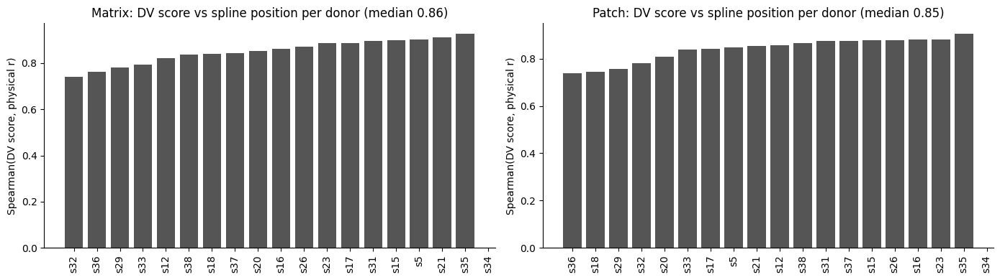

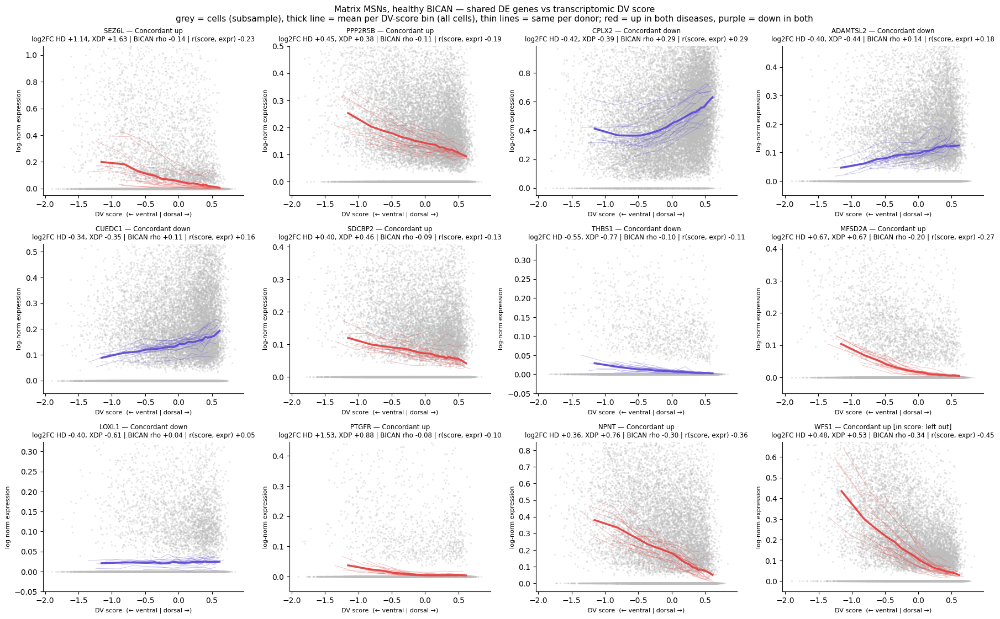

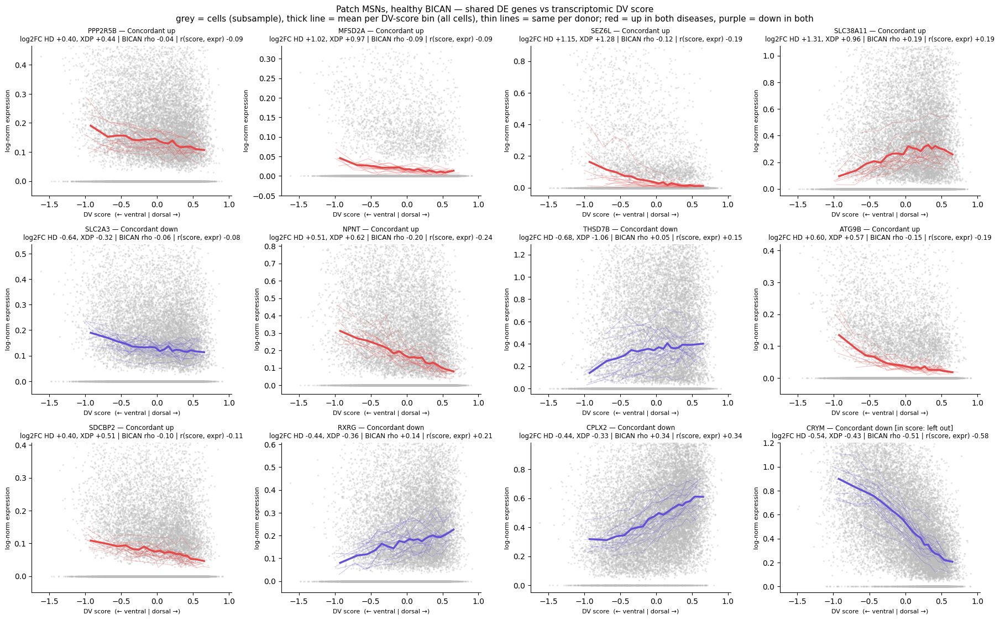

In [ ]:
# ── Expression of shared DE genes along a transcriptomic dorsal-ventral (DV) score, healthy BICAN cells ──
import os
import anndata as ad
from scipy import sparse
from scipy.stats import spearmanr

BICAN_DIR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated"
CORR_DIR  = f"{BICAN_DIR}/genes_correlation"
COMPARTMENTS = {"Matrix": ["Matrix_D1", "Matrix_D2"], "Patch": ["Patch_D1", "Patch_D2"]}

# which genes to plot: concordant DE genes (HD & XDP), |log2FC| >= threshold in both, most robust first
LOGFC_PLOT_THR = 0.3
N_GENES_PLOT   = 12
MAX_CELLS_PLOT = 20000   # random subsample of cells drawn as dots (trend lines use all cells)
Z_CLIP         = 5       # clip z-scores so a few extreme cells cannot dominate the score

# ---------- 1) Score genes and weights: stable gradient genes (your selection) ----------
# Strong gradient (|rho| >= 0.2) with the SAME sign in healthy BICAN and XDP, well expressed.
# Weight = mean rho (health, XDP). rho > 0 = dorsal-high -> high score = more DORSAL cell.
STABLE_GRAD_THR, STABLE_GRAD_PADJ_THR = 0.2, 0.05
STABLE_GRAD_MIN_PCT_EXPR, STABLE_GRAD_MIN_MEAN_EXPR = 0.20, 0.10

corr_h = pd.read_csv(f"{CORR_DIR}/df_corr.csv", index_col=0)
corr_x = pd.read_csv(f"{CORR_DIR}/df_corr_xdp.csv", index_col=0)
common = corr_h.index.intersection(corr_x.index)

dv_weights = {}
for comp in COMPARTMENTS:
    h, x = corr_h.loc[common], corr_x.loc[common]
    reliable = lambda d: ((d[f"padj_{comp}"] < STABLE_GRAD_PADJ_THR) &
                          (d[f"pct_expr_{comp}"] >= STABLE_GRAD_MIN_PCT_EXPR) &
                          (d[f"mean_expr_{comp}"] >= STABLE_GRAD_MIN_MEAN_EXPR))
    stable = ((h[f"rho_{comp}"].abs() >= STABLE_GRAD_THR) & (x[f"rho_{comp}"].abs() >= STABLE_GRAD_THR) &
              (np.sign(h[f"rho_{comp}"]) == np.sign(x[f"rho_{comp}"])) & reliable(h) & reliable(x)).fillna(False)
    dv_weights[comp] = ((h[f"rho_{comp}"] + x[f"rho_{comp}"]) / 2)[stable]
    print(f"{comp}: {stable.sum()} stable gradient genes "
          f"({(dv_weights[comp] > 0).sum()} dorsal-high, {(dv_weights[comp] < 0).sum()} ventral-high)")

# ---------- 2) Genes to plot ----------
genes_to_plot = {}
for comp in COMPARTMENTS:
    de = load_hd_xdp(comp)   # from the cell above
    conc = de[de["category"].isin(["Concordant up", "Concordant down"]) &
              (de["logFC_HD"].abs() >= LOGFC_PLOT_THR) & (de["logFC_XDP"].abs() >= LOGFC_PLOT_THR)]
    genes_to_plot[comp] = (conc.assign(score=conc[["padj_HD", "padj_XDP"]].max(axis=1))   # weaker FDR = robust in BOTH
                               .nsmallest(N_GENES_PLOT, "score").set_index("gene"))
    print(f"{comp}: plotting {len(genes_to_plot[comp])} genes -> {genes_to_plot[comp].index.tolist()}")


# ---------- 3) Load BICAN cells (log-normalized), keep only the genes we need ----------
def load_bican_compartment(comp, genes_needed):
    parts = []
    for sub in COMPARTMENTS[comp]:
        a = ad.read_h5ad(f"{BICAN_DIR}/{sub}.h5ad")          # X = raw counts
        sc.pp.normalize_total(a, target_sum=1e4)              # library size on ALL genes, before subsetting
        sc.pp.log1p(a)
        a = a[:, [g for g in genes_needed if g in a.var_names]].copy()
        a.obs = a.obs[["donor_id"]].assign(subtype=sub)
        parts.append(a)
    return ad.concat(parts, join="inner")


def attach_physical_r(adata):
    # Spline position r per cell, normalized 0-1 within each donor (same as the gradient notebook).
    adata.obs["r"] = np.nan
    for donor in adata.obs["donor_id"].unique():
        f = f"{BICAN_DIR}/for_splines/{donor}_x_y_with_splines.csv"
        if not os.path.exists(f):
            continue
        sp = pd.read_csv(f, index_col=0)
        sp.index = sp.index.astype(str)
        idx = sp.index.intersection(adata.obs_names)
        adata.obs.loc[idx, "r"] = (sp["r"] / sp["r"].max()).loc[idx]


# ---------- 4) DV score = weighted mean of clipped z-scores ----------
def dv_contributions(adata, weights):
    # Returns C (cells x score genes, = w * z) and W (= sum |w|).  DV score = C.sum(1) / W.
    # z uses mean/sd of each subtype (D1 / D2) separately, so D1/D2 identity does not enter the score.
    genes = [g for g in weights.index if g in adata.var_names]
    X = adata[:, genes].X
    X = X.toarray() if sparse.issparse(X) else np.asarray(X)
    Z = np.zeros_like(X, dtype=float)
    for sub in adata.obs["subtype"].unique():
        m = (adata.obs["subtype"] == sub).values
        Z[m] = np.clip((X[m] - X[m].mean(0)) / (X[m].std(0) + 1e-9), -Z_CLIP, Z_CLIP)
    w = weights.loc[genes]
    return pd.DataFrame(Z * w.values, index=adata.obs_names, columns=genes), w.abs().sum()


def dv_score_without(C, W, weights, gene):
    # Leave-one-out: DV score recomputed WITHOUT `gene` (avoids circularity when gene is a score gene).
    if gene in C.columns:
        return (C.values.sum(1) - C[gene].values) / (W - abs(weights[gene]))
    return C.values.sum(1) / W


bican, contrib = {}, {}
for comp in COMPARTMENTS:
    genes_needed = list(dict.fromkeys(dv_weights[comp].index.tolist() + genes_to_plot[comp].index.tolist()))
    bican[comp] = load_bican_compartment(comp, genes_needed)
    attach_physical_r(bican[comp])
    contrib[comp] = dv_contributions(bican[comp], dv_weights[comp])
    bican[comp].obs["dv_score"] = contrib[comp][0].values.sum(1) / contrib[comp][1]
    print(f"{comp}: {bican[comp].n_obs} cells, {contrib[comp][0].shape[1]} score genes")

# ---------- 5) Sanity check: does the DV score follow physical position in every donor? ----------
fig, axes = plt.subplots(1, len(COMPARTMENTS), figsize=(7 * len(COMPARTMENTS), 4), squeeze=False)
for ax, comp in zip(axes[0], COMPARTMENTS):
    obs = bican[comp].obs.dropna(subset=["r"])
    per_donor = (obs.groupby("donor_id").filter(lambda d: len(d) >= 200)
                    .groupby("donor_id").apply(lambda d: spearmanr(d["dv_score"], d["r"])[0])
                    .sort_values())
    ax.bar(per_donor.index, per_donor.values, color="#555555")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylabel("Spearman(DV score, physical r)")
    ax.set_title(f"{comp}: DV score vs spline position per donor (median {per_donor.median():.2f})")
    ax.tick_params(axis="x", rotation=90); sns.despine(ax=ax)
plt.tight_layout(); plt.show()

# ---------- 6) One panel per gene: expression vs DV score ----------
COL_DIR = {"Concordant up": "#e34948", "Concordant down": "#6250d6"}
rng = np.random.default_rng(0)

for comp in COMPARTMENTS:
    a, (C, W), table = bican[comp], contrib[comp], genes_to_plot[comp]
    donors = a.obs["donor_id"].values
    big_donors = a.obs["donor_id"].value_counts().loc[lambda s: s >= 500].index
    dots = rng.choice(a.n_obs, size=min(MAX_CELLS_PLOT, a.n_obs), replace=False)

    ncols = 4
    nrows = int(np.ceil(len(table) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.8 * nrows), squeeze=False)

    for ax, (gene, row) in zip(axes.flat, table.iterrows()):
        x = dv_score_without(C, W, dv_weights[comp], gene)                       # DV score without this gene
        y = a[:, gene].X
        y = y.toarray().ravel() if sparse.issparse(y) else np.asarray(y).ravel()  # log-normalized expression
        color = COL_DIR[row["category"]]

        # dots: random subsample of cells
        ax.scatter(x[dots], y[dots], s=2, color="#bdbdbd", alpha=0.25, rasterized=True)

        # thin lines: mean expression per DV-score decile, for each donor (>= 500 cells) -> consistency across donors
        for donor in big_donors:
            m = donors == donor
            per = pd.DataFrame({"x": x[m], "y": y[m]}).groupby(pd.qcut(x[m], 10, duplicates="drop"), observed=True).mean()
            ax.plot(per["x"], per["y"], color=color, lw=0.7, alpha=0.35)

        # thick line: mean expression per DV-score bin, all cells pooled
        pooled = pd.DataFrame({"x": x, "y": y}).groupby(pd.qcut(x, 20, duplicates="drop"), observed=True).mean()
        ax.plot(pooled["x"], pooled["y"], color=color, lw=2.5)

        # zoom on the range where the trend lives (single-cell expression is zero-inflated)
        top = np.quantile(y[y > 0], 0.95) if (y > 0).any() else 1
        ax.set_ylim(-0.05, max(top, pooled["y"].max() * 1.3))

        rho_bican = corr_h[f"rho_{comp}"].get(gene, np.nan)
        r_score   = spearmanr(x, y)[0]
        in_score  = " [in score: left out]" if gene in C.columns else ""
        ax.set_title(f"{gene} — {row['category']}{in_score}\n"
                     f"log2FC HD {row['logFC_HD']:+.2f}, XDP {row['logFC_XDP']:+.2f} | "
                     f"BICAN rho {rho_bican:+.2f} | r(score, expr) {r_score:+.2f}", fontsize=8.5)
        ax.set_xlabel("DV score  (← ventral | dorsal →)", fontsize=8)
        ax.set_ylabel("log-norm expression", fontsize=8)
        sns.despine(ax=ax)

    for ax in axes.flat[len(table):]:
        ax.set_visible(False)
    fig.suptitle(f"{comp} MSNs, healthy BICAN — shared DE genes vs transcriptomic DV score\n"
                 f"grey = cells (subsample), thick line = mean per DV-score bin (all cells), "
                 f"thin lines = same per donor; red = up in both diseases, purple = down in both", fontsize=11)
    plt.tight_layout(); plt.show()


Matrix: plotting 29 genes -> ['SEZ6L', 'PPP2R5B', 'CPLX2', 'ADAMTSL2', 'CUEDC1', 'SDCBP2', 'THBS1', 'MFSD2A', 'LOXL1', 'PTGFR', 'NPNT', 'WFS1', 'MATN4', 'C2orf66', 'NEURL1B', 'TOX2', 'MGC27382', 'KCNJ1', 'MAJIN', 'NALCN-AS1', 'RASD1', 'RASGRF2', 'GCK', 'STARD13-AS', 'PTER', 'POT1-AS1', 'PTTG1', 'RGS9', 'MYPN']
Patch: plotting 30 genes -> ['PPP2R5B', 'MFSD2A', 'SEZ6L', 'SLC38A11', 'SLC2A3', 'NPNT', 'THSD7B', 'ATG9B', 'SDCBP2', 'RXRG', 'CPLX2', 'CRYM', 'LGI3', 'NALCN-AS1', 'PREX2', 'HDAC9', 'EYA4', 'LINC01435', 'LAMA5', 'SYT13', 'LINC01494', 'CACNG5', 'RGS9', 'LINC00240', 'COL1A1', 'RASD1', 'ADCY2', 'VRK2', 'HACD1', 'CHST2']
  s34: no spline file, cells dropped
Matrix: 91544 cells with a spline position -> 91544 kept for REGION = 'all'
  s34: no spline file, cells dropped
Patch: 16563 cells with a spline position -> 16563 kept for REGION = 'all'


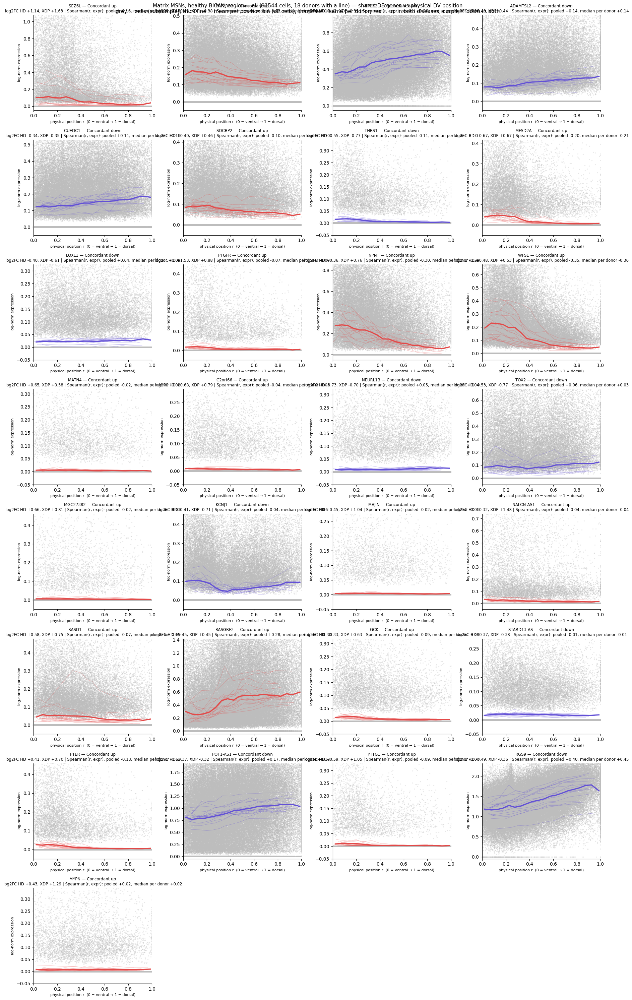

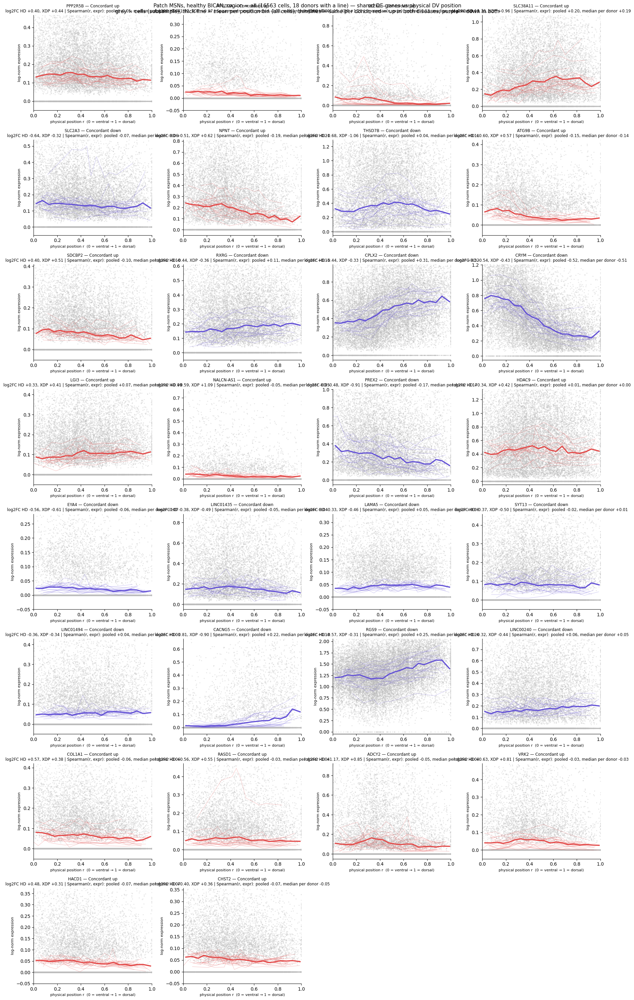

In [ ]:
# ── Expression of shared DE genes along the PHYSICAL dorsal-ventral position (spline r), healthy BICAN cells ──
import os
import anndata as ad
from scipy import sparse
from scipy.stats import spearmanr
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

BICAN_DIR   = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated"
SPLINE_DIR  = f"{BICAN_DIR}/for_splines"
COMPARTMENTS = {"Matrix": ["Matrix_D1", "Matrix_D2"], "Patch": ["Patch_D1", "Patch_D2"]}

REGION = "all"          # "all" = every cell with a spline position | "putamen" = d > 0 | "caudate" = d < 0

LOGFC_PLOT_THR = 0.3    # plot concordant DE genes with |log2FC| >= this in BOTH diseases
N_GENES_PLOT   = 30     # max genes per compartment (most robust in both datasets first)
MAX_CELLS_PLOT = 500000  # random subsample of cells drawn as dots (trend lines use all cells)
MIN_CELLS_DONOR = 300   # donors with fewer cells (after the region filter) get no per-donor line
R_BINS = np.linspace(0, 1, 21)   # 20 bins of physical position for the pooled trend line

# ---------- 1) Genes to plot: concordant DE genes (HD & XDP) ----------
genes_to_plot = {}
for comp in COMPARTMENTS:
    de = load_hd_xdp(comp)   # from the gene-set cell above
    conc = de[de["category"].isin(["Concordant up", "Concordant down"]) &
              (de["logFC_HD"].abs() >= LOGFC_PLOT_THR) & (de["logFC_XDP"].abs() >= LOGFC_PLOT_THR)]
    genes_to_plot[comp] = (conc.assign(score=conc[["padj_HD", "padj_XDP"]].max(axis=1))   # weaker FDR = robust in BOTH
                               .nsmallest(N_GENES_PLOT, "score").set_index("gene"))
    print(f"{comp}: plotting {len(genes_to_plot[comp])} genes -> {genes_to_plot[comp].index.tolist()}")


# ---------- 2) Load BICAN cells (log-normalized) + physical position from the spline files ----------
def load_bican_compartment(comp, genes_needed):
    parts = []
    for sub in COMPARTMENTS[comp]:
        a = ad.read_h5ad(f"{BICAN_DIR}/{sub}.h5ad")          # X = raw counts
        sc.pp.normalize_total(a, target_sum=1e4)              # library size on ALL genes, before subsetting
        sc.pp.log1p(a)
        a = a[:, [g for g in genes_needed if g in a.var_names]].copy()
        a.obs = a.obs[["donor_id"]].assign(subtype=sub)
        parts.append(a)
    return ad.concat(parts, join="inner")


def attach_spline_position(adata):
    # r = position along the spline, scaled 0-1 within each donor (0 = ventral, 1 = dorsal).
    # d = signed distance from the spline (d < 0 = caudate, d > 0 = putamen).
    adata.obs["r"], adata.obs["d"] = np.nan, np.nan
    for donor in adata.obs["donor_id"].unique():
        f = f"{SPLINE_DIR}/{donor}_x_y_with_splines.csv"
        if not os.path.exists(f):
            print(f"  {donor}: no spline file, cells dropped")
            continue
        sp = pd.read_csv(f, index_col=0)
        sp.index = sp.index.astype(str)
        sp["r"] = sp["r"] / sp["r"].max()
        idx = sp.index.intersection(adata.obs_names)
        adata.obs.loc[idx, "r"] = sp.loc[idx, "r"]
        adata.obs.loc[idx, "d"] = sp.loc[idx, "d"]
    return adata[adata.obs["r"].notna()].copy()


def select_region(adata, region):
    if region == "putamen":
        return adata[adata.obs["d"] > 0].copy()
    if region == "caudate":
        return adata[adata.obs["d"] < 0].copy()
    return adata


bican = {}
for comp in COMPARTMENTS:
    a = attach_spline_position(load_bican_compartment(comp, genes_to_plot[comp].index.tolist()))
    bican[comp] = select_region(a, REGION)
    print(f"{comp}: {a.n_obs} cells with a spline position -> {bican[comp].n_obs} kept for REGION = '{REGION}'")


# ---------- 3) One panel per gene: expression vs physical position ----------
COL_DIR = {"Concordant up": "#e34948", "Concordant down": "#6250d6"}
rng = np.random.default_rng(0)

for comp in COMPARTMENTS:
    a, table = bican[comp], genes_to_plot[comp]
    x = a.obs["r"].values
    donors = a.obs["donor_id"].values
    big_donors = a.obs["donor_id"].value_counts().loc[lambda s: s >= MIN_CELLS_DONOR].index
    dots = rng.choice(a.n_obs, size=min(MAX_CELLS_PLOT, a.n_obs), replace=False)

    ncols = 4
    nrows = int(np.ceil(len(table) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.8 * nrows), squeeze=False)

    for ax, (gene, row) in zip(axes.flat, table.iterrows()):
        y = a[:, gene].X
        y = y.toarray().ravel() if sparse.issparse(y) else np.asarray(y).ravel()   # log-normalized expression
        color = COL_DIR[row["category"]]

        # dots: random subsample of cells
        ax.scatter(x[dots], y[dots], s=2, color="#bdbdbd", alpha=0.25, rasterized=True)

        # thin lines: mean expression per position decile, for each donor -> is the trend the same in every donor?
        per_donor_r = []
        for donor in big_donors:
            m = donors == donor
            per = pd.DataFrame({"x": x[m], "y": y[m]}).groupby(pd.qcut(x[m], 10, duplicates="drop"), observed=True).mean()
            ax.plot(per["x"], per["y"], color=color, lw=0.7, alpha=0.35)
            per_donor_r.append(spearmanr(x[m], y[m])[0])

        # thick line: mean expression per fixed bin of position, all cells pooled
        pooled = (pd.DataFrame({"x": x, "y": y})
                    .groupby(pd.cut(x, R_BINS, include_lowest=True), observed=True)
                    .agg(x=("x", "mean"), y=("y", "mean"), n=("y", "size")))
        pooled = pooled[pooled["n"] >= 50]          # skip nearly empty bins
        ax.plot(pooled["x"], pooled["y"], color=color, lw=2.5)

        # zoom on the range where the trend lives (single-cell expression is zero-inflated)
        top = np.quantile(y[y > 0], 0.95) if (y > 0).any() else 1
        ax.set_ylim(-0.05, max(top, pooled["y"].max() * 1.3))
        ax.set_xlim(0, 1)

        ax.set_title(f"{gene} — {row['category']}\n"
                     f"log2FC HD {row['logFC_HD']:+.2f}, XDP {row['logFC_XDP']:+.2f} | "
                     f"Spearman(r, expr): pooled {spearmanr(x, y)[0]:+.2f}, "
                     f"median per donor {np.nanmedian(per_donor_r):+.2f}", fontsize=8.5)
        ax.set_xlabel("physical position r  (0 = ventral → 1 = dorsal)", fontsize=8)
        ax.set_ylabel("log-norm expression", fontsize=8)
        sns.despine(ax=ax)

    for ax in axes.flat[len(table):]:
        ax.set_visible(False)
    fig.suptitle(f"{comp} MSNs, healthy BICAN, region = {REGION} ({a.n_obs} cells, {len(big_donors)} donors with a line) — "
                 f"shared DE genes vs physical DV position\n"
                 f"grey = cells (subsample), thick line = mean per position bin (all cells), thin lines = same per donor; "
                 f"red = up in both diseases, purple = down in both", fontsize=11)
    plt.tight_layout(); plt.show()


# Gene Length

In [ ]:
# ── Does gene length / structural complexity relate to DE status? HD and XDP tested separately ──
#
# Gene structure comes from local Ensembl GTFs (same files as Ensembl FTP). Several releases are used because the
# two DE tables use different gene naming: HD = old symbols (Ensembl ~93), XDP = 10x GRCh38-2024-A (Ensembl 110,
# unnamed genes kept as ENSG ids). Each gene name is resolved to its Ensembl gene_id (newest release first), and
# the structure metrics are taken from the newest release that has that gene_id (only releases >= 110 tag the
# Ensembl_canonical transcript). Result is cached to CSV, so the slow GTF parsing (~3 min) runs once.
#
# Model (one per dataset x metric, metrics tested one at a time because they are strongly correlated):
#   is_DE ~ z(metric) + z(baseline expression)            -> tested coefficient: z(metric)
#   is_up ~ z(metric) + z(baseline expression), DE genes  -> tested coefficient: z(metric)
# Baseline expression = nebula intercept (log mean expression in controls). It is included because long genes
# collect more (intronic) reads in snRNA-seq, so they have more power to be called DE.
import os
import urllib.request
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
import pandas as pd

GTF_DIR    = "/home/gdallagl/myworkdir/data/BioMart/ensembl_scan"
RELEASES   = ["rel116", "rel110", "rel106", "rel93"]           # newest first = priority
GTF_URL    = "https://ftp.ensembl.org/pub/release-{n}/gtf/homo_sapiens/Homo_sapiens.GRCh38.{n}.gtf.gz"  # used only if a file is missing
STRUCT_CSV = f"{GTF_DIR}/gene_structure_ensembl_multi_release.csv"   # cache

CT_LENGTH = ["Matrix", "Patch"]   # cell types to analyse
PADJ = 0.05                       # FDR threshold to call a gene DE

# metric column -> (label, plot/test on log10(x + 1)?)
METRICS = {
    "span_bp":             ("gene span (bp)",                  True),
    "exonic_bp":           ("exonic bp (all isoforms merged)", True),
    "intronic_bp":         ("intronic bp",                     True),
    "mrna_len_canonical":  ("mRNA length, canonical (bp)",     True),
    "n_exons_canonical":   ("# exons, canonical",              True),
    "n_introns_canonical": ("# introns, canonical",            True),
    "n_transcripts":       ("# annotated isoforms",            True),
    "intron_frac":         ("intronic fraction of gene",       False),
}
COL_DS = {"HD": "#2a78d6", "XDP": "#eb6834"}


# ---------- 1) Gene structure table ----------
def build_gene_structure(gtf_path):
    # One row per gene_id: span, exonic/intronic bp, canonical exon count and mRNA length, # isoforms.
    cols = ["chrom", "source", "feature", "start", "end", "score", "strand", "frame", "attr"]
    parts = []
    for chunk in pd.read_csv(gtf_path, sep="\t", comment="#", header=None, names=cols,
                             usecols=["feature", "start", "end", "attr"], dtype={"feature": str}, chunksize=500_000):
        chunk = chunk[chunk["feature"] == "exon"]
        a = chunk["attr"]
        parts.append(pd.DataFrame({
            "gene_id":       a.str.extract(r'gene_id "([^"]+)"', expand=False),
            "gene_name":     a.str.extract(r'gene_name "([^"]+)"', expand=False),
            "biotype":       a.str.extract(r'gene_biotype "([^"]+)"', expand=False),
            "transcript_id": a.str.extract(r'transcript_id "([^"]+)"', expand=False),
            "canonical":     a.str.contains('tag "Ensembl_canonical"', regex=False),
            "start":         chunk["start"],
            "end":           chunk["end"],
        }))
    ex = pd.concat(parts, ignore_index=True)
    ex["len"] = ex["end"] - ex["start"] + 1

    g = ex.groupby("gene_id")
    out = pd.DataFrame({"gene_name":     g["gene_name"].first(),
                        "biotype":       g["biotype"].first(),
                        "span_bp":       g["end"].max() - g["start"].min() + 1,
                        "n_transcripts": g["transcript_id"].nunique()})

    # exonic bp = union of the exons of all isoforms (overlapping exons merged into blocks)
    ex = ex.sort_values(["gene_id", "start"]).reset_index(drop=True)
    prev_end = ex.groupby("gene_id")["end"].cummax().groupby(ex["gene_id"]).shift()
    ex["block"] = (prev_end.isna() | (ex["start"] > prev_end)).cumsum()
    blocks = ex.groupby(["gene_id", "block"]).agg(start=("start", "min"), end=("end", "max"))
    out["exonic_bp"]   = (blocks["end"] - blocks["start"] + 1).groupby(level="gene_id").sum()
    out["intronic_bp"] = out["span_bp"] - out["exonic_bp"]
    out["intron_frac"] = out["intronic_bp"] / out["span_bp"]

    # canonical transcript (tag present only in recent releases; NaN otherwise)
    canon = ex[ex["canonical"]]
    out["n_exons_canonical"]   = canon.groupby("gene_id").size()
    out["mrna_len_canonical"]  = canon.groupby("gene_id")["len"].sum()
    out["n_introns_canonical"] = out["n_exons_canonical"] - 1
    return out.reset_index()


if os.path.exists(STRUCT_CSV):
    gene_struct = pd.read_csv(STRUCT_CSV, index_col=0)
else:
    per_rel = {}
    for rel in RELEASES:
        path = f"{GTF_DIR}/{rel}.gtf.gz"
        if not os.path.exists(path):
            urllib.request.urlretrieve(GTF_URL.format(n=rel.replace("rel", "")), path)
        per_rel[rel] = build_gene_structure(path)
        print(f"parsed {rel}: {len(per_rel[rel])} genes")

    # metrics per gene_id, from the newest release that has it
    metrics_by_id = (pd.concat([t.assign(release=r) for r, t in per_rel.items()])
                       .drop_duplicates("gene_id").set_index("gene_id").drop(columns="gene_name"))

    # name -> gene_id lookup (newest release first; within a release prefer protein-coding, then longest),
    # plus every gene_id as its own key (XDP keeps unnamed genes as ENSG ids)
    keys = []
    for r, t in per_rel.items():
        named = (t[t["gene_name"].notna()].assign(is_pc=lambda d: d["biotype"] == "protein_coding")
                   .sort_values(["is_pc", "span_bp"], ascending=False).drop_duplicates("gene_name"))
        keys += [pd.DataFrame({"key": named["gene_name"], "gene_id": named["gene_id"]}),
                 pd.DataFrame({"key": t["gene_id"],       "gene_id": t["gene_id"]})]
    lookup = pd.concat(keys).drop_duplicates("key").set_index("key")

    gene_struct = lookup.join(metrics_by_id, on="gene_id")
    gene_struct.to_csv(STRUCT_CSV)
print(f"gene structure table: {len(gene_struct)} keys")


def metric_values(df, col):
    # Values used for plots and tests: log10(x + 1) for bp / counts, raw for fractions.
    return np.log10(df[col] + 1) if METRICS[col][1] else df[col]


# ---------- 2) Load one DE table and attach gene structure ----------
def load_de_with_structure(dataset, ct):
    if dataset == "HD":
        df = pd.read_csv(f"/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/{method}/{ct}/deg_results_formatted.csv")
        df = df.rename(columns={"logFC_StatusCase": "logFC", "p_StatusCase": "p"})
    else:
        df = pd.read_csv(f"/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/{method}/{ct}/deg_results_formatted.csv")
        df = df.rename(columns={"logFC_conditionXDP": "logFC", "p_conditionXDP": "p"})
    df = df.rename(columns={"logFC_(Intercept)": "baseline_expr"}).dropna(subset=["logFC", "p"])
    df["padj"] = multipletests(df["p"], method=METHOD_MULTIPLE_TEST)[1]      # BH on ALL genes of the table
    df["DE"] = np.select([(df["padj"] < PADJ) & (df["logFC"] > 0), (df["padj"] < PADJ) & (df["logFC"] < 0)],
                         ["up", "down"], default="not DE")
    n_all = len(df)
    df = df.merge(gene_struct[list(METRICS)], left_on="gene", right_index=True, how="inner")
    print(f"{dataset} {ct}: {len(df)}/{n_all} genes matched to gene structure "
          f"({(df['DE'] == 'up').sum()} up, {(df['DE'] == 'down').sum()} down)")
    return df


# ---------- 3) Statistics: one logistic model per dataset x metric ----------
def length_stats(df, col):
    d = pd.DataFrame({"x": metric_values(df, col), "expr": df["baseline_expr"], "DE": df["DE"], "logFC": df["logFC"]}).dropna()
    d["x"]    = (d["x"] - d["x"].mean()) / d["x"].std()          # z-score -> odds ratio per 1 SD of the metric
    d["expr"] = (d["expr"] - d["expr"].mean()) / d["expr"].std()
    d["is_DE"] = (d["DE"] != "not DE").astype(int)
    res = {"n_genes": len(d), "spearman_logFC": spearmanr(d["x"], d["logFC"])[0]}

    m = smf.logit("is_DE ~ x + expr", data=d).fit(disp=0)                       # DE vs not DE
    res.update(OR_DE=np.exp(m.params["x"]), lo_DE=np.exp(m.conf_int().loc["x", 0]),
               hi_DE=np.exp(m.conf_int().loc["x", 1]), p_DE=m.pvalues["x"])

    de = d[d["is_DE"] == 1].assign(is_up=lambda x: (x["DE"] == "up").astype(int))   # up vs down, DE genes only
    if len(de) >= 20 and de["is_up"].nunique() == 2:
        m2 = smf.logit("is_up ~ x + expr", data=de).fit(disp=0)
        res.update(OR_up=np.exp(m2.params["x"]), lo_up=np.exp(m2.conf_int().loc["x", 0]),
                   hi_up=np.exp(m2.conf_int().loc["x", 1]), p_up=m2.pvalues["x"])
    return res


# ---------- 4) Plots ----------
def plot_volcano_by_metric(df, dataset, ct):
    # Volcano (log2FC vs -log10 p) colored by each metric. Random drawing order so no value hides the others.
    d = df.sample(frac=1, random_state=0)
    y = -np.log10(d["p"].clip(lower=1e-300))
    p_thr = d.loc[d["padj"] < PADJ, "p"].max()                    # raw p corresponding to FDR = PADJ
    fig, axes = plt.subplots(2, 4, figsize=(22, 9))
    for ax, (col, (label, is_log)) in zip(axes.flat, METRICS.items()):
        v = metric_values(d, col)
        lo, hi = np.nanpercentile(v, [2, 98])                     # clip color scale to the 2-98th percentile
        pts = ax.scatter(d["logFC"], y, c=v, cmap="RdBu", vmin=lo, vmax=hi, s=5, alpha=0.8, rasterized=True)
        fig.colorbar(pts, ax=ax).set_label(("log10 " if is_log else "") + label, fontsize=8)
        if pd.notna(p_thr):
            ax.axhline(-np.log10(p_thr), color="grey", ls="--", lw=0.8)
        ax.axvline(0, color="grey", lw=0.5)
        ax.set_title(label, fontsize=10); ax.set_xlabel("log2FC"); ax.set_ylabel("-log10 p")
        sns.despine(ax=ax)
    fig.suptitle(f"{dataset} – {ct} ({method}): volcano colored by gene structure (dashed = FDR {PADJ})", fontsize=12)
    plt.tight_layout(); plt.show()


def plot_de_by_decile(dfs, ct):
    # % of genes DE up (solid) / down (dashed) in each decile of the metric (1 = shortest/simplest, 10 = longest/most complex).
    fig, axes = plt.subplots(2, 4, figsize=(22, 8.5))
    for ax, (col, (label, _)) in zip(axes.flat, METRICS.items()):
        for ds, df in dfs.items():
            v = metric_values(df, col)
            ok = v.notna()
            dec = pd.qcut(v[ok].rank(method="first"), 10, labels=range(1, 11))   # rank first: ties split evenly
            frac = pd.crosstab(dec, df.loc[ok, "DE"], normalize="index").reindex(columns=["up", "down"], fill_value=0) * 100
            ax.plot(frac.index.astype(int), frac["up"],   color=COL_DS[ds], marker="^", lw=2,  label=f"{ds} up")
            ax.plot(frac.index.astype(int), frac["down"], color=COL_DS[ds], marker="v", lw=2, ls="--", label=f"{ds} down")
        ax.set_xticks(range(1, 11)); ax.set_title(label, fontsize=10)
        ax.set_xlabel("decile (1 = low … 10 = high)"); ax.set_ylabel("% of genes DE")
        sns.despine(ax=ax)
    axes.flat[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"{ct} ({method}): fraction of DE genes along each gene-structure metric (not adjusted for expression)", fontsize=12)
    plt.tight_layout(); plt.show()


def plot_forest(stats, ct):
    # Odds ratio per 1 SD of each metric, adjusted for baseline expression, with 95% CI.
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    labels = [METRICS[c][0] for c in METRICS]
    y = np.arange(len(labels))
    for ax, (key, title) in zip(axes, [("DE", "DE vs not DE\n(OR > 1: higher metric → more often DE)"),
                                       ("up", "Up vs down, DE genes only\n(OR > 1: higher metric → more often UP)")]):
        for k, ds in enumerate(["HD", "XDP"]):
            s = stats[stats["dataset"] == ds].set_index("metric").reindex(list(METRICS))
            if f"OR_{key}" not in s:
                continue
            yy = y + (k - 0.5) * 0.3
            ax.errorbar(s[f"OR_{key}"], yy, xerr=[s[f"OR_{key}"] - s[f"lo_{key}"], s[f"hi_{key}"] - s[f"OR_{key}"]],
                        fmt="o", color=COL_DS[ds], capsize=3, label=ds)
            for yi, (orv, pv) in zip(yy, zip(s[f"OR_{key}"], s[f"p_{key}"])):   # star = p < 0.05 / number of metrics
                if pd.notna(pv) and pv < 0.05 / len(METRICS):
                    ax.text(orv, yi + 0.12, "*", ha="center", fontsize=12, color=COL_DS[ds])
        ax.axvline(1, color="black", lw=0.8)
        ax.set_xscale("log"); ax.set_title(title, fontsize=10); ax.set_xlabel("odds ratio per 1 SD (log scale)")
        ax.legend(frameon=False); sns.despine(ax=ax)
    axes[0].set_yticks(y); axes[0].set_yticklabels(labels); axes[0].invert_yaxis()
    fig.suptitle(f"{ct} ({method}): gene structure vs DE, adjusted for baseline expression (* = p < 0.05/{len(METRICS)})", fontsize=12)
    plt.tight_layout(); plt.show()




parsed rel116: 78941 genes
parsed rel110: 62754 genes
parsed rel106: 61552 genes
parsed rel93: 58395 genes
gene structure table: 143624 keys


NameError: name 'method' is not defined

In [ ]:
# ---------- 4) Plots ----------
def plot_volcano_by_metric(df, dataset, ct):
    # Volcano (log2FC vs -log10 p) colored by each metric. Random drawing order so no value hides the others.
    d = df.sample(frac=1, random_state=0)
    y = -np.log10(d["p"].clip(lower=1e-300))
    p_thr = d.loc[d["padj"] < PADJ, "p"].max()                    # raw p corresponding to FDR = PADJ
    fig, axes = plt.subplots(2, 4, figsize=(22, 9))
    for ax, (col, (label, is_log)) in zip(axes.flat, METRICS.items()):
        v = metric_values(d, col)
        lo, hi = np.nanpercentile(v, [2, 98])                     # clip color scale to the 2-98th percentile
        pts = ax.scatter(d["logFC"], y, c=v, cmap="viridis", vmin=lo, vmax=hi, s=5, alpha=0.8, rasterized=True)
        fig.colorbar(pts, ax=ax).set_label(("log10 " if is_log else "") + label, fontsize=8)
        if pd.notna(p_thr):
            ax.axhline(-np.log10(p_thr), color="grey", ls="--", lw=0.8)
        ax.axvline(0, color="grey", lw=0.5)
        ax.set_title(label, fontsize=10); ax.set_xlabel("log2FC"); ax.set_ylabel("-log10 p")
        sns.despine(ax=ax)
    fig.suptitle(f"{dataset} – {ct} ({method}): volcano colored by gene structure (dashed = FDR {PADJ})", fontsize=12)
    plt.tight_layout(); plt.show()

HD Matrix: 20866/21285 genes matched to gene structure (1168 up, 3378 down)
XDP Matrix: 20277/20794 genes matched to gene structure (546 up, 477 down)


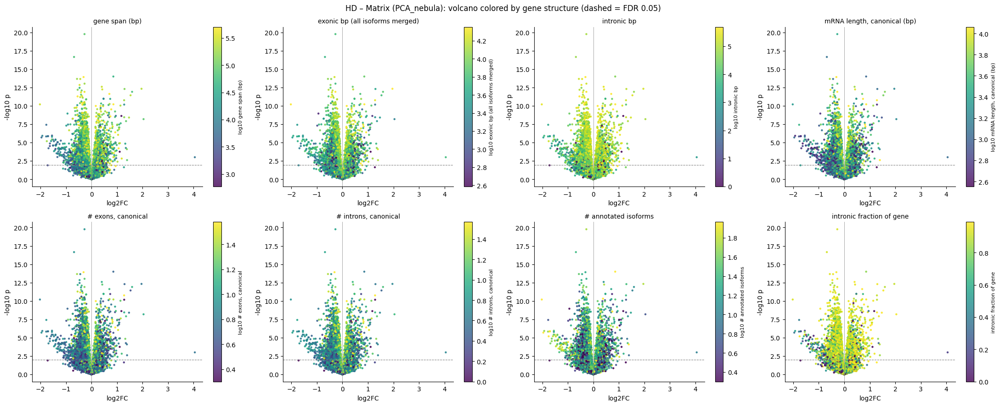

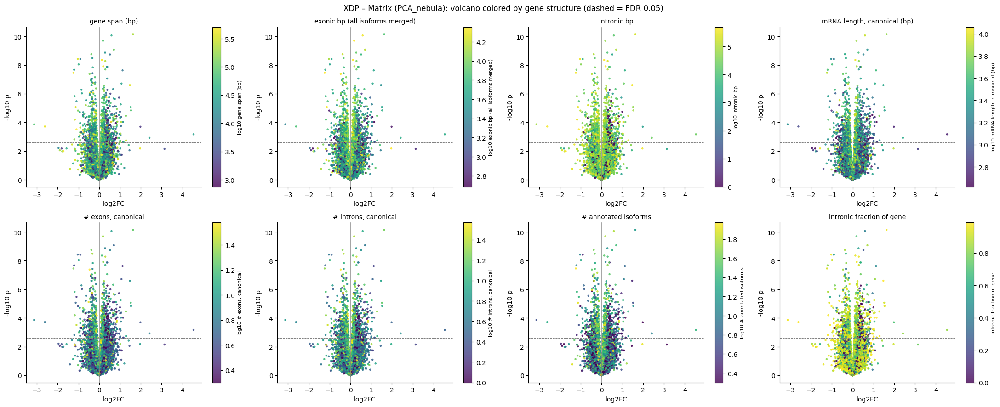

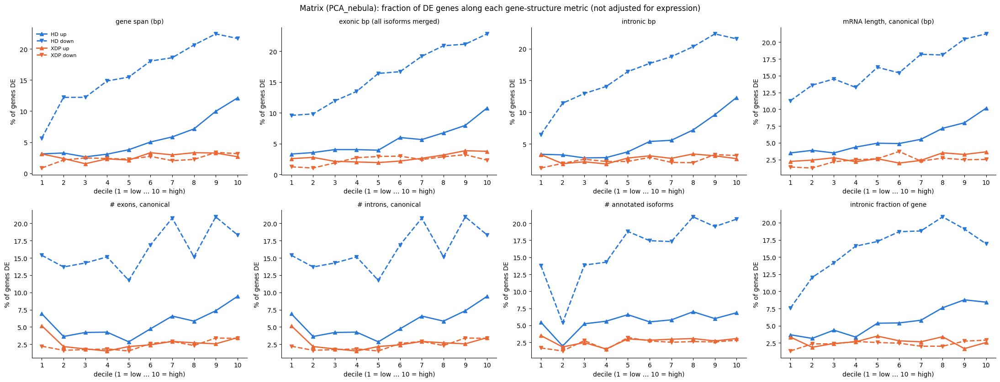

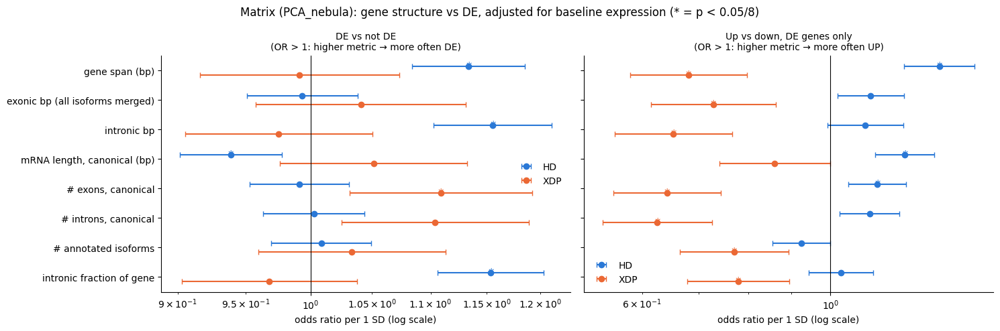

HD Patch: 16224/16510 genes matched to gene structure (1045 up, 1646 down)
XDP Patch: 16504/16824 genes matched to gene structure (581 up, 487 down)


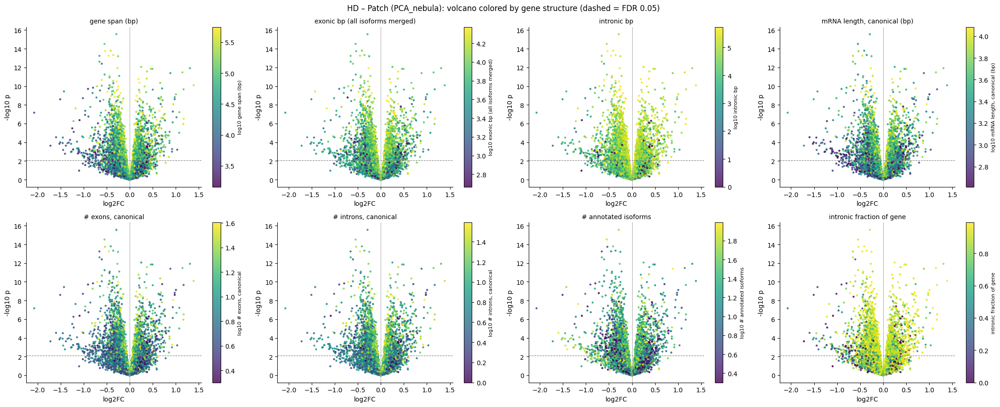

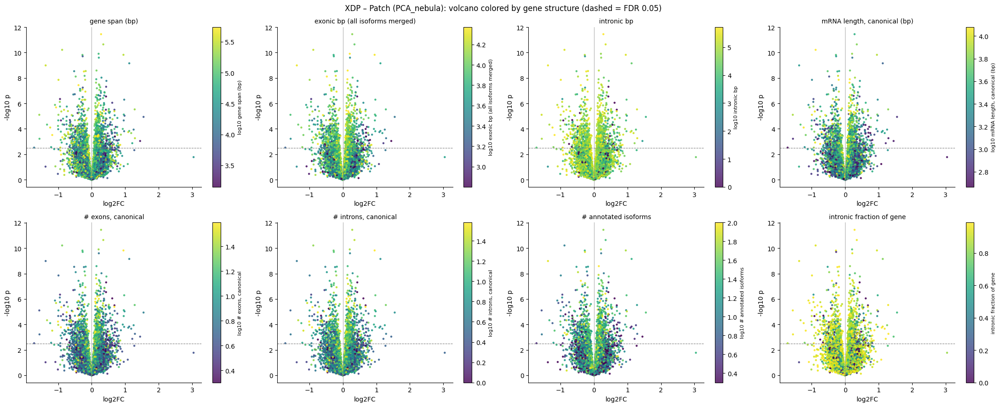

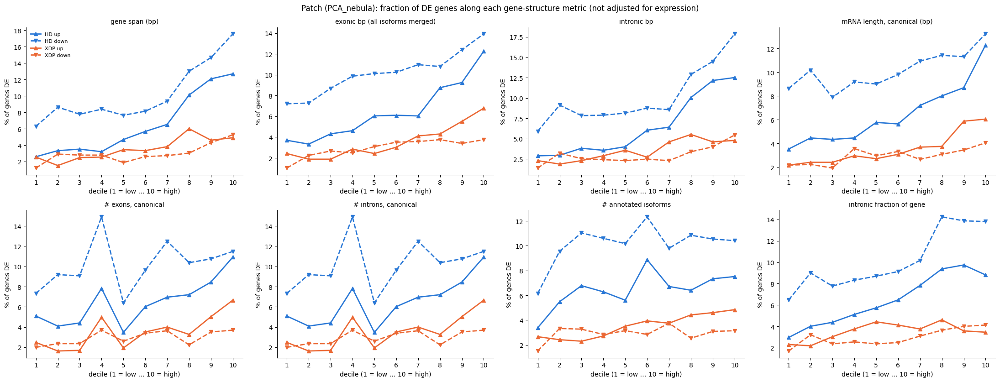

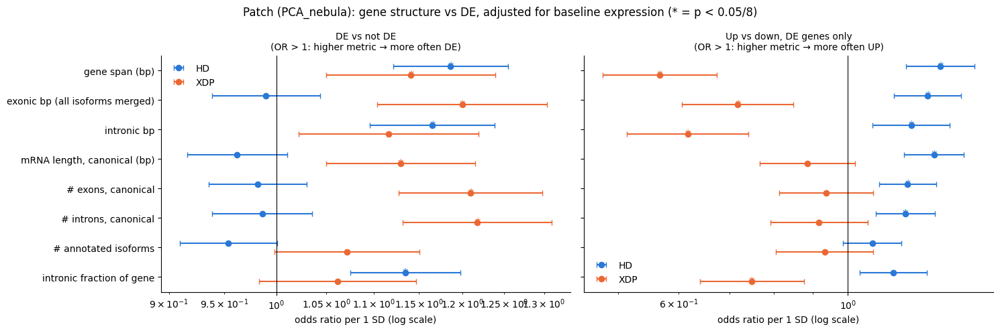

,cell_type,dataset,metric,n_genes,spearman_logFC,OR_DE,p_DE,OR_up,p_up
0,Matrix,HD,span_bp,20866,0.0469,1.1337,0.0000,1.3448,0.0000
1,Matrix,HD,exonic_bp,20866,0.0412,0.9934,0.7673,1.1161,0.0164
2,Matrix,HD,intronic_bp,20866,0.0434,1.1556,0.0000,1.0995,0.0703
3,Matrix,HD,mrna_len_canonical,20678,0.0582,0.9387,0.0022,1.2242,0.0000
4,Matrix,HD,n_exons_canonical,20678,0.0330,0.9910,0.6554,1.1363,0.0014
5,Matrix,HD,n_introns_canonical,20678,0.0330,1.0027,0.8935,1.1126,0.0104
6,Matrix,HD,n_transcripts,20866,0.0038,1.0086,0.6750,0.9243,0.0469
7,Matrix,HD,intron_frac,20866,0.0104,1.1538,0.0000,1.0297,0.5138
8,Matrix,XDP,span_bp,20277,-0.0688,0.9914,0.8315,0.6807,0.0000
9,Matrix,XDP,exonic_bp,20277,-0.0524,1.0407,0.3470,0.7282,0.0002


In [ ]:
# ---------- 5) Run ----------
all_stats = []
for ct in CT_LENGTH:
    dfs = {ds: load_de_with_structure(ds, ct) for ds in ["HD", "XDP"]}

    for ds, df in dfs.items():
        plot_volcano_by_metric(df, ds, ct)
    plot_de_by_decile(dfs, ct)

    stats = pd.DataFrame([{"cell_type": ct, "dataset": ds, "metric": col, **length_stats(df, col)}
                          for ds, df in dfs.items() for col in METRICS])
    plot_forest(stats, ct)
    all_stats.append(stats)

length_results = pd.concat(all_stats, ignore_index=True)
display(length_results[["cell_type", "dataset", "metric", "n_genes", "spearman_logFC",
                        "OR_DE", "p_DE", "OR_up", "p_up"]].round(4))


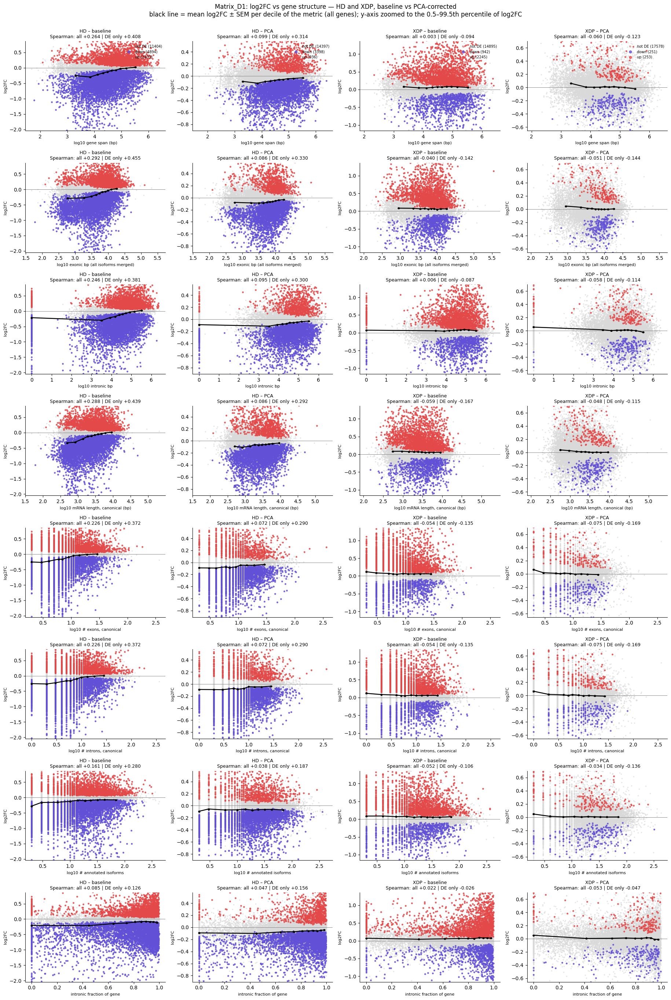

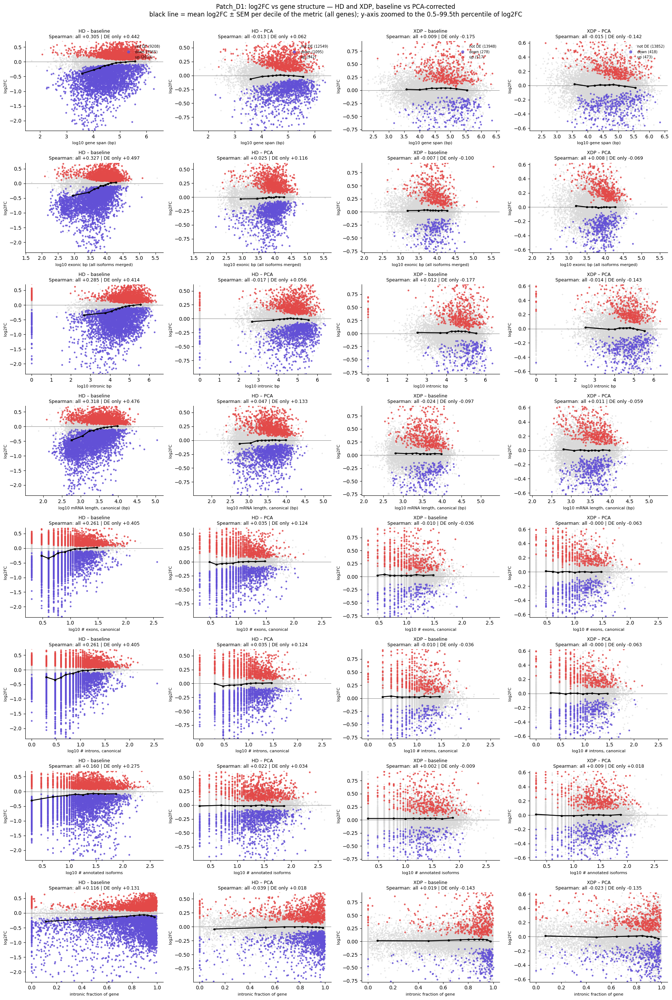

In [ ]:
# ── log2FC vs gene-structure metric, per disease and DE method (baseline vs PCA-corrected) ──
# Needs from the gene-length cell above: gene_struct, METRICS, metric_values.
# One figure per cell type: rows = metrics, columns = HD baseline | HD PCA | XDP baseline | XDP PCA.
# Grey = not DE, red = DE up, purple = DE down (FDR < PADJ). Black line = mean log2FC (± SEM) per decile of the
# metric, all genes: the trend is small, so this line is what to read. Title = Spearman(metric, log2FC).
from scipy.stats import spearmanr

CT_SCATTER      = ["Matrix_D1", "Patch_D1"]   # HD baseline exists only for the D1/D2 subtypes
METHODS_SCATTER = ["baseline_nebula", "PCA_nebula"]
METRICS_SCATTER = list(METRICS)               # or a subset, e.g. ["span_bp", "intronic_bp", "n_introns_canonical"]
PADJ = 0.05
YLIM_PCT = (0.5, 99.5)                        # y-axis zoom: percentiles of log2FC (a few extreme genes fall outside)
COL_DE = {"not DE": "#d9d9d9", "up": "#e34948", "down": "#6250d6"}


def load_de_struct(dataset, method_name, ct):
    # One DE table + gene-structure metrics. Returns None if the table does not exist.
    if dataset == "HD":
        path = f"/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/{method_name}/{ct}/deg_results_formatted.csv"
        cols = {"logFC_StatusCase": "logFC", "p_StatusCase": "p"}
    else:
        path = f"/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/{method_name}/{ct}/deg_results_formatted.csv"
        cols = {"logFC_conditionXDP": "logFC", "p_conditionXDP": "p"}
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path).rename(columns=cols).dropna(subset=["logFC", "p"])
    df["padj"] = multipletests(df["p"], method=METHOD_MULTIPLE_TEST)[1]
    df["DE"] = np.select([(df["padj"] < PADJ) & (df["logFC"] > 0), (df["padj"] < PADJ) & (df["logFC"] < 0)],
                         ["up", "down"], default="not DE")
    return df.merge(gene_struct[list(METRICS)], left_on="gene", right_index=True, how="inner")


for ct in CT_SCATTER:
    panels = [(ds, m) for ds in ["HD", "XDP"] for m in METHODS_SCATTER]
    tables = {(ds, m): load_de_struct(ds, m, ct) for ds, m in panels}

    fig, axes = plt.subplots(len(METRICS_SCATTER), len(panels),
                             figsize=(4.6 * len(panels), 3.4 * len(METRICS_SCATTER)), squeeze=False)
    for j, (ds, m) in enumerate(panels):
        df = tables[(ds, m)]
        for i, col in enumerate(METRICS_SCATTER):
            ax = axes[i, j]
            label, is_log = METRICS[col]
            if df is None:
                ax.text(0.5, 0.5, f"{ds} {m}\nnot available for {ct}", ha="center", va="center", transform=ax.transAxes)
                ax.set_axis_off()
                continue

            d = df.assign(x=metric_values(df, col)).dropna(subset=["x"])

            # dots: not DE first, DE on top
            for de in ["not DE", "down", "up"]:
                s = d[d["DE"] == de]
                ax.scatter(s["x"], s["logFC"], s=3 if de == "not DE" else 6, color=COL_DE[de],
                           alpha=0.5 if de == "not DE" else 0.8, rasterized=True,
                           label=f"{de} ({len(s)})" if i == 0 else None)

            # trend: mean log2FC ± SEM per decile of the metric (rank-based deciles: ties split evenly)
            dec = pd.qcut(d["x"].rank(method="first"), 10, labels=False)
            trend = d.groupby(dec).agg(x=("x", "median"), mean=("logFC", "mean"), sem=("logFC", "sem"))
            ax.errorbar(trend["x"], trend["mean"], yerr=trend["sem"], color="black", lw=1.8, marker="o", ms=3, capsize=2)

            ax.axhline(0, color="grey", lw=0.7)
            lo, hi = np.percentile(d["logFC"], YLIM_PCT)
            ax.set_ylim(lo, hi)
            r_all = spearmanr(d["x"], d["logFC"])[0]
            r_de  = spearmanr(d.loc[d["DE"] != "not DE", "x"], d.loc[d["DE"] != "not DE", "logFC"])[0]
            ax.set_title(f"{ds} – {m.replace('_nebula', '')}\nSpearman: all {r_all:+.3f} | DE only {r_de:+.3f}", fontsize=9)
            ax.set_xlabel(("log10 " if is_log else "") + label, fontsize=8)
            ax.set_ylabel("log2FC", fontsize=8)
            sns.despine(ax=ax)
        if df is not None:
            axes[0, j].legend(frameon=False, fontsize=7, loc="upper right", markerscale=2)

    fig.suptitle(f"{ct}: log2FC vs gene structure — HD and XDP, baseline vs PCA-corrected\n"
                 f"black line = mean log2FC ± SEM per decile of the metric (all genes); y-axis zoomed to the "
                 f"{YLIM_PCT[0]}–{YLIM_PCT[1]}th percentile of log2FC", fontsize=12, y=1.0)
    plt.tight_layout(); plt.show()
